<a href="https://colab.research.google.com/github/Sravan05nani/Energy-Aware-Adaptive-IoT/blob/main/notebooks/energy_aware_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import sys
import platform
import os

print("=" * 45)
print("ENERGY-AWARE ADAPTIVE IoT PROJECT")
print("=" * 45)

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)
print("Operating System:", platform.system())
print("Platform:", platform.platform())

print("\nEnvironment verification completed.")

ENERGY-AWARE ADAPTIVE IoT PROJECT
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Python Executable: /usr/bin/python3
Operating System: Linux
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

Environment verification completed.


In [5]:
%pip install -q numpy pandas matplotlib seaborn scipy scikit-learn

In [6]:
# Numerical computation
import numpy as np

# Data processing
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scientific computing
import scipy

# Machine learning evaluation utilities
import sklearn

print("All libraries imported successfully!")

print("\nInstalled library versions:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!

Installed library versions:
NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
SciPy: 1.16.3
Scikit-learn: 1.6.1


Sensor readings: [25 26 27 26 28 30 29]
Average temperature: 27.285714285714285
Maximum temperature: 30
Minimum temperature: 25

Sensor Data:


,Time,Temperature
0,1,25
1,2,26
2,3,27
3,4,26
4,5,28
5,6,30
6,7,29


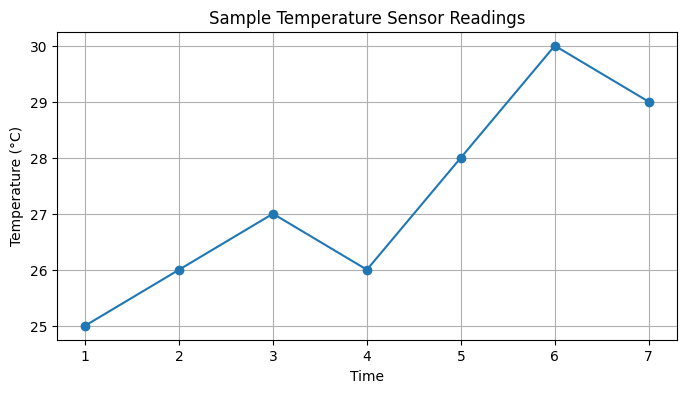

In [7]:
# Test numerical calculations
sensor_values = np.array([25, 26, 27, 26, 28, 30, 29])

print("Sensor readings:", sensor_values)
print("Average temperature:", np.mean(sensor_values))
print("Maximum temperature:", np.max(sensor_values))
print("Minimum temperature:", np.min(sensor_values))

# Test DataFrame creation
data = pd.DataFrame({
    "Time": range(1, 8),
    "Temperature": sensor_values
})

print("\nSensor Data:")
display(data)

# Test graph generation
plt.figure(figsize=(8, 4))

plt.plot(
    data["Time"],
    data["Temperature"],
    marker="o"
)

plt.title("Sample Temperature Sensor Readings")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)

plt.show()


# PHASE 2: SYSTEM ARCHITECTURE AND DESIGN

## 1. Project Objective

To design and simulate an energy-aware adaptive sampling mechanism for IoT sensor networks that dynamically adjusts sampling intervals according to environmental variations.

The objective is to reduce energy consumption while maintaining acceptable environmental monitoring accuracy and event detection performance.

## 2. Proposed System

The proposed system consists of 10 simulated wireless environmental sensor nodes and a central gateway.

Each sensor node monitors temperature and humidity. A sampling controller determines the next sampling interval based on observed environmental variations.

## 3. Sampling Algorithms

### Algorithm 1: Fixed Sampling
Samples are collected at a constant interval of 10 seconds.

### Algorithm 2: Threshold-Based Sampling
The sampling interval is reduced to 1 second when the difference between consecutive observations exceeds a predefined threshold. Otherwise, the interval remains 10 seconds.

### Algorithm 3: Proposed Adaptive Sampling
The sampling interval dynamically changes according to the estimated rate of environmental variation, within a configurable range of 1 to 30 seconds.

## 4. Initial Simulation Parameters

- Number of sensor nodes: 10
- Simulation duration: 3600 seconds
- Ground-truth resolution: 1 second
- Fixed sampling interval: 10 seconds
- Minimum adaptive interval: 1 second
- Maximum adaptive interval: 30 seconds
- Random seed: 42

## 5. Energy Consumption Model

Total energy consumption includes:

- Sensing energy
- Processing energy
- Communication energy
- Idle or sleep energy

All energy values will be calculated using consistent units.

## 6. Performance Evaluation

The algorithms will be compared using:

- Total energy consumption
- Energy savings percentage
- Number of samples
- Mean Absolute Error (MAE)
- Root Mean Square Error (RMSE)
- Event detection delay
- Estimated network lifetime

## 7. Experimental Fairness

All algorithms will use identical environmental input signals, simulation durations, sensor configurations, initial battery capacities and energy model parameters.

Repeated experiments with different random seeds will be conducted to evaluate consistency.

## 8. Simulation Limitations

The initial implementation is a software-based analytical simulation. It does not directly measure physical ESP32 power consumption or simulate a complete wireless communication protocol.


# PHASE 3: ENVIRONMENTAL SENSOR DATA GENERATION

## Objective
Generate realistic synthetic temperature and humidity
time-series data for 10 virtual IoT sensor nodes.

## Dataset components
1. Ground-truth environmental data.
2. Noisy sensor measurement data.
3. Environmental event labels.

## Environmental scenarios
- Stable conditions
- Gradual temperature and humidity changes
- Sudden environmental events
- Oscillating conditions
- Final stable conditions

In [8]:

# =====================================================
# PHASE 3.5: SIMULATION CONFIGURATION
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Network configuration
TOTAL_SENSORS = 10

# Simulation configuration
SIMULATION_DURATION = 3600
TIME_RESOLUTION = 1

# Environmental baseline
BASE_TEMPERATURE = 25.0
BASE_HUMIDITY = 65.0

# Sensor measurement noise
TEMP_NOISE_STD = 0.15
HUMIDITY_NOISE_STD = 0.6

# Sampling configuration
FIXED_INTERVAL = 10
MIN_ADAPTIVE_INTERVAL = 1
MAX_ADAPTIVE_INTERVAL = 30

# Time axis: 0 to 3599 seconds
time = np.arange(
    0,
    SIMULATION_DURATION,
    TIME_RESOLUTION
)

# Verify configuration
print("SIMULATION CONFIGURATION")
print("-" * 40)

print("Total sensors:", TOTAL_SENSORS)
print("Simulation duration:", SIMULATION_DURATION, "seconds")
print("Reference readings:", len(time))
print("Temperature baseline:", BASE_TEMPERATURE, "°C")
print("Humidity baseline:", BASE_HUMIDITY, "%")
print("Random seed:", RANDOM_SEED)

print("\nConfiguration initialized successfully.")


SIMULATION CONFIGURATION
----------------------------------------
Total sensors: 10
Simulation duration: 3600 seconds
Reference readings: 3600
Temperature baseline: 25.0 °C
Humidity baseline: 65.0 %
Random seed: 42

Configuration initialized successfully.


In [9]:

# =====================================================
# PHASE 3.6: TEMPERATURE GROUND-TRUTH GENERATION
# =====================================================

def generate_temperature(time):

    temperature = np.zeros(len(time), dtype=float)

    # Stage 1: Stable conditions (0-600 seconds)
    mask = (time >= 0) & (time < 600)

    temperature[mask] = (
        25.0
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 2: Gradual temperature rise (600-1500)
    mask = (time >= 600) & (time < 1500)

    elapsed = time[mask] - 600

    temperature[mask] = (
        25.0
        + 0.005 * elapsed
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 3: Stable period (1500-2100)
    mask = (time >= 1500) & (time < 2100)

    temperature[mask] = (
        29.5
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 4: Sudden environmental event (2100-2400)
    mask = (time >= 2100) & (time < 2400)

    elapsed = time[mask] - 2100

    temperature[mask] = (
        29.5
        + 0.02 * elapsed
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 5: Oscillating conditions (2400-3000)
    mask = (time >= 2400) & (time < 3000)

    elapsed = time[mask] - 2400

    temperature[mask] = (
        35.5
        + 1.5 * np.sin(2 * np.pi * elapsed / 120)
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 6: Final stable conditions (3000-3600)
    mask = (time >= 3000) & (time < 3600)

    temperature[mask] = (
        35.5
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    return temperature

# Generate temperature ground truth
temperature_truth = generate_temperature(time)

print("Temperature ground-truth signal generated.")
print("Number of readings:", len(temperature_truth))
print("Minimum temperature:", round(np.min(temperature_truth), 2), "°C")
print("Maximum temperature:", round(np.max(temperature_truth), 2), "°C")

Temperature ground-truth signal generated.
Number of readings: 3600
Minimum temperature: 24.85 °C
Maximum temperature: 37.13 °C


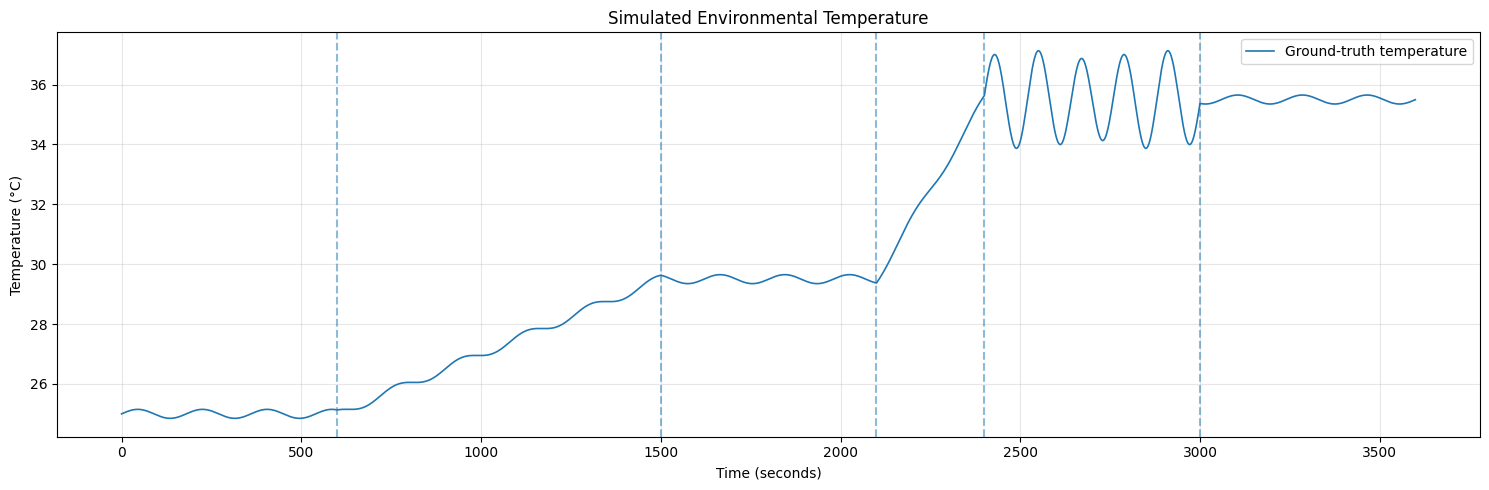

In [10]:

# =====================================================
# TEMPERATURE GROUND-TRUTH VISUALIZATION
# =====================================================

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    temperature_truth,
    linewidth=1.2,
    label="Ground-truth temperature"
)

plt.axvline(600, linestyle="--", alpha=0.5)
plt.axvline(1500, linestyle="--", alpha=0.5)
plt.axvline(2100, linestyle="--", alpha=0.5)
plt.axvline(2400, linestyle="--", alpha=0.5)
plt.axvline(3000, linestyle="--", alpha=0.5)

plt.title("Simulated Environmental Temperature")
plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

# =====================================================
# PHASE 3.7: HUMIDITY GROUND-TRUTH GENERATION
# =====================================================

def generate_humidity(time):

    humidity = np.zeros(len(time), dtype=float)

    # Stage 1: Stable conditions
    mask = (time >= 0) & (time < 600)

    humidity[mask] = (
        65.0
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 2: Gradual humidity decrease
    mask = (time >= 600) & (time < 1500)

    elapsed = time[mask] - 600

    humidity[mask] = (
        65.0
        - 0.006 * elapsed
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 3: Stable period
    mask = (time >= 1500) & (time < 2100)

    humidity[mask] = (
        59.6
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 4: Rapid humidity decrease
    mask = (time >= 2100) & (time < 2400)

    elapsed = time[mask] - 2100

    humidity[mask] = (
        59.6
        - 0.02 * elapsed
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 5: Oscillating humidity
    mask = (time >= 2400) & (time < 3000)

    elapsed = time[mask] - 2400

    humidity[mask] = (
        53.6
        + 2.0 * np.sin(2 * np.pi * elapsed / 120)
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 6: Final stable period
    mask = (time >= 3000) & (time < 3600)

    humidity[mask] = (
        53.6
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    return humidity

# Generate humidity ground truth
humidity_truth = generate_humidity(time)

print("Humidity ground-truth signal generated.")
print("Number of readings:", len(humidity_truth))
print("Minimum humidity:", round(np.min(humidity_truth), 2), "%")
print("Maximum humidity:", round(np.max(humidity_truth), 2), "%")

Humidity ground-truth signal generated.
Number of readings: 3600
Minimum humidity: 51.19 %
Maximum humidity: 65.5 %


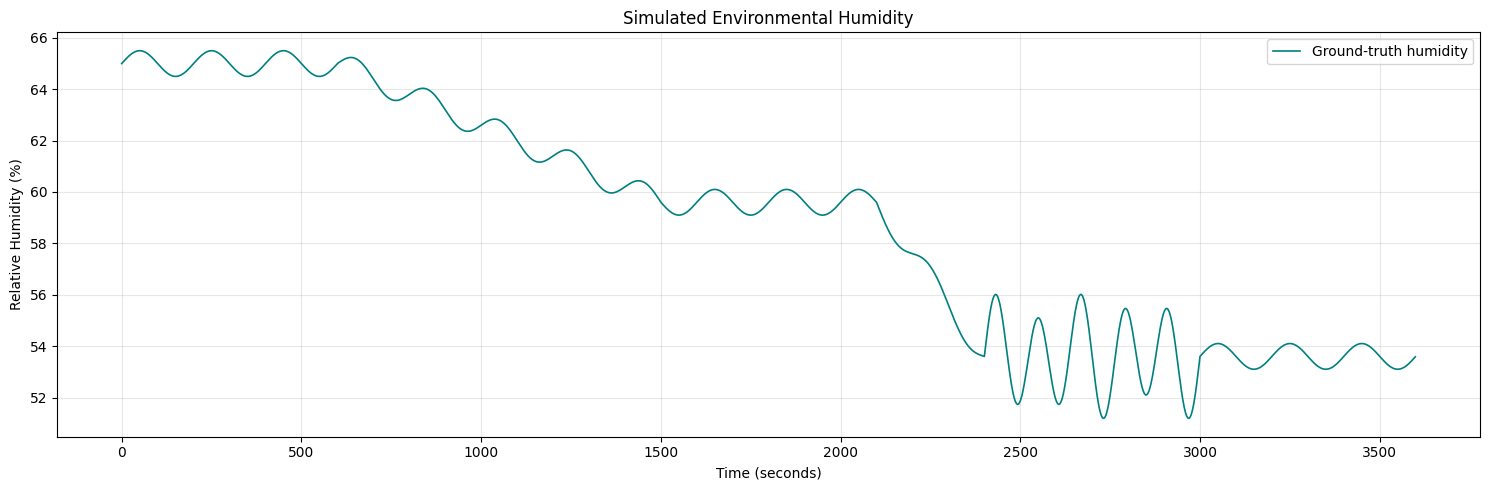

In [12]:

# =====================================================
# HUMIDITY GROUND-TRUTH VISUALIZATION
# =====================================================

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    humidity_truth,
    color="teal",
    linewidth=1.2,
    label="Ground-truth humidity"
)

plt.title("Simulated Environmental Humidity")
plt.xlabel("Time (seconds)")
plt.ylabel("Relative Humidity (%)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

# =====================================================
# PHASE 3.8: GENERATE 10 SENSOR NODE ENVIRONMENTS
# =====================================================

ground_truth_records = []

# Generate individual environmental profiles
for node_id in range(1, TOTAL_SENSORS + 1):

    # Small differences between sensor locations
    temp_offset = rng.normal(0, 0.30)
    humidity_offset = rng.normal(0, 1.00)

    phase = rng.uniform(0, 2 * np.pi)

    # Node-specific slow environmental variation
    local_temp_variation = (
        0.08 * np.sin(
            2 * np.pi * time / 300 + phase
        )
    )

    local_humidity_variation = (
        0.25 * np.sin(
            2 * np.pi * time / 350 + phase
        )
    )

    # Generate node-specific ground truth
    node_temperature = (
        temperature_truth
        + temp_offset
        + local_temp_variation
    )

    node_humidity = (
        humidity_truth
        + humidity_offset
        + local_humidity_variation
    )

    # Keep relative humidity physically valid
    node_humidity = np.clip(node_humidity, 0, 100)

    # Store all readings
    node_data = pd.DataFrame({
        "time_seconds": time,
        "node_id": node_id,
        "temperature_true": node_temperature,
        "humidity_true": node_humidity
    })

    ground_truth_records.append(node_data)

# Combine all nodes into one dataset
ground_truth_df = pd.concat(
    ground_truth_records,
    ignore_index=True
)

print("Ground-truth dataset generated successfully.")

print("Number of sensor nodes:", TOTAL_SENSORS)
print("Total records:", len(ground_truth_df))

display(ground_truth_df.head(10))

Ground-truth dataset generated successfully.
Number of sensor nodes: 10
Total records: 36000


,time_seconds,node_id,temperature_true,humidity_true
0,0,1,25.029327,63.765991
1,1,1,25.035632,63.784558
2,2,1,25.041958,63.803171
3,3,1,25.048297,63.821813
4,4,1,25.054642,63.840469
5,5,1,25.060988,63.859121
6,6,1,25.067326,63.877755
7,7,1,25.073651,63.896352
8,8,1,25.079956,63.914897
9,9,1,25.086233,63.933375


In [14]:

# Compare the average environmental conditions
# across all 10 nodes

node_summary = ground_truth_df.groupby("node_id").agg(
    avg_temperature=("temperature_true", "mean"),
    avg_humidity=("humidity_true", "mean"),
    min_temperature=("temperature_true", "min"),
    max_temperature=("temperature_true", "max")
).round(2)

display(node_summary)


,avg_temperature,avg_humidity,min_temperature,max_temperature
node_id,,,,
1,30.53,57.89,24.89,37.28
2,30.72,56.98,25.07,37.42
3,30.47,58.62,24.81,37.12
4,30.18,59.81,24.55,36.91
5,30.46,60.05,24.82,37.21
6,30.18,59.30,24.51,36.84
7,30.70,58.87,25.04,37.47
8,30.23,60.15,24.61,36.98
9,30.31,58.57,24.68,37.07


In [15]:

# =====================================================
# PHASE 3.9: SENSOR MEASUREMENT NOISE
# =====================================================

sensor_measurements_df = ground_truth_df.copy()

# Add independent measurement noise
sensor_measurements_df["temperature_measured"] = (
    sensor_measurements_df["temperature_true"]
    + rng.normal(
        0,
        TEMP_NOISE_STD,
        len(sensor_measurements_df)
    )
)

sensor_measurements_df["humidity_measured"] = (
    sensor_measurements_df["humidity_true"]
    + rng.normal(
        0,
        HUMIDITY_NOISE_STD,
        len(sensor_measurements_df)
    )
)

# Keep measured humidity within physical limits
sensor_measurements_df["humidity_measured"] = np.clip(
    sensor_measurements_df["humidity_measured"],
    0,
    100
)

print("Noisy sensor measurements generated.")

print(
    "Total sensor measurement records:",
    len(sensor_measurements_df)
)

display(
    sensor_measurements_df[
        [
            "time_seconds",
            "node_id",
            "temperature_true",
            "temperature_measured",
            "humidity_true",
            "humidity_measured"
        ]
    ].head(10)
)


Noisy sensor measurements generated.
Total sensor measurement records: 36000


,time_seconds,node_id,temperature_true,temperature_measured,humidity_true,humidity_measured
0,0,1,25.029327,25.350574,63.765991,63.151837
1,1,1,25.035632,24.974670,63.784558,64.474635
2,2,1,25.041958,24.965121,63.803171,62.912562
3,3,1,25.048297,24.926231,63.821813,63.315618
4,4,1,25.054642,25.147039,63.840469,62.862989
5,5,1,25.060988,25.230334,63.859121,64.110908
6,6,1,25.067326,25.050234,63.877755,63.623430
7,7,1,25.073651,24.947628,63.896352,64.307908
8,8,1,25.079956,24.956283,63.914897,63.329543
9,9,1,25.086233,25.183822,63.933375,64.252260


In [16]:

# =====================================================
# PHASE 3.10: ENVIRONMENTAL SCENARIO LABELING
# =====================================================

def classify_environment(t):

    if t < 600:
        return "Stable"

    elif t < 1500:
        return "Gradual Change"

    elif t < 2100:
        return "Stable"

    elif t < 2400:
        return "Rapid Event"

    elif t < 3000:
        return "Oscillating"

    else:
        return "Stable"

# Add scenario labels
sensor_measurements_df["scenario"] = (
    sensor_measurements_df["time_seconds"]
    .apply(classify_environment)
)

# Add binary event labels
sensor_measurements_df["event_active"] = (
    (
        sensor_measurements_df["time_seconds"] >= 2100
    )
    &
    (
        sensor_measurements_df["time_seconds"] < 2400
    )
).astype(int)

# Display scenario distribution
scenario_summary = (
    sensor_measurements_df
    .groupby("scenario")
    .agg(
        record_count=("time_seconds", "count"),
        event_records=("event_active", "sum")
    )
)

display(scenario_summary)

print("\nScenario labeling completed.")

,record_count,event_records
scenario,,
Gradual Change,9000,0
Oscillating,6000,0
Rapid Event,3000,3000
Stable,18000,0



Scenario labeling completed.


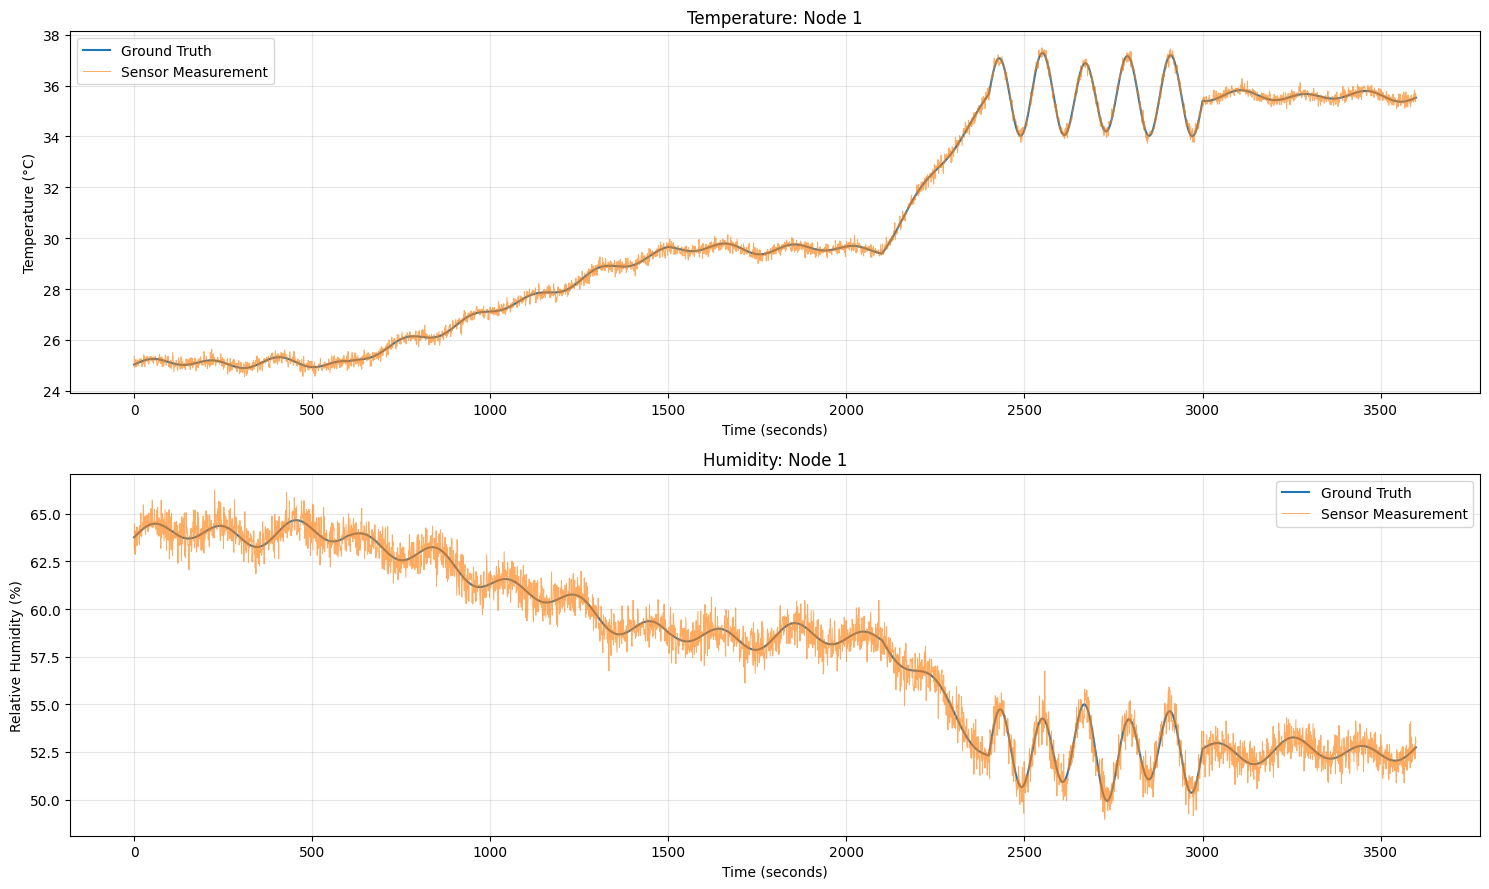

In [17]:

# =====================================================
# PHASE 3.11: COMPLETE DATASET VISUALIZATION
# =====================================================

NODE_TO_VISUALIZE = 1

node_data = sensor_measurements_df[
    sensor_measurements_df["node_id"] == NODE_TO_VISUALIZE
]

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# Temperature
axes[0].plot(
    node_data["time_seconds"],
    node_data["temperature_true"],
    label="Ground Truth",
    linewidth=1.5
)

axes[0].plot(
    node_data["time_seconds"],
    node_data["temperature_measured"],
    label="Sensor Measurement",
    alpha=0.65,
    linewidth=0.7
)

axes[0].set_title("Temperature: Node 1")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Humidity
axes[1].plot(
    node_data["time_seconds"],
    node_data["humidity_true"],
    label="Ground Truth",
    linewidth=1.5
)

axes[1].plot(
    node_data["time_seconds"],
    node_data["humidity_measured"],
    label="Sensor Measurement",
    alpha=0.65,
    linewidth=0.7
)

axes[1].set_title("Humidity: Node 1")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Relative Humidity (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


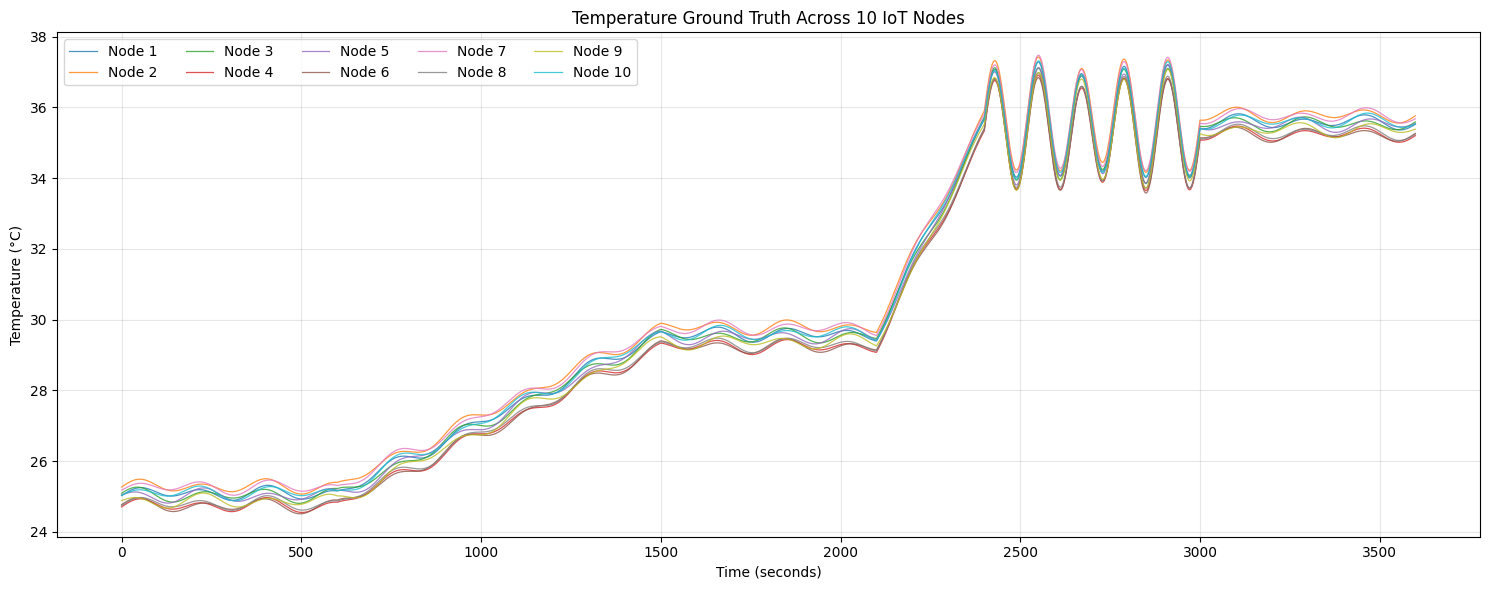

In [18]:

# =====================================================
# TEMPERATURE COMPARISON ACROSS ALL 10 NODES
# =====================================================

plt.figure(figsize=(15, 6))

for node_id in range(1, TOTAL_SENSORS + 1):

    node_data = ground_truth_df[
        ground_truth_df["node_id"] == node_id
    ]

    plt.plot(
        node_data["time_seconds"],
        node_data["temperature_true"],
        linewidth=0.9,
        alpha=0.8,
        label=f"Node {node_id}"
    )

plt.title("Temperature Ground Truth Across 10 IoT Nodes")
plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")
plt.legend(ncol=5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

# =====================================================
# PHASE 3.12: DATASET VALIDATION
# =====================================================

print("=" * 55)
print("DATASET VALIDATION REPORT")
print("=" * 55)

# 1. Record count
print("\n1. Total records:")
print(len(sensor_measurements_df))

# 2. Number of nodes
print("\n2. Unique sensor nodes:")
print(sensor_measurements_df["node_id"].nunique())

# 3. Missing values
print("\n3. Missing values:")
print(sensor_measurements_df.isnull().sum())

# 4. Duplicate timestamps per node
duplicates = sensor_measurements_df.duplicated(
    subset=["node_id", "time_seconds"]
).sum()

print("\n4. Duplicate node-timestamp records:")
print(duplicates)

# 5. Humidity validity
humidity_valid = (
    sensor_measurements_df["humidity_true"].between(0, 100).all()
    and
    sensor_measurements_df["humidity_measured"].between(0, 100).all()
)

print("\n5. Humidity values within 0-100%:")
print(humidity_valid)

# 6. Measurement noise statistics
temp_error = (
    sensor_measurements_df["temperature_measured"]
    - sensor_measurements_df["temperature_true"]
)

humidity_error = (
    sensor_measurements_df["humidity_measured"]
    - sensor_measurements_df["humidity_true"]
)

print("\n6. Actual measurement noise:")
print("Temperature noise STD:", round(temp_error.std(), 4))
print("Humidity noise STD:", round(humidity_error.std(), 4))

# 7. Final validation
validation_passed = (
    len(sensor_measurements_df) == 36000
    and sensor_measurements_df["node_id"].nunique() == 10
    and sensor_measurements_df.isnull().sum().sum() == 0
    and duplicates == 0
    and humidity_valid
)

print("\n" + "=" * 55)

if validation_passed:
    print("DATASET STRUCTURAL VALIDATION PASSED")
else:
    print("DATASET VALIDATION FAILED - INVESTIGATE ERRORS")

print("=" * 55)


DATASET VALIDATION REPORT

1. Total records:
36000

2. Unique sensor nodes:
10

3. Missing values:
time_seconds            0
node_id                 0
temperature_true        0
humidity_true           0
temperature_measured    0
humidity_measured       0
scenario                0
event_active            0
dtype: int64

4. Duplicate node-timestamp records:
0

5. Humidity values within 0-100%:
True

6. Actual measurement noise:
Temperature noise STD: 0.1506
Humidity noise STD: 0.6017

DATASET STRUCTURAL VALIDATION PASSED


In [20]:

# =====================================================
# PHASE 3.13: PREPARE FINAL DATASETS
# =====================================================

# Add environmental scenario labels to ground truth
ground_truth_df["scenario"] = (
    ground_truth_df["time_seconds"].apply(classify_environment)
)

ground_truth_df["event_active"] = (
    (
        ground_truth_df["time_seconds"] >= 2100
    )
    &
    (
        ground_truth_df["time_seconds"] < 2400
    )
).astype(int)

# Select and organize ground-truth columns
ground_truth_df = ground_truth_df[
    [
        "time_seconds",
        "node_id",
        "temperature_true",
        "humidity_true",
        "scenario",
        "event_active"
    ]
]

# Organize sensor measurement columns
sensor_measurements_df = sensor_measurements_df[
    [
        "time_seconds",
        "node_id",
        "temperature_true",
        "temperature_measured",
        "humidity_true",
        "humidity_measured",
        "scenario",
        "event_active"
    ]
]

print("Both datasets prepared successfully.")

print("\nGround truth:")
display(ground_truth_df.head())

print("\nSensor measurements:")
display(sensor_measurements_df.head())


Both datasets prepared successfully.

Ground truth:


,time_seconds,node_id,temperature_true,humidity_true,scenario,event_active
0,0,1,25.029327,63.765991,Stable,0
1,1,1,25.035632,63.784558,Stable,0
2,2,1,25.041958,63.803171,Stable,0
3,3,1,25.048297,63.821813,Stable,0
4,4,1,25.054642,63.840469,Stable,0



Sensor measurements:


,time_seconds,node_id,temperature_true,temperature_measured,humidity_true,humidity_measured,scenario,event_active
0,0,1,25.029327,25.350574,63.765991,63.151837,Stable,0
1,1,1,25.035632,24.974670,63.784558,64.474635,Stable,0
2,2,1,25.041958,24.965121,63.803171,62.912562,Stable,0
3,3,1,25.048297,24.926231,63.821813,63.315618,Stable,0
4,4,1,25.054642,25.147039,63.840469,62.862989,Stable,0


In [21]:

# =====================================================
# CREATE DATASET STORAGE DIRECTORY
# =====================================================

import os

DATASET_PATH = "/content/datasets"

os.makedirs(DATASET_PATH, exist_ok=True)

print("Dataset directory created:")
print(DATASET_PATH)


Dataset directory created:
/content/datasets


In [22]:

# =====================================================
# EXPORT DATASETS
# =====================================================

ground_truth_file = os.path.join(
    DATASET_PATH,
    "ground_truth.csv"
)

sensor_measurements_file = os.path.join(
    DATASET_PATH,
    "sensor_measurements.csv"
)

ground_truth_df.to_csv(
    ground_truth_file,
    index=False
)

sensor_measurements_df.to_csv(
    sensor_measurements_file,
    index=False
)

print("DATASETS EXPORTED SUCCESSFULLY")

print("\nGround truth:")
print(ground_truth_file)

print("\nSensor measurements:")
print(sensor_measurements_file)

print("\nFile sizes:")

print(
    "Ground truth:",
    round(os.path.getsize(ground_truth_file) / 1024, 2),
    "KB"
)

print(
    "Sensor measurements:",
    round(os.path.getsize(sensor_measurements_file) / 1024, 2),
    "KB"
)


DATASETS EXPORTED SUCCESSFULLY

Ground truth:
/content/datasets/ground_truth.csv

Sensor measurements:
/content/datasets/sensor_measurements.csv

File sizes:
Ground truth: 1956.06 KB
Sensor measurements: 3242.66 KB


In [23]:

# Download both datasets to your computer

from google.colab import files

files.download(ground_truth_file)
files.download(sensor_measurements_file)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# PHASE 4: IMPLEMENTATION OF SAMPLING ALGORITHMS

This phase implements and compares three sampling strategies:
1. Fixed Interval Sampling
2. Threshold-Based Adaptive Sampling
3. Proposed Rate-Based Adaptive Sampling

All algorithms use the same simulated sensor measurements to ensure a fair comparison.

In [24]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset file paths
ground_truth_file = "/content/datasets/ground_truth.csv"
sensor_data_file = "/content/datasets/sensor_measurements.csv"

# Check whether files exist
print("Ground truth file exists:", os.path.exists(ground_truth_file))
print("Sensor data file exists:", os.path.exists(sensor_data_file))

# Load datasets
ground_truth_df = pd.read_csv(ground_truth_file)
sensor_measurements_df = pd.read_csv(sensor_data_file)

# Sort sensor readings
sensor_measurements_df = sensor_measurements_df.sort_values(
    by=["node_id", "time_seconds"]
).reset_index(drop=True)

print("\nGround truth shape:", ground_truth_df.shape)
print("Sensor measurements shape:", sensor_measurements_df.shape)

print("\nFirst five sensor readings:")
display(sensor_measurements_df.head())

Ground truth file exists: True
Sensor data file exists: True

Ground truth shape: (36000, 6)
Sensor measurements shape: (36000, 8)

First five sensor readings:


,time_seconds,node_id,temperature_true,temperature_measured,humidity_true,humidity_measured,scenario,event_active
0,0,1,25.029327,25.350574,63.765991,63.151837,Stable,0
1,1,1,25.035632,24.974670,63.784558,64.474635,Stable,0
2,2,1,25.041958,24.965121,63.803171,62.912562,Stable,0
3,3,1,25.048297,24.926231,63.821813,63.315618,Stable,0
4,4,1,25.054642,25.147039,63.840469,62.862989,Stable,0


In [25]:
FIXED_INTERVAL = 10

def fixed_sampling(data, interval=FIXED_INTERVAL):

    sampled_data = data[
        data["time_seconds"] % interval == 0
    ].copy()

    return sampled_data.reset_index(drop=True)

# Run fixed sampling
fixed_samples = fixed_sampling(sensor_measurements_df)

print("FIXED SAMPLING RESULTS")
print("----------------------")
print("Total original readings:", len(sensor_measurements_df))
print("Total sampled readings:", len(fixed_samples))
print("Number of sensor nodes:", fixed_samples["node_id"].nunique())

print("\nSamples per node:")
print(fixed_samples.groupby("node_id").size())

FIXED SAMPLING RESULTS
----------------------
Total original readings: 36000
Total sampled readings: 3600
Number of sensor nodes: 10

Samples per node:
node_id
1     360
2     360
3     360
4     360
5     360
6     360
7     360
8     360
9     360
10    360
dtype: int64


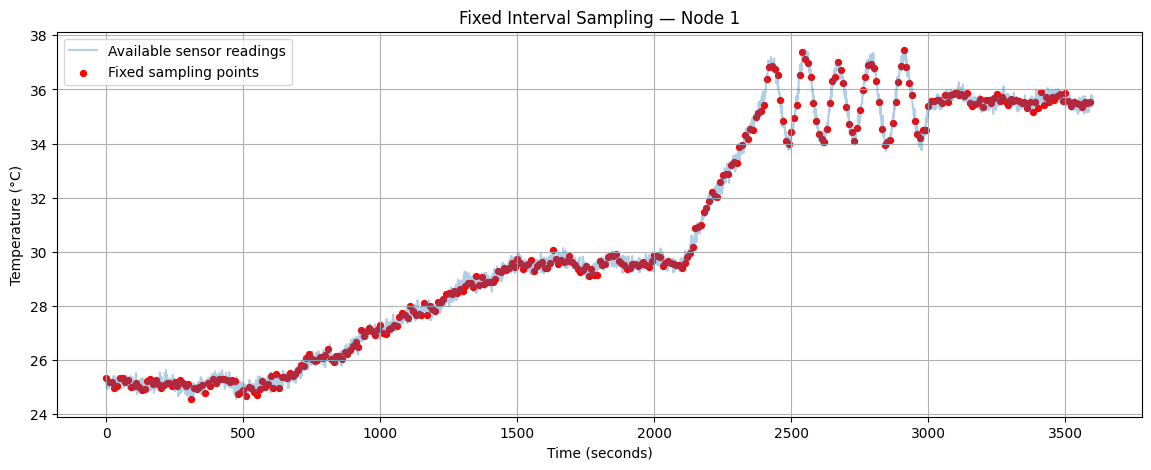

In [26]:
# Select Node 1
node1_data = sensor_measurements_df[
    sensor_measurements_df["node_id"] == 1
]

node1_fixed = fixed_samples[
    fixed_samples["node_id"] == 1
]

plt.figure(figsize=(14, 5))

plt.plot(
    node1_data["time_seconds"],
    node1_data["temperature_measured"],
    label="Available sensor readings",
    alpha=0.35
)

plt.scatter(
    node1_fixed["time_seconds"],
    node1_fixed["temperature_measured"],
    color="red",
    s=18,
    label="Fixed sampling points"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")
plt.title("Fixed Interval Sampling — Node 1")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
assert len(fixed_samples) == 3600
assert fixed_samples["node_id"].nunique() == 10

assert (
    fixed_samples.groupby("node_id").size() == 360
).all()

assert (
    fixed_samples["time_seconds"] % FIXED_INTERVAL == 0
).all()

print("Fixed sampling validation: PASSED")

Fixed sampling validation: PASSED


## 4.2 Threshold-Based Adaptive Sampling

This algorithm reduces unnecessary sensor transmissions
by transmitting measurements only when temperature or
humidity changes exceed predefined thresholds.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load sensor measurements
df = pd.read_csv('/content/datasets/sensor_measurements.csv')

# Sort measurements
df = df.sort_values(['node_id', 'time_seconds']).reset_index(drop=True)

# Experimental thresholds
TEMP_THRESHOLD = 0.5
HUMIDITY_THRESHOLD = 2.0

# Store transmitted readings
transmitted = []

# Process each sensor node independently
for node_id, node_data in df.groupby('node_id'):

    previous_temp = None
    previous_humidity = None

    for _, row in node_data.iterrows():

        current_temp = row['temperature']
        current_humidity = row['humidity']

        # Always transmit the first reading
        if previous_temp is None:

            transmit = True

        else:

            temp_change = abs(current_temp - previous_temp)
            humidity_change = abs(current_humidity - previous_humidity)

            transmit = (
                temp_change >= TEMP_THRESHOLD or
                humidity_change >= HUMIDITY_THRESHOLD
            )

        if transmit:

            transmitted.append(row.to_dict())

            previous_temp = current_temp
            previous_humidity = current_humidity

# Convert transmitted readings into DataFrame
threshold_df = pd.DataFrame(transmitted)

print("Threshold-based sampling completed")
print("Original readings:", len(df))
print("Transmitted readings:", len(threshold_df))
print("Reduction (%):",
      round((1 - len(threshold_df) / len(df)) * 100, 2))

print("\nReadings per node:")
print(threshold_df.groupby('node_id').size())

KeyError: 'temperature'

In [31]:
import pandas as pd

df = pd.read_csv('/content/datasets/sensor_measurements.csv')

print("Dataset shape:", df.shape)

print("\nActual column names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (36000, 8)

Actual column names:
['time_seconds', 'node_id', 'temperature_true', 'temperature_measured', 'humidity_true', 'humidity_measured', 'scenario', 'event_active']

First 5 rows:


,time_seconds,node_id,temperature_true,temperature_measured,humidity_true,humidity_measured,scenario,event_active
0,0,1,25.029327,25.350574,63.765991,63.151837,Stable,0
1,1,1,25.035632,24.974670,63.784558,64.474635,Stable,0
2,2,1,25.041958,24.965121,63.803171,62.912562,Stable,0
3,3,1,25.048297,24.926231,63.821813,63.315618,Stable,0
4,4,1,25.054642,25.147039,63.840469,62.862989,Stable,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36000 entries, 0 to 35999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time_seconds          36000 non-null  int64  
 1   node_id               36000 non-null  int64  
 2   temperature_true      36000 non-null  float64
 3   temperature_measured  36000 non-null  float64
 4   humidity_true         36000 non-null  float64
 5   humidity_measured     36000 non-null  float64
 6   scenario              36000 non-null  object 
 7   event_active          36000 non-null  int64  
dtypes: float64(4), int64(3), object(1)
memory usage: 2.2+ MB


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load sensor measurements
df = pd.read_csv('/content/datasets/sensor_measurements.csv')

# Sort measurements
df = df.sort_values(
    ['node_id', 'time_seconds']
).reset_index(drop=True)

# Experimental thresholds
TEMP_THRESHOLD = 0.5
HUMIDITY_THRESHOLD = 2.0

# Store transmitted readings
transmitted = []

# Process each sensor node independently
for node_id, node_data in df.groupby('node_id'):

    previous_temp = None
    previous_humidity = None

    for _, row in node_data.iterrows():

        current_temp = row['temperature_measured']
        current_humidity = row['humidity_measured']

        # Always transmit first reading
        if previous_temp is None:
            transmit = True

        else:
            temp_change = abs(current_temp - previous_temp)
            humidity_change = abs(current_humidity - previous_humidity)

            transmit = (
                temp_change >= TEMP_THRESHOLD or
                humidity_change >= HUMIDITY_THRESHOLD
            )

        if transmit:
            transmitted.append(row.to_dict())

            previous_temp = current_temp
            previous_humidity = current_humidity

# Convert transmitted readings into DataFrame
threshold_df = pd.DataFrame(transmitted)

# Sort final output
threshold_df = threshold_df.sort_values(
    ['node_id', 'time_seconds']
).reset_index(drop=True)

# Results
original_count = len(df)
transmitted_count = len(threshold_df)

reduction = (
    1 - transmitted_count / original_count
) * 100

print("THRESHOLD-BASED ADAPTIVE SAMPLING")
print("--------------------------------")
print("Original readings:", original_count)
print("Transmitted readings:", transmitted_count)
print("Reduction (%):", round(reduction, 2))

print("\nReadings per node:")
print(threshold_df.groupby('node_id').size())

THRESHOLD-BASED ADAPTIVE SAMPLING
--------------------------------
Original readings: 36000
Transmitted readings: 2275
Reduction (%): 93.68

Readings per node:
node_id
1     226
2     218
3     191
4     220
5     222
6     261
7     256
8     224
9     247
10    210
dtype: int64


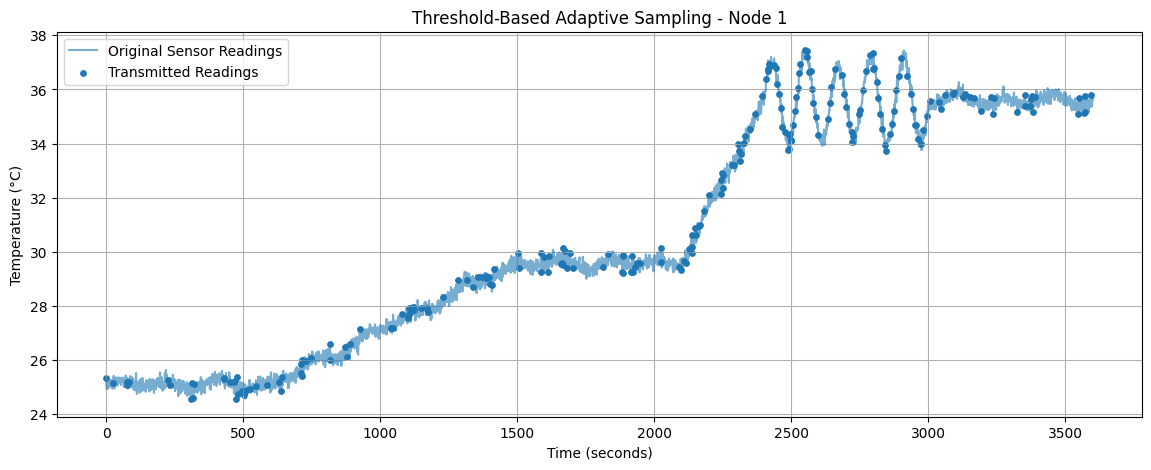

In [33]:
node = 1

original = df[df['node_id'] == node]
sampled = threshold_df[threshold_df['node_id'] == node]

plt.figure(figsize=(14, 5))

plt.plot(
    original['time_seconds'],
    original['temperature_measured'],
    label='Original Sensor Readings',
    alpha=0.6
)

plt.scatter(
    sampled['time_seconds'],
    sampled['temperature_measured'],
    label='Transmitted Readings',
    s=15
)

plt.xlabel('Time (seconds)')
plt.ylabel('Temperature (°C)')
plt.title('Threshold-Based Adaptive Sampling - Node 1')

plt.legend()
plt.grid(True)
plt.show()

In [34]:
# Validation checks

assert len(threshold_df) > 0

assert threshold_df['node_id'].nunique() == 10

assert threshold_df.groupby('node_id').size().max() <= 3600

# Check chronological ordering for every node
for node_id, group in threshold_df.groupby('node_id'):
    assert group['time_seconds'].is_monotonic_increasing

# Check first reading of every node is transmitted
for node_id, group in df.groupby('node_id'):
    first_time = group['time_seconds'].iloc[0]

    transmitted_times = threshold_df[
        threshold_df['node_id'] == node_id
    ]['time_seconds'].values

    assert first_time in transmitted_times

print("All threshold-based sampling validation checks PASSED!")

All threshold-based sampling validation checks PASSED!


## 4.3 Rate-Based Adaptive Sampling

This algorithm dynamically adjusts sensor transmission
intervals according to the rate of environmental change.

A five-second observation window is used to estimate
temperature and humidity variation rates.

In [35]:
# Calculate five-second rates of change

rate_df = df.sort_values(
    ['node_id', 'time_seconds']
).copy()

# Previous measurements from 5 seconds earlier
rate_df['previous_temp'] = (
    rate_df.groupby('node_id')['temperature_measured'].shift(5)
)

rate_df['previous_humidity'] = (
    rate_df.groupby('node_id')['humidity_measured'].shift(5)
)

# Calculate absolute rates per second
rate_df['temp_rate'] = (
    abs(rate_df['temperature_measured'] - rate_df['previous_temp']) / 5
)

rate_df['humidity_rate'] = (
    abs(rate_df['humidity_measured'] - rate_df['previous_humidity']) / 5
)

# Remove initial rows without previous measurements
valid_rates = rate_df.dropna(
    subset=['temp_rate', 'humidity_rate']
)

print("TEMPERATURE RATE DISTRIBUTION")
print(valid_rates['temp_rate'].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95]
))

print("\nHUMIDITY RATE DISTRIBUTION")
print(valid_rates['humidity_rate'].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95]
))

TEMPERATURE RATE DISTRIBUTION
count    3.595000e+04
mean     3.856040e-02
std      3.012255e-02
min      9.134440e-07
50%      3.196896e-02
75%      5.534566e-02
90%      8.028413e-02
95%      9.676907e-02
max      2.088193e-01
Name: temp_rate, dtype: float64

HUMIDITY RATE DISTRIBUTION
count    35950.000000
mean         0.138126
std          0.104576
min          0.000007
50%          0.116910
75%          0.199380
90%          0.285804
95%          0.338925
max          0.711354
Name: humidity_rate, dtype: float64


In [36]:
# RATE-BASED ADAPTIVE SAMPLING

import pandas as pd
import numpy as np

# Sampling intervals
LOW_INTERVAL = 30
MEDIUM_INTERVAL = 10
HIGH_INTERVAL = 2

# Rate thresholds
TEMP_MEDIUM = 0.05534566
TEMP_HIGH = 0.08028413

HUMIDITY_MEDIUM = 0.199380
HUMIDITY_HIGH = 0.285804

WINDOW = 5

# Prepare dataset
rate_df = df.sort_values(
    ['node_id', 'time_seconds']
).copy()

transmitted_rate = []

# Process every sensor independently
for node_id, node_data in rate_df.groupby('node_id'):

    node_data = node_data.reset_index(drop=True)

    last_transmission_time = None

    for i, row in node_data.iterrows():

        current_time = row['time_seconds']
        current_temp = row['temperature_measured']
        current_humidity = row['humidity_measured']

        # First measurement
        if i == 0:
            interval = HIGH_INTERVAL
            transmit = True

        else:

            # Calculate environmental rates
            if i >= WINDOW:

                previous_row = node_data.iloc[i - WINDOW]

                temp_rate = abs(
                    current_temp -
                    previous_row['temperature_measured']
                ) / WINDOW

                humidity_rate = abs(
                    current_humidity -
                    previous_row['humidity_measured']
                ) / WINDOW

            else:
                temp_rate = 0
                humidity_rate = 0

            # Determine sampling interval
            if (
                temp_rate >= TEMP_HIGH or
                humidity_rate >= HUMIDITY_HIGH
            ):
                interval = HIGH_INTERVAL

            elif (
                temp_rate >= TEMP_MEDIUM or
                humidity_rate >= HUMIDITY_MEDIUM
            ):
                interval = MEDIUM_INTERVAL

            else:
                interval = LOW_INTERVAL

            # Decide whether to transmit
            transmit = (
                current_time - last_transmission_time >= interval
            )

        if transmit:

            transmitted_rate.append({
                **row.to_dict(),
                'temp_rate': temp_rate if i > 0 else 0,
                'humidity_rate': humidity_rate if i > 0 else 0,
                'sampling_interval': interval
            })

            last_transmission_time = current_time

# Convert results
rate_based_df = pd.DataFrame(transmitted_rate)

# Calculate performance
original_count = len(df)
transmitted_count = len(rate_based_df)

reduction = (
    1 - transmitted_count / original_count
) * 100

print("RATE-BASED ADAPTIVE SAMPLING")
print("--------------------------------")

print("Original readings:", original_count)
print("Transmitted readings:", transmitted_count)

print("Transmission reduction (%):", round(reduction, 2))

print("\nSampling interval distribution:")

print(
    rate_based_df['sampling_interval'].value_counts().sort_index()
)

print("\nReadings per node:")

print(rate_based_df.groupby('node_id').size())

RATE-BASED ADAPTIVE SAMPLING
--------------------------------
Original readings: 36000
Transmitted readings: 6320
Transmission reduction (%): 82.44

Sampling interval distribution:
sampling_interval
2     5526
10     794
Name: count, dtype: int64

Readings per node:
node_id
1     641
2     617
3     615
4     642
5     632
6     633
7     628
8     648
9     623
10    641
dtype: int64


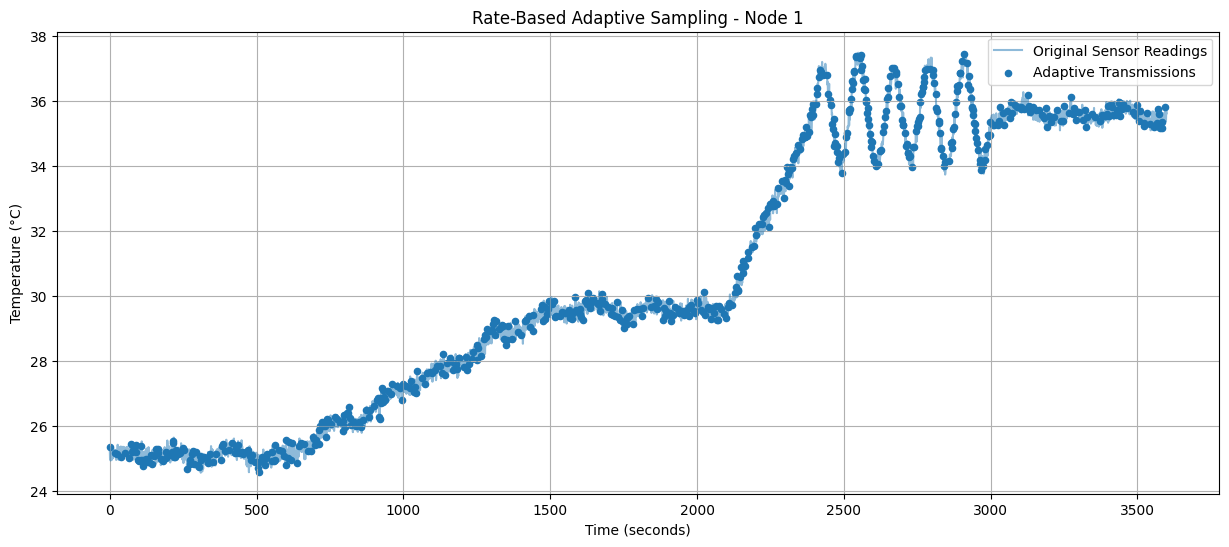

In [37]:
node = 1

original = df[df['node_id'] == node]

sampled = rate_based_df[
    rate_based_df['node_id'] == node
]

plt.figure(figsize=(15, 6))

plt.plot(
    original['time_seconds'],
    original['temperature_measured'],
    label='Original Sensor Readings',
    alpha=0.5
)

plt.scatter(
    sampled['time_seconds'],
    sampled['temperature_measured'],
    label='Adaptive Transmissions',
    s=20
)

plt.xlabel('Time (seconds)')
plt.ylabel('Temperature (°C)')

plt.title(
    'Rate-Based Adaptive Sampling - Node 1'
)

plt.legend()
plt.grid(True)
plt.show()

In [38]:
# Validation

assert len(rate_based_df) > 0

assert rate_based_df['node_id'].nunique() == 10

# First reading must be transmitted for every node
for node_id, group in df.groupby('node_id'):

    first_time = group['time_seconds'].min()

    transmitted_times = rate_based_df[
        rate_based_df['node_id'] == node_id
    ]['time_seconds'].values

    assert first_time in transmitted_times

# Verify chronological ordering
for node_id, group in rate_based_df.groupby('node_id'):

    assert group['time_seconds'].is_monotonic_increasing

# Verify sampling intervals
assert rate_based_df['sampling_interval'].isin(
    [2, 10, 30]
).all()

print("Rate-based adaptive sampling validation: PASSED")

Rate-based adaptive sampling validation: PASSED


## Phase 5: Comparative Performance Evaluation

### 5.1 Transmission Performance

Compare fixed, threshold-based, and rate-based
sampling using total transmissions and
communication reduction percentage.

In [39]:
# PHASE 5.1 - TRANSMISSION COMPARISON

original_count = len(df)

algorithms = {
    'Fixed Sampling': fixed_samples,
    'Threshold-Based': threshold_df,
    'Rate-Based': rate_based_df
}

results = []

for name, samples in algorithms.items():

    total_transmissions = len(samples)

    reduction = (
        1 - total_transmissions / original_count
    ) * 100

    results.append({
        'Algorithm': name,
        'Original Readings': original_count,
        'Transmissions': total_transmissions,
        'Reduction (%)': round(reduction, 2)
    })

comparison_df = pd.DataFrame(results)

print("TRANSMISSION PERFORMANCE COMPARISON")
display(comparison_df)

TRANSMISSION PERFORMANCE COMPARISON


,Algorithm,Original Readings,Transmissions,Reduction (%)
0,Fixed Sampling,36000,3600,90.00
1,Threshold-Based,36000,2275,93.68
2,Rate-Based,36000,6320,82.44


In [40]:
node_comparison = pd.DataFrame({
    'Fixed': fixed_samples.groupby('node_id').size(),
    'Threshold': threshold_df.groupby('node_id').size(),
    'Rate-Based': rate_based_df.groupby('node_id').size()
}).fillna(0).astype(int)

print("TRANSMISSIONS PER SENSOR NODE")
display(node_comparison)

TRANSMISSIONS PER SENSOR NODE


,Fixed,Threshold,Rate-Based
node_id,,,
1,360,226,641
2,360,218,617
3,360,191,615
4,360,220,642
5,360,222,632
6,360,261,633
7,360,256,628
8,360,224,648
9,360,247,623


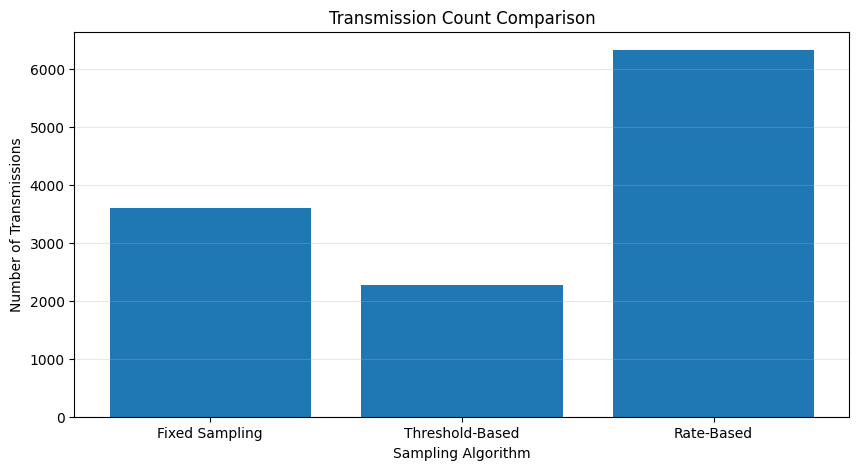

In [41]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df['Algorithm'],
    comparison_df['Transmissions']
)

plt.xlabel('Sampling Algorithm')
plt.ylabel('Number of Transmissions')

plt.title('Transmission Count Comparison')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [42]:
# Basic comparison validation

assert len(comparison_df) == 3

assert all(
    0 <= value <= 100
    for value in comparison_df['Reduction (%)']
)

assert comparison_df['Transmissions'].min() > 0

assert node_comparison.shape[0] == 10

print("Phase 5.1 validation: PASSED")

Phase 5.1 validation: PASSED


## 5.2 Data Accuracy and Event Detection

Evaluate the accuracy of reconstructed environmental
measurements and the ability of each sampling algorithm
to detect environmental events.

Metrics:
- Mean Absolute Error (MAE)
- Root Mean Square Error (RMSE)
- Event Detection Rate

In [43]:
# PHASE 5.2 - DATA RECONSTRUCTION

def reconstruct_data(original_df, sampled_df):

    reconstructed_nodes = []

    for node_id, original_node in original_df.groupby('node_id'):

        sampled_node = sampled_df[
            sampled_df['node_id'] == node_id
        ].sort_values('time_seconds')

        original_node = original_node.sort_values(
            'time_seconds'
        )

        # Match each original timestamp with the latest
        # available transmitted measurement.

        reconstructed = pd.merge_asof(
            original_node,
            sampled_node[
                ['time_seconds',
                 'temperature_measured',
                 'humidity_measured']
            ],
            on='time_seconds',
            direction='backward',
            suffixes=('', '_reconstructed')
        )

        reconstructed_nodes.append(reconstructed)

    return pd.concat(
        reconstructed_nodes,
        ignore_index=True
    )

In [44]:
# Reconstruct all three algorithms

fixed_reconstructed = reconstruct_data(
    df, fixed_samples
)

threshold_reconstructed = reconstruct_data(
    df, threshold_df
)

rate_reconstructed = reconstruct_data(
    df, rate_based_df
)

# Accuracy calculation

from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_accuracy(reconstructed):

    temp_mae = mean_absolute_error(
        reconstructed['temperature_true'],
        reconstructed['temperature_measured_reconstructed']
    )

    temp_rmse = np.sqrt(mean_squared_error(
        reconstructed['temperature_true'],
        reconstructed['temperature_measured_reconstructed']
    ))

    humidity_mae = mean_absolute_error(
        reconstructed['humidity_true'],
        reconstructed['humidity_measured_reconstructed']
    )

    humidity_rmse = np.sqrt(mean_squared_error(
        reconstructed['humidity_true'],
        reconstructed['humidity_measured_reconstructed']
    ))

    return {
        'Temperature MAE': temp_mae,
        'Temperature RMSE': temp_rmse,
        'Humidity MAE': humidity_mae,
        'Humidity RMSE': humidity_rmse
    }


accuracy_results = []

for name, reconstructed in {
    'Fixed Sampling': fixed_reconstructed,
    'Threshold-Based': threshold_reconstructed,
    'Rate-Based': rate_reconstructed
}.items():

    result = calculate_accuracy(reconstructed)

    result['Algorithm'] = name

    accuracy_results.append(result)


accuracy_df = pd.DataFrame(accuracy_results)

print("DATA ACCURACY COMPARISON")

display(
    accuracy_df.round(5)
)

DATA ACCURACY COMPARISON


,Temperature MAE,Temperature RMSE,Humidity MAE,Humidity RMSE,Algorithm
0,0.14574,0.19525,0.49467,0.62459,Fixed Sampling
1,0.14768,0.18072,0.56818,0.69043,Threshold-Based
2,0.15160,0.18547,0.63853,0.76914,Rate-Based


In [45]:
# PHASE 5.2 - EVENT DETECTION

def evaluate_events(original_df, sampled_df):

    total_events = 0
    detected_events = 0

    for node_id, original_node in original_df.groupby('node_id'):

        original_node = original_node.sort_values(
            'time_seconds'
        ).copy()

        # Identify separate event episodes
        event_mask = original_node['event_active'].eq(1)

        episode_id = (
            event_mask.ne(event_mask.shift(fill_value=False))
            .cumsum()
        )

        event_rows = original_node[event_mask].copy()

        if event_rows.empty:
            continue

        event_rows['episode_id'] = episode_id[event_mask]

        sampled_node = sampled_df[
            sampled_df['node_id'] == node_id
        ]

        transmitted_times = set(
            sampled_node['time_seconds']
        )

        for episode, episode_data in event_rows.groupby(
            'episode_id'
        ):

            total_events += 1

            event_times = set(
                episode_data['time_seconds']
            )

            if event_times.intersection(transmitted_times):
                detected_events += 1

    detection_rate = (
        detected_events / total_events * 100
        if total_events > 0 else 0
    )

    return {
        'Total Events': total_events,
        'Detected Events': detected_events,
        'Missed Events': total_events - detected_events,
        'Detection Rate (%)': detection_rate
    }


event_results = []

for name, samples in {
    'Fixed Sampling': fixed_samples,
    'Threshold-Based': threshold_df,
    'Rate-Based': rate_based_df
}.items():

    result = evaluate_events(df, samples)

    result['Algorithm'] = name

    event_results.append(result)


event_df = pd.DataFrame(event_results)

print("EVENT DETECTION COMPARISON")

display(event_df.round(2))

EVENT DETECTION COMPARISON


,Total Events,Detected Events,Missed Events,Detection Rate (%),Algorithm
0,10,10,0,100.0,Fixed Sampling
1,10,10,0,100.0,Threshold-Based
2,10,10,0,100.0,Rate-Based


In [46]:
# PHASE 5.2 VALIDATION

assert len(fixed_reconstructed) == len(df)

assert len(threshold_reconstructed) == len(df)

assert len(rate_reconstructed) == len(df)

assert accuracy_df.shape[0] == 3

assert event_df.shape[0] == 3

assert accuracy_df.notna().all().all()

assert event_df['Detection Rate (%)'].between(
    0, 100
).all()

print("Phase 5.2 validation: PASSED")

Phase 5.2 validation: PASSED


## 5.3 Energy Consumption Modelling

Estimate the energy consumption of fixed,
threshold-based and rate-based sampling.

Energy components:
1. Sensor measurement energy
2. Algorithm processing energy
3. Radio transmission energy
4. Gateway reception energy

The model uses configurable experimental
energy parameters.

In [47]:
# PHASE 5.3 - ENERGY CONSUMPTION MODEL

# Experimental energy parameters (mJ)

SENSING_ENERGY = 0.5
PROCESSING_ENERGY = 0.2
TRANSMISSION_ENERGY = 50.0
RECEPTION_ENERGY = 10.0

# Original measurements
total_measurements = len(df)

# Algorithms
algorithms = {
    'Fixed Sampling': fixed_samples,
    'Threshold-Based': threshold_df,
    'Rate-Based': rate_based_df
}

energy_results = []

for name, samples in algorithms.items():

    transmissions = len(samples)

    # Sensing energy
    sensing_energy = (
        total_measurements * SENSING_ENERGY
    )

    # Processing energy
    processing_energy = (
        total_measurements * PROCESSING_ENERGY
    )

    # Radio transmission energy
    transmission_energy = (
        transmissions * TRANSMISSION_ENERGY
    )

    # Gateway reception energy
    reception_energy = (
        transmissions * RECEPTION_ENERGY
    )

    # Total energy
    total_energy = (
        sensing_energy +
        processing_energy +
        transmission_energy +
        reception_energy
    )

    energy_results.append({

        'Algorithm': name,

        'Sensing Energy (J)': sensing_energy / 1000,

        'Processing Energy (J)': processing_energy / 1000,

        'Transmission Energy (J)': transmission_energy / 1000,

        'Reception Energy (J)': reception_energy / 1000,

        'Total Energy (J)': total_energy / 1000

    })


energy_df = pd.DataFrame(energy_results)

print("ENERGY CONSUMPTION COMPARISON")

display(energy_df.round(3))

ENERGY CONSUMPTION COMPARISON


,Algorithm,Sensing Energy (J),Processing Energy (J),Transmission Energy (J),Reception Energy (J),Total Energy (J)
0,Fixed Sampling,18.0,7.2,180.00,36.00,241.2
1,Threshold-Based,18.0,7.2,113.75,22.75,161.7
2,Rate-Based,18.0,7.2,316.00,63.20,404.4


In [48]:
# ENERGY SAVINGS CALCULATION

baseline_energy = energy_df[
    energy_df['Algorithm'] == 'Fixed Sampling'
]['Total Energy (J)'].iloc[0]

energy_df['Energy Savings (%)'] = (

    (baseline_energy - energy_df['Total Energy (J)'])
    / baseline_energy

) * 100

print("ENERGY SAVINGS COMPARISON")

display(
    energy_df[
        ['Algorithm', 'Total Energy (J)', 'Energy Savings (%)']
    ].round(3)
)

ENERGY SAVINGS COMPARISON


,Algorithm,Total Energy (J),Energy Savings (%)
0,Fixed Sampling,241.2,0.000
1,Threshold-Based,161.7,32.960
2,Rate-Based,404.4,-67.662


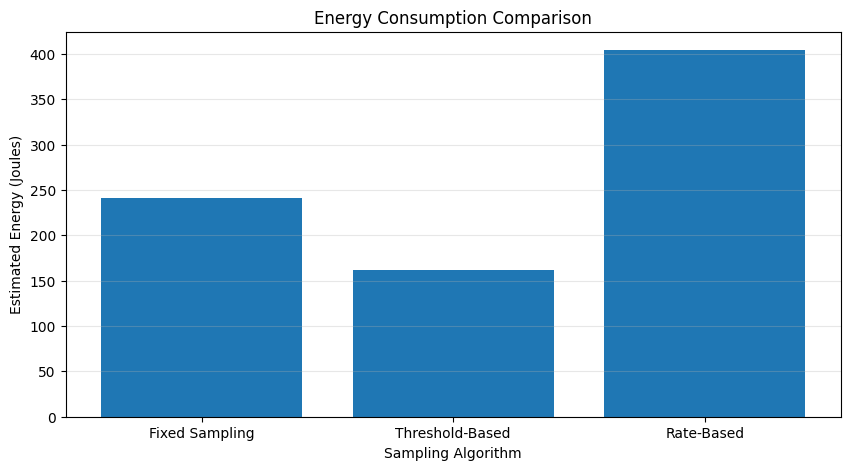

In [49]:
plt.figure(figsize=(10, 5))

plt.bar(
    energy_df['Algorithm'],
    energy_df['Total Energy (J)']
)

plt.xlabel('Sampling Algorithm')
plt.ylabel('Estimated Energy (Joules)')

plt.title('Energy Consumption Comparison')

plt.grid(axis='y', alpha=0.3)

plt.show()

In [50]:
# ENERGY MODEL VALIDATION

assert len(energy_df) == 3

assert (energy_df['Total Energy (J)'] > 0).all()

assert (
    energy_df['Transmission Energy (J)'] > 0
).all()

assert (
    energy_df['Energy Savings (%)'].between(-100, 100)
).all()

print("Phase 5.3 validation: PASSED")

Phase 5.3 validation: PASSED


## Phase 6: Advanced Performance Evaluation

### 6.1 Event Detection Latency

Evaluate how quickly each sampling algorithm
detects the beginning of environmental events.

Metrics:
- Total event episodes
- Detected episodes
- Missed episodes
- Average detection latency
- Maximum detection latency

In [51]:
# PHASE 6.1 - EVENT DETECTION LATENCY

def calculate_event_latency(original_df, sampled_df):

    total_events = 0
    detected_events = 0
    latencies = []

    for node_id, original_node in original_df.groupby('node_id'):

        original_node = original_node.sort_values(
            'time_seconds'
        ).reset_index(drop=True)

        # Identify event episodes
        event_mask = original_node['event_active'].eq(1)

        episode_id = (
            event_mask.ne(
                event_mask.shift(fill_value=False)
            ).cumsum()
        )

        event_rows = original_node[event_mask].copy()

        sampled_node = sampled_df[
            sampled_df['node_id'] == node_id
        ].sort_values('time_seconds')

        transmitted_times = sampled_node[
            'time_seconds'
        ].values

        for episode, episode_data in event_rows.groupby(
            episode_id[event_mask]
        ):

            total_events += 1

            event_start = episode_data[
                'time_seconds'
            ].min()

            event_end = episode_data[
                'time_seconds'
            ].max()

            # Find first transmission within event
            valid_transmissions = transmitted_times[
                (transmitted_times >= event_start) &
                (transmitted_times <= event_end)
            ]

            if len(valid_transmissions) > 0:

                detection_time = valid_transmissions.min()

                latency = detection_time - event_start

                detected_events += 1

                latencies.append(latency)

    return {
        'Total Events': total_events,
        'Detected Events': detected_events,
        'Missed Events': total_events - detected_events,
        'Detection Rate (%)': (
            detected_events / total_events * 100
            if total_events else 0
        ),
        'Average Latency (sec)': (
            np.mean(latencies) if latencies else np.nan
        ),
        'Maximum Latency (sec)': (
            np.max(latencies) if latencies else np.nan
        )
    }


latency_results = []

for name, samples in {
    'Fixed Sampling': fixed_samples,
    'Threshold-Based': threshold_df,
    'Rate-Based': rate_based_df
}.items():

    result = calculate_event_latency(df, samples)

    result['Algorithm'] = name

    latency_results.append(result)


latency_df = pd.DataFrame(latency_results)

print("EVENT DETECTION LATENCY COMPARISON")

display(latency_df.round(3))

EVENT DETECTION LATENCY COMPARISON


,Total Events,Detected Events,Missed Events,Detection Rate (%),Average Latency (sec),Maximum Latency (sec),Algorithm
0,10,10,0,100.0,0.0,0,Fixed Sampling
1,10,10,0,100.0,12.7,26,Threshold-Based
2,10,10,0,100.0,4.2,10,Rate-Based


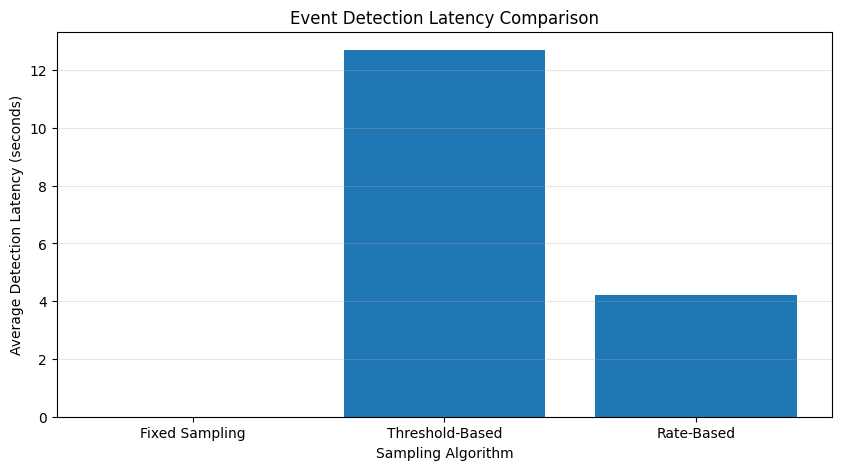

In [52]:
plt.figure(figsize=(10, 5))

plt.bar(
    latency_df['Algorithm'],
    latency_df['Average Latency (sec)']
)

plt.xlabel('Sampling Algorithm')
plt.ylabel('Average Detection Latency (seconds)')

plt.title('Event Detection Latency Comparison')

plt.grid(axis='y', alpha=0.3)

plt.show()

In [53]:
assert len(latency_df) == 3

assert (
    latency_df['Detected Events'] +
    latency_df['Missed Events'] ==
    latency_df['Total Events']
).all()

assert latency_df[
    'Detection Rate (%)'
].between(0, 100).all()

print("Phase 6.1 validation: PASSED")

Phase 6.1 validation: PASSED


In [54]:
# PHASE 6.2 - NETWORK LIFETIME ESTIMATION

# Battery assumptions
BATTERY_CAPACITY_MAH = 2000
BATTERY_VOLTAGE = 3.7

# Convert battery capacity into joules
battery_energy_j = (
    BATTERY_CAPACITY_MAH / 1000
) * BATTERY_VOLTAGE * 3600

# Energy assumptions
SENSING_ENERGY_MJ = 0.5
PROCESSING_ENERGY_MJ = 0.2
TRANSMISSION_ENERGY_MJ = 50

# Dataset duration
SIMULATION_DURATION_SECONDS = (
    df['time_seconds'].max() -
    df['time_seconds'].min() + 1
)

print("BATTERY AND SIMULATION CONFIGURATION")
print("------------------------------------")

print(f"Battery capacity: {BATTERY_CAPACITY_MAH} mAh")
print(f"Battery voltage: {BATTERY_VOLTAGE} V")
print(f"Battery energy: {battery_energy_j:.2f} J")

print(
    f"Simulation duration: "
    f"{SIMULATION_DURATION_SECONDS} seconds"
)

print(
    f"Simulation duration: "
    f"{SIMULATION_DURATION_SECONDS / 3600:.2f} hours"
)

BATTERY AND SIMULATION CONFIGURATION
------------------------------------
Battery capacity: 2000 mAh
Battery voltage: 3.7 V
Battery energy: 26640.00 J
Simulation duration: 3600 seconds
Simulation duration: 1.00 hours


In [55]:
# PHASE 6.2 - STEP 2
# PER-NODE ENERGY CONSUMPTION

algorithms = {
    'Fixed Sampling': fixed_samples,
    'Threshold-Based': threshold_df,
    'Rate-Based': rate_based_df
}

node_energy_results = []

for algorithm_name, sampled_data in algorithms.items():

    for node_id in sorted(df['node_id'].unique()):

        # Number of transmissions by this node
        transmissions = len(
            sampled_data[
                sampled_data['node_id'] == node_id
            ]
        )

        # Energy consumed by sensing and processing
        sensing_energy = (
            3600 * SENSING_ENERGY_MJ / 1000
        )

        processing_energy = (
            3600 * PROCESSING_ENERGY_MJ / 1000
        )

        # Transmission energy
        transmission_energy = (
            transmissions * TRANSMISSION_ENERGY_MJ / 1000
        )

        # Total sensor node energy
        total_node_energy = (
            sensing_energy +
            processing_energy +
            transmission_energy
        )

        # Estimated lifetime in hours
        lifetime_hours = (
            battery_energy_j / total_node_energy
        )

        node_energy_results.append({
            'Algorithm': algorithm_name,
            'Node ID': node_id,
            'Transmissions': transmissions,
            'Sensing Energy (J)': sensing_energy,
            'Processing Energy (J)': processing_energy,
            'Transmission Energy (J)': transmission_energy,
            'Total Node Energy (J)': total_node_energy,
            'Estimated Lifetime (hours)': lifetime_hours
        })

node_energy_df = pd.DataFrame(node_energy_results)

print("PER-NODE ENERGY CONSUMPTION")
display(node_energy_df.round(3))

PER-NODE ENERGY CONSUMPTION


,Algorithm,Node ID,Transmissions,Sensing Energy (J),Processing Energy (J),Transmission Energy (J),Total Node Energy (J),Estimated Lifetime (hours)
0,Fixed Sampling,1,360,1.8,0.72,18.00,20.52,1298.246
1,Fixed Sampling,2,360,1.8,0.72,18.00,20.52,1298.246
2,Fixed Sampling,3,360,1.8,0.72,18.00,20.52,1298.246
3,Fixed Sampling,4,360,1.8,0.72,18.00,20.52,1298.246
4,Fixed Sampling,5,360,1.8,0.72,18.00,20.52,1298.246
5,Fixed Sampling,6,360,1.8,0.72,18.00,20.52,1298.246
6,Fixed Sampling,7,360,1.8,0.72,18.00,20.52,1298.246
7,Fixed Sampling,8,360,1.8,0.72,18.00,20.52,1298.246
8,Fixed Sampling,9,360,1.8,0.72,18.00,20.52,1298.246
9,Fixed Sampling,10,360,1.8,0.72,18.00,20.52,1298.246


In [56]:
# PHASE 6.2 - STEP 3
# NETWORK LIFETIME ESTIMATION

network_lifetime_results = []

for algorithm_name, group in node_energy_df.groupby('Algorithm'):

    weakest_node = group.loc[
        group['Estimated Lifetime (hours)'].idxmin()
    ]

    network_lifetime_hours = (
        weakest_node['Estimated Lifetime (hours)']
    )

    network_lifetime_days = (
        network_lifetime_hours / 24
    )

    network_lifetime_results.append({
        'Algorithm': algorithm_name,
        'Weakest Node': int(weakest_node['Node ID']),
        'Maximum Node Energy (J)': weakest_node[
            'Total Node Energy (J)'
        ],
        'Network Lifetime (hours)': network_lifetime_hours,
        'Network Lifetime (days)': network_lifetime_days
    })

network_lifetime_df = pd.DataFrame(
    network_lifetime_results
)

print("NETWORK LIFETIME COMPARISON")

display(network_lifetime_df.round(2))

NETWORK LIFETIME COMPARISON


,Algorithm,Weakest Node,Maximum Node Energy (J),Network Lifetime (hours),Network Lifetime (days)
0,Fixed Sampling,1,20.52,1298.25,54.09
1,Rate-Based,8,34.92,762.89,31.79
2,Threshold-Based,6,15.57,1710.98,71.29


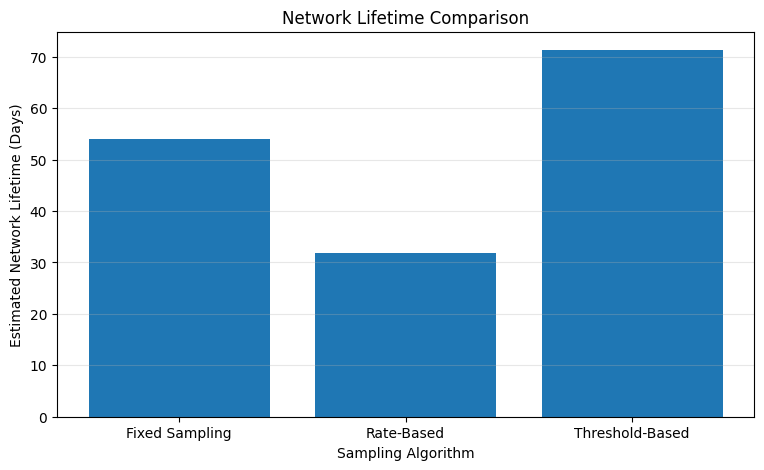

In [57]:
plt.figure(figsize=(9, 5))

plt.bar(
    network_lifetime_df['Algorithm'],
    network_lifetime_df['Network Lifetime (days)']
)

plt.xlabel('Sampling Algorithm')
plt.ylabel('Estimated Network Lifetime (Days)')
plt.title('Network Lifetime Comparison')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [58]:
# PHASE 6.3 - ENERGY-ACCURACY TRADE-OFF

final_comparison = pd.DataFrame({
    'Algorithm': [
        'Fixed Sampling',
        'Threshold-Based',
        'Rate-Based'
    ],

    'Transmission Reduction (%)': [
        90.00,
        93.68,
        82.44
    ],

    'Temperature MAE': [
        0.14574,
        0.14768,
        0.15160
    ],

    'Humidity MAE': [
        0.49467,
        0.56818,
        0.63853
    ],

    'Energy Consumption (J)': [
        241.20,
        161.70,
        404.40
    ],

    'Event Detection Rate (%)': [
        100.00,
        100.00,
        100.00
    ],

    'Average Latency (sec)': [
        0.00,
        12.70,
        4.20
    ],

    'Network Lifetime (days)': [
        54.09,
        71.29,
        31.79
    ]
})

print("FINAL ALGORITHM PERFORMANCE COMPARISON")

display(final_comparison.round(3))

FINAL ALGORITHM PERFORMANCE COMPARISON


,Algorithm,Transmission Reduction (%),Temperature MAE,Humidity MAE,Energy Consumption (J),Event Detection Rate (%),Average Latency (sec),Network Lifetime (days)
0,Fixed Sampling,90.00,0.146,0.495,241.2,100.0,0.0,54.09
1,Threshold-Based,93.68,0.148,0.568,161.7,100.0,12.7,71.29
2,Rate-Based,82.44,0.152,0.639,404.4,100.0,4.2,31.79


In [59]:
assert len(final_comparison) == 3

assert final_comparison[
    'Transmission Reduction (%)'
].between(0, 100).all()

assert final_comparison[
    'Event Detection Rate (%)'
].between(0, 100).all()

print("Phase 6.3 validation: PASSED")

Phase 6.3 validation: PASSED


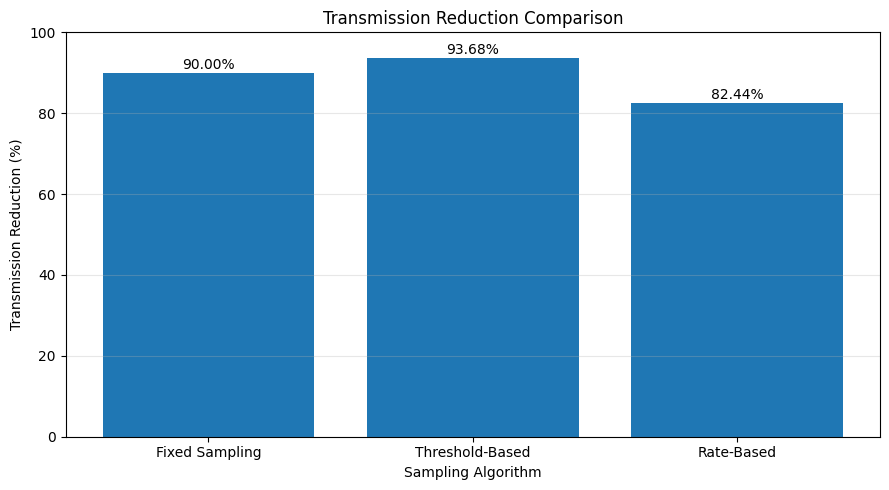

In [60]:
# PHASE 6.4 - GRAPH 1
# TRANSMISSION REDUCTION COMPARISON

plt.figure(figsize=(9, 5))

bars = plt.bar(
    final_comparison['Algorithm'],
    final_comparison['Transmission Reduction (%)']
)

plt.xlabel('Sampling Algorithm')
plt.ylabel('Transmission Reduction (%)')
plt.title('Transmission Reduction Comparison')

plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

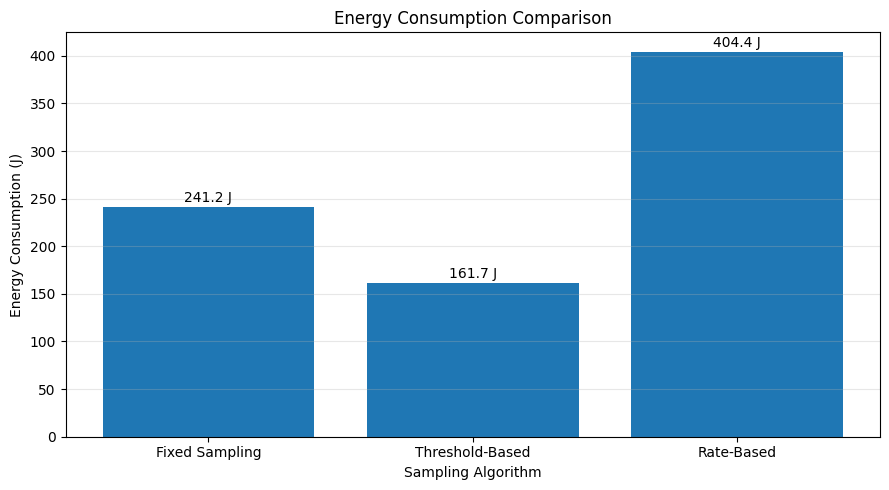

In [61]:
# GRAPH 2 - ENERGY CONSUMPTION COMPARISON

plt.figure(figsize=(9, 5))

bars = plt.bar(
    final_comparison['Algorithm'],
    final_comparison['Energy Consumption (J)']
)

plt.xlabel('Sampling Algorithm')
plt.ylabel('Energy Consumption (J)')
plt.title('Energy Consumption Comparison')

plt.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        f'{height:.1f} J',
        ha='center'
    )

plt.tight_layout()
plt.show()

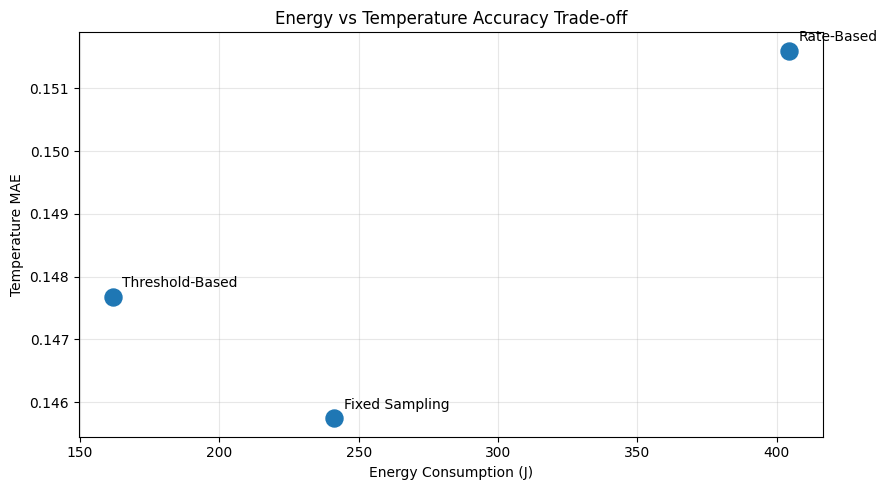

In [62]:
# GRAPH 3 - ACCURACY VS ENERGY TRADE-OFF

plt.figure(figsize=(9, 5))

plt.scatter(
    final_comparison['Energy Consumption (J)'],
    final_comparison['Temperature MAE'],
    s=150
)

for _, row in final_comparison.iterrows():

    plt.annotate(
        row['Algorithm'],
        (
            row['Energy Consumption (J)'],
            row['Temperature MAE']
        ),
        xytext=(7, 7),
        textcoords='offset points'
    )

plt.xlabel('Energy Consumption (J)')
plt.ylabel('Temperature MAE')
plt.title('Energy vs Temperature Accuracy Trade-off')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
# Download the original Intel Lab dataset

!wget -O intel_data.txt.gz https://db.csail.mit.edu/labdata/data.txt.gz

--2026-11-21 10:13:51--  https://db.csail.mit.edu/labdata/data.txt.gz
Resolving db.csail.mit.edu (db.csail.mit.edu)... 128.52.128.91
Connecting to db.csail.mit.edu (db.csail.mit.edu)|128.52.128.91|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 34422518 (33M) [application/x-gzip]
Saving to: ‘intel_data.txt.gz’

intel_data.txt.gz   100%[===================>]  32.83M  59.3MB/s    in 0.6s    

2026-11-21 10:13:52 (59.3 MB/s) - ‘intel_data.txt.gz’ saved [34422518/34422518]



In [64]:
import os

file_path = "/content/intel_data.txt.gz"

if os.path.exists(file_path):
    size_mb = os.path.getsize(file_path) / (1024 * 1024)

    print("Dataset downloaded successfully!")
    print("File size:", round(size_mb, 2), "MB")
else:
    print("Dataset download failed.")

Dataset downloaded successfully!
File size: 32.83 MB


In [65]:
# Extract the original dataset

!gzip -dk intel_data.txt.gz

print("Dataset extraction completed!")

Dataset extraction completed!


In [66]:
# Display the first 10 records

!head -10 intel_data.txt

2004-03-31 03:38:15.757551 2 1 122.153 -3.91901 11.04 2.03397
2004-02-28 00:59:16.02785 3 1 19.9884 37.0933 45.08 2.69964
2004-02-28 01:03:16.33393 11 1 19.3024 38.4629 45.08 2.68742
2004-02-28 01:06:16.013453 17 1 19.1652 38.8039 45.08 2.68742
2004-02-28 01:06:46.778088 18 1 19.175 38.8379 45.08 2.69964
2004-02-28 01:08:45.992524 22 1 19.1456 38.9401 45.08 2.68742
2004-02-28 01:09:22.323858 23 1 19.1652 38.872 45.08 2.68742
2004-02-28 01:09:46.109598 24 1 19.1652 38.8039 45.08 2.68742
2004-02-28 01:10:16.6789 25 1 19.1456 38.8379 45.08 2.69964
2004-02-28 01:10:46.250524 26 1 19.1456 38.872 45.08 2.68742


In [67]:
import pandas as pd
import numpy as np

# Define original dataset columns

columns = [
    "date",
    "time",
    "epoch",
    "moteid",
    "temperature",
    "humidity",
    "light",
    "voltage"
]

# Load whitespace-separated data

intel_df = pd.read_csv(
    "/content/intel_data.txt",
    sep=r"\s+",
    names=columns,
    header=None
)

print("Dataset loaded successfully!")
print("Dataset shape:", intel_df.shape)

display(intel_df.head())

Dataset loaded successfully!
Dataset shape: (2313682, 8)


,date,time,epoch,moteid,temperature,humidity,light,voltage
0,2004-03-31,03:38:15.757551,2,1.0,122.1530,-3.91901,11.04,2.03397
1,2004-02-28,00:59:16.02785,3,1.0,19.9884,37.09330,45.08,2.69964
2,2004-02-28,01:03:16.33393,11,1.0,19.3024,38.46290,45.08,2.68742
3,2004-02-28,01:06:16.013453,17,1.0,19.1652,38.80390,45.08,2.68742
4,2004-02-28,01:06:46.778088,18,1.0,19.1750,38.83790,45.08,2.69964


In [68]:
print("DATASET PROFILE")
print("=" * 45)

print("Total records:", len(intel_df))

print("Unique sensor nodes:", intel_df["moteid"].nunique())

print("Sensor IDs:")
print(sorted(intel_df["moteid"].unique()))

print("\nMissing values:")
print(intel_df.isnull().sum())

print("\nStatistical summary:")
display(intel_df.describe())

print("\nRecords per sensor:")
display(intel_df["moteid"].value_counts().sort_index())

DATASET PROFILE
Total records: 2313682
Unique sensor nodes: 61
Sensor IDs:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0), np.float64(52.0

,epoch,moteid,temperature,humidity,light,voltage
count,2.313682e+06,2.313156e+06,2.313156e+06,2.312783e+06,2.312779e+06,2.219803e+06
mean,3.303993e+04,2.854412e+01,3.920103e+01,3.390809e+01,3.909430e+02,2.490634e+00
std,1.836852e+04,5.062408e+01,3.741915e+01,1.732155e+01,5.344185e+02,1.784080e-01
min,0.000000e+00,1.000000e+00,-3.840000e+01,-8.983130e+03,0.000000e+00,9.100830e-03
25%,1.757200e+04,1.700000e+01,2.040980e+01,3.187760e+01,1.840000e+01,2.385220e+00
50%,3.332700e+04,2.900000e+01,2.243840e+01,3.928030e+01,1.435200e+02,2.527320e+00
75%,4.778900e+04,4.100000e+01,2.701500e+01,4.358550e+01,5.078400e+02,2.627960e+00
max,6.553500e+04,6.540700e+04,3.855680e+02,1.375120e+02,1.847360e+03,3.159150e+00



Records per sensor:


,count
moteid,
1.0,43047
2.0,46915
3.0,46634
4.0,43793
5.0,35
...,...
57.0,3
58.0,4502
6485.0,1


In [69]:
# STEP 10: TIMESTAMP PREPARATION

# Combine date and time
intel_df["timestamp"] = pd.to_datetime(
    intel_df["date"].astype(str) + " " + intel_df["time"].astype(str),
    errors="coerce"
)

# Convert sensor measurements into numeric values
numeric_columns = [
    "epoch", "moteid", "temperature",
    "humidity", "light", "voltage"
]

for col in numeric_columns:
    intel_df[col] = pd.to_numeric(
        intel_df[col], errors="coerce"
    )

# Sort chronologically
intel_df = intel_df.sort_values(
    ["timestamp", "moteid"]
).reset_index(drop=True)

print("TIMESTAMP PREPARATION COMPLETED")
print("=" * 45)

print("Start time:", intel_df["timestamp"].min())
print("End time:", intel_df["timestamp"].max())

print("Total records:", len(intel_df))
print("Unique sensor nodes:", intel_df["moteid"].nunique())

display(intel_df.head(10))

TIMESTAMP PREPARATION COMPLETED
Start time: 2004-02-28 00:58:15.315133
End time: 2004-04-05 11:02:32.715337
Total records: 2313682
Unique sensor nodes: 61


,date,time,epoch,moteid,temperature,humidity,light,voltage,timestamp
0,2004-02-28,00:58:15.315133,1,NaN,NaN,NaN,NaN,NaN,2004-02-28 00:58:15.315133
1,2004-02-28,00:58:46.002832,2,19.0,19.7336,37.0933,71.76000,2.69964,2004-02-28 00:58:46.002832
2,2004-02-28,00:58:46.171824,2,25.0,19.6160,37.5737,97.52000,2.69964,2004-02-28 00:58:46.171824
3,2004-02-28,00:58:46.206631,2,24.0,19.7728,37.1620,143.52000,2.71196,2004-02-28 00:58:46.206631
4,2004-02-28,00:58:46.497331,2,3.0,20.2040,36.8871,50.60000,2.69964,2004-02-28 00:58:46.497331
5,2004-02-28,00:58:46.504403,2,28.0,19.0476,40.0945,2.80151,NaN,2004-02-28 00:58:46.504403
6,2004-02-28,00:58:46.657464,2,6.0,20.4196,36.6118,121.44000,2.65143,2004-02-28 00:58:46.657464
7,2004-02-28,00:58:46.780824,2,26.0,19.4494,39.6200,121.44000,2.69964,2004-02-28 00:58:46.780824
8,2004-02-28,00:58:46.876528,2,27.0,20.1354,37.1620,79.12000,2.71196,2004-02-28 00:58:46.876528
9,2004-02-28,00:58:46.910403,2,31.0,19.5572,39.0763,150.88000,2.69964,2004-02-28 00:58:46.910403


In [70]:
# STEP 11: DATA QUALITY ANALYSIS

print("DATA QUALITY REPORT")
print("=" * 55)

# 1. Missing values
print("\n1. MISSING VALUES")
display(intel_df.isnull().sum())

# 2. Duplicate records
print("\n2. DUPLICATE RECORDS")

duplicates = intel_df.duplicated(
    subset=["timestamp", "moteid"]
).sum()

print("Duplicate node-timestamp records:", duplicates)

# 3. Sensor node information
print("\n3. SENSOR NODE INFORMATION")

print("Total unique nodes:", intel_df["moteid"].nunique())

print("Sensor IDs:")
print(sorted(intel_df["moteid"].dropna().unique()))

# 4. Measurement statistics
print("\n4. MEASUREMENT STATISTICS")

display(
    intel_df[
        ["temperature", "humidity", "light", "voltage"]
    ].describe()
)

# 5. Suspicious measurement counts
print("\n5. SUSPICIOUS MEASUREMENTS")

print(
    "Temperature below -10 or above 50:",
    ((intel_df["temperature"] < -10) |
     (intel_df["temperature"] > 50)).sum()
)

print(
    "Humidity below 0 or above 100:",
    ((intel_df["humidity"] < 0) |
     (intel_df["humidity"] > 100)).sum()
)

print(
    "Negative light readings:",
    (intel_df["light"] < 0).sum()
)

print(
    "Voltage below 1.8 or above 3.3:",
    ((intel_df["voltage"] < 1.8) |
     (intel_df["voltage"] > 3.3)).sum()
)

# 6. Records per sensor node
print("\n6. RECORDS PER SENSOR NODE")

node_counts = intel_df.groupby("moteid").size()

display(node_counts.to_frame("record_count"))

# 7. Time coverage
print("\n7. TIME COVERAGE")

print("First measurement:", intel_df["timestamp"].min())
print("Last measurement:", intel_df["timestamp"].max())

print("\nDATA QUALITY ANALYSIS COMPLETED")

DATA QUALITY REPORT

1. MISSING VALUES


,0
date,0
time,0
epoch,0
moteid,526
temperature,526
humidity,899
light,903
voltage,93879
timestamp,4



2. DUPLICATE RECORDS
Duplicate node-timestamp records: 0

3. SENSOR NODE INFORMATION
Total unique nodes: 61
Sensor IDs:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.fl

,temperature,humidity,light,voltage
count,2.313156e+06,2.312783e+06,2.312779e+06,2.219803e+06
mean,3.920103e+01,3.390809e+01,3.909430e+02,2.490634e+00
std,3.741915e+01,1.732155e+01,5.344185e+02,1.784080e-01
min,-3.840000e+01,-8.983130e+03,0.000000e+00,9.100830e-03
25%,2.040980e+01,3.187760e+01,1.840000e+01,2.385220e+00
50%,2.243840e+01,3.928030e+01,1.435200e+02,2.527320e+00
75%,2.701500e+01,4.358550e+01,5.078400e+02,2.627960e+00
max,3.855680e+02,1.375120e+02,1.847360e+03,3.159150e+00



5. SUSPICIOUS MEASUREMENTS
Temperature below -10 or above 50: 408072
Humidity below 0 or above 100: 299084
Negative light readings: 0
Voltage below 1.8 or above 3.3: 4

6. RECORDS PER SENSOR NODE


,record_count
moteid,
1.0,43047
2.0,46915
3.0,46634
4.0,43793
5.0,35
...,...
57.0,3
58.0,4502
6485.0,1



7. TIME COVERAGE
First measurement: 2004-02-28 00:58:15.315133
Last measurement: 2004-04-05 11:02:32.715337

DATA QUALITY ANALYSIS COMPLETED


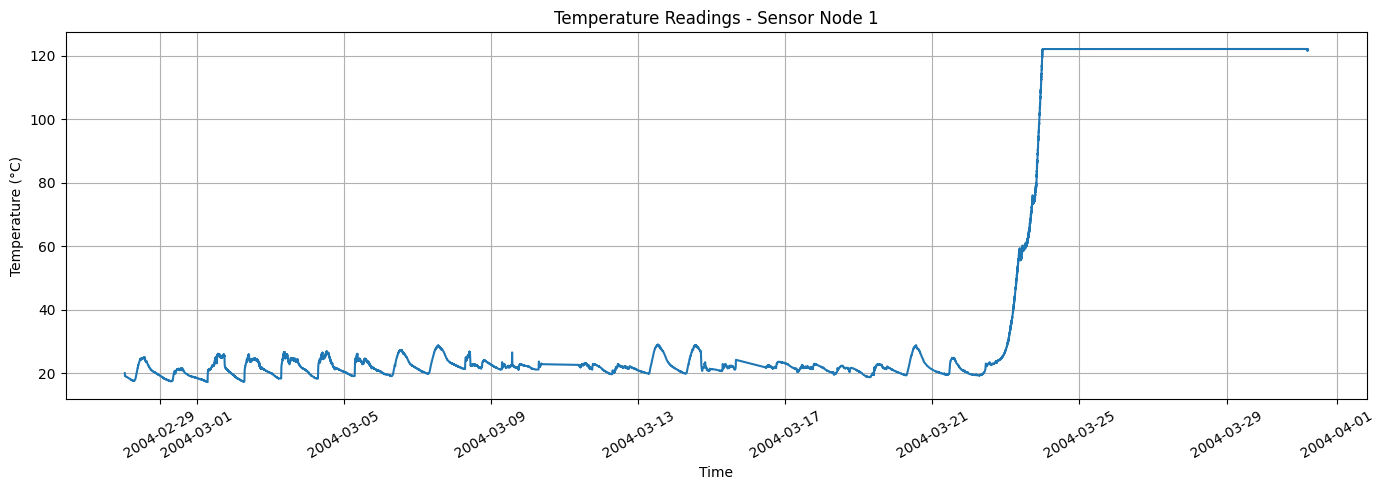

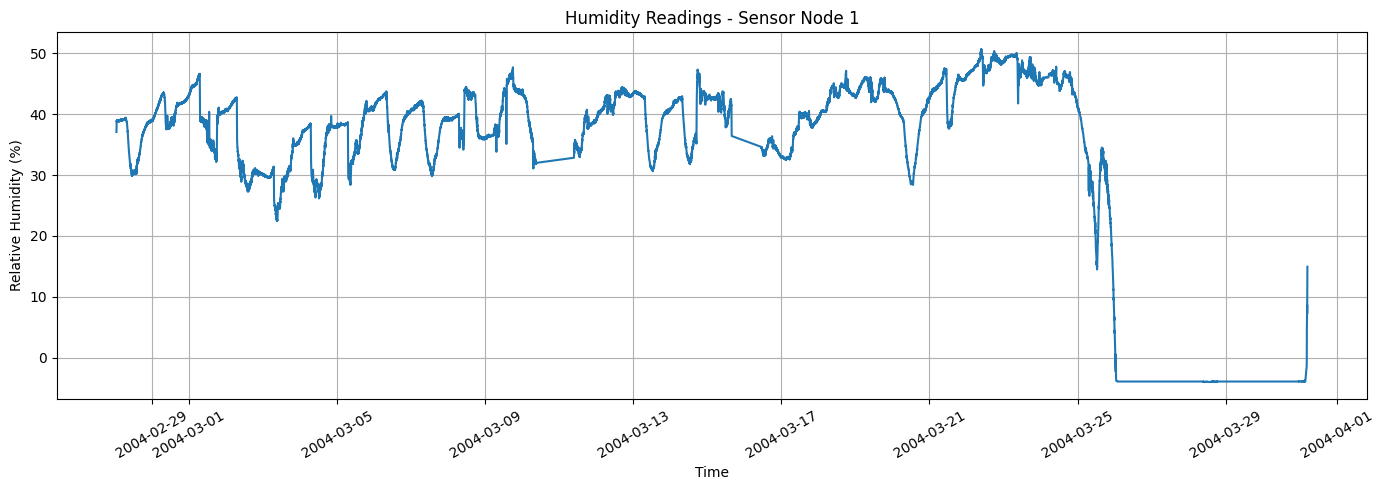

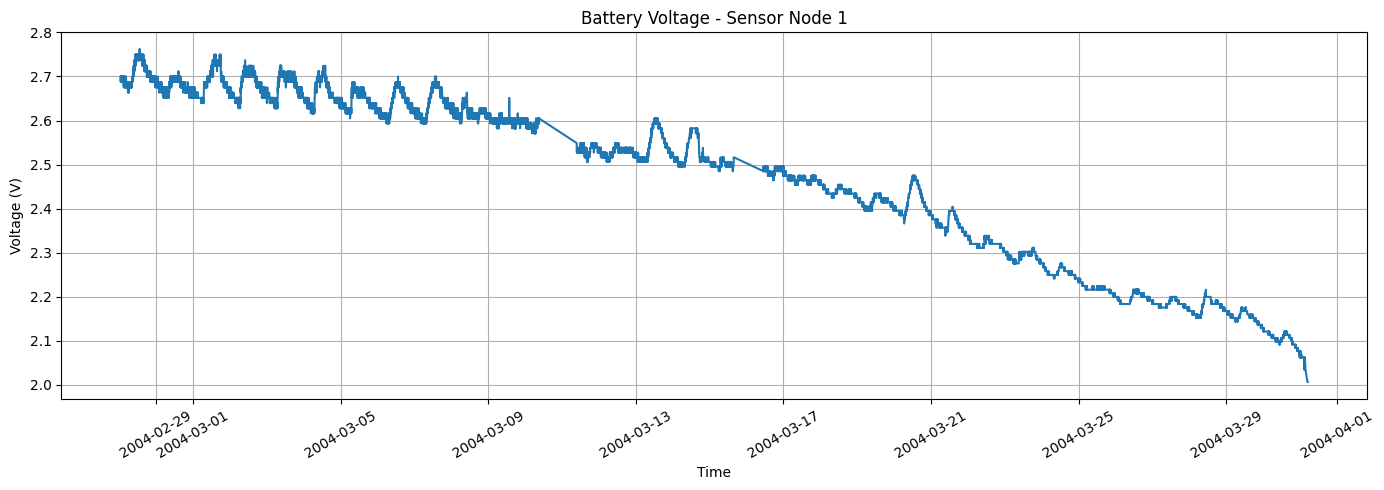

In [71]:
import matplotlib.pyplot as plt

# Select the first sensor node with valid timestamps
sample_node = int(intel_df["moteid"].dropna().min())

node_data = intel_df[
    intel_df["moteid"] == sample_node
].sort_values("timestamp")

# Temperature
plt.figure(figsize=(14, 5))
plt.plot(
    node_data["timestamp"],
    node_data["temperature"]
)
plt.title(f"Temperature Readings - Sensor Node {sample_node}")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

# Humidity
plt.figure(figsize=(14, 5))
plt.plot(
    node_data["timestamp"],
    node_data["humidity"]
)
plt.title(f"Humidity Readings - Sensor Node {sample_node}")
plt.xlabel("Time")
plt.ylabel("Relative Humidity (%)")
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

# Battery voltage
plt.figure(figsize=(14, 5))
plt.plot(
    node_data["timestamp"],
    node_data["voltage"]
)
plt.title(f"Battery Voltage - Sensor Node {sample_node}")
plt.xlabel("Time")
plt.ylabel("Voltage (V)")
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

In [72]:
# STEP 13: IDENTIFY VALID SENSOR NODES

# Preserve the original DataFrame.
# Create a separate working copy.

valid_id_df = intel_df[
    intel_df["moteid"].between(1, 54) &
    intel_df["timestamp"].notna()
].copy()

valid_id_df["moteid"] = valid_id_df["moteid"].astype(int)

print("VALID SENSOR NETWORK PROFILE")
print("=" * 50)

print("Original records:", len(intel_df))
print("Records with valid sensor IDs:", len(valid_id_df))

print("Unique valid sensor nodes:",
      valid_id_df["moteid"].nunique())

print("\nAvailable sensor IDs:")
print(sorted(valid_id_df["moteid"].unique()))

print("\nUnexpected records removed from working dataset:",
      len(intel_df) - len(valid_id_df))

VALID SENSOR NETWORK PROFILE
Original records: 2313682
Records with valid sensor IDs: 2303286
Unique valid sensor nodes: 54

Available sensor IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54)]

Unexpected records removed from working dataset: 10396


In [73]:
# STEP 14: SENSOR-WISE DATA QUALITY

sensor_quality = valid_id_df.groupby("moteid").agg(
    total_records=("epoch", "count"),

    temperature_missing=("temperature",
                         lambda x: x.isna().sum()),

    humidity_missing=("humidity",
                      lambda x: x.isna().sum()),

    light_missing=("light",
                   lambda x: x.isna().sum()),

    voltage_missing=("voltage",
                     lambda x: x.isna().sum()),

    first_record=("timestamp", "min"),

    last_record=("timestamp", "max")
)

# Calculate valid temperature/humidity record counts
sensor_quality["valid_temp_humidity"] = (
    valid_id_df.groupby("moteid")
    .apply(
        lambda x: (
            x["temperature"].between(-10, 50) &
            x["humidity"].between(0, 100)
        ).sum(),
        include_groups=False
    )
)

sensor_quality = sensor_quality.sort_values(
    "valid_temp_humidity",
    ascending=False
)

display(sensor_quality)

,total_records,temperature_missing,humidity_missing,light_missing,voltage_missing,first_record,last_record,valid_temp_humidity
moteid,,,,,,,,
48,58226,0,0,0,11,2004-02-28 01:06:46.323955,2004-04-01 23:20:51.919631,55836
22,60165,0,1,1,1,2004-02-28 00:59:16.853347,2004-03-30 09:13:44.335816,55202
47,57201,0,1,1,343,2004-02-28 01:06:46.625200,2004-04-01 23:18:51.756517,54906
45,53245,0,0,0,0,2004-02-28 01:06:46.696192,2004-03-24 05:57:47.242191,53195
31,65693,0,5,5,5,2004-02-28 00:58:46.910403,2004-03-30 23:58:45.825942,52814
21,58525,0,4,4,4,2004-02-28 01:01:16.934932,2004-03-30 06:43:44.702613,49603
23,62440,0,24,24,31,2004-02-28 00:59:16.521007,2004-04-02 15:32:49.628609,48458
29,64391,0,7,7,7,2004-02-28 00:59:46.081919,2004-04-01 23:22:04.262660,47556
36,57743,0,10,10,1386,2004-02-28 01:03:16.179903,2004-04-01 23:52:19.758425,46785


In [74]:
# STEP 15: IDENTIFY TOP 10 CANDIDATE NODES

candidate_nodes = (
    sensor_quality[
        sensor_quality["valid_temp_humidity"] >= 1000
    ]
    .head(10)
    .index
    .tolist()
)

print("SELECTED CANDIDATE SENSOR NODES:")
print(candidate_nodes)

print("\nCandidate sensor quality:")
display(sensor_quality.loc[candidate_nodes])

SELECTED CANDIDATE SENSOR NODES:
[48, 22, 47, 45, 31, 21, 23, 29, 36, 46]

Candidate sensor quality:


,total_records,temperature_missing,humidity_missing,light_missing,voltage_missing,first_record,last_record,valid_temp_humidity
moteid,,,,,,,,
48,58226,0,0,0,11,2004-02-28 01:06:46.323955,2004-04-01 23:20:51.919631,55836
22,60165,0,1,1,1,2004-02-28 00:59:16.853347,2004-03-30 09:13:44.335816,55202
47,57201,0,1,1,343,2004-02-28 01:06:46.625200,2004-04-01 23:18:51.756517,54906
45,53245,0,0,0,0,2004-02-28 01:06:46.696192,2004-03-24 05:57:47.242191,53195
31,65693,0,5,5,5,2004-02-28 00:58:46.910403,2004-03-30 23:58:45.825942,52814
21,58525,0,4,4,4,2004-02-28 01:01:16.934932,2004-03-30 06:43:44.702613,49603
23,62440,0,24,24,31,2004-02-28 00:59:16.521007,2004-04-02 15:32:49.628609,48458
29,64391,0,7,7,7,2004-02-28 00:59:46.081919,2004-04-01 23:22:04.262660,47556
36,57743,0,10,10,1386,2004-02-28 01:03:16.179903,2004-04-01 23:52:19.758425,46785


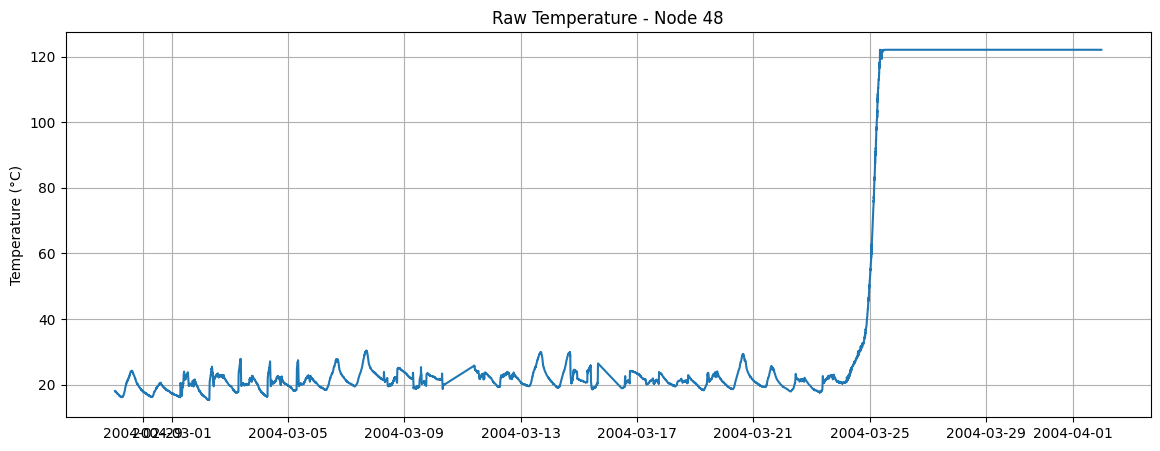

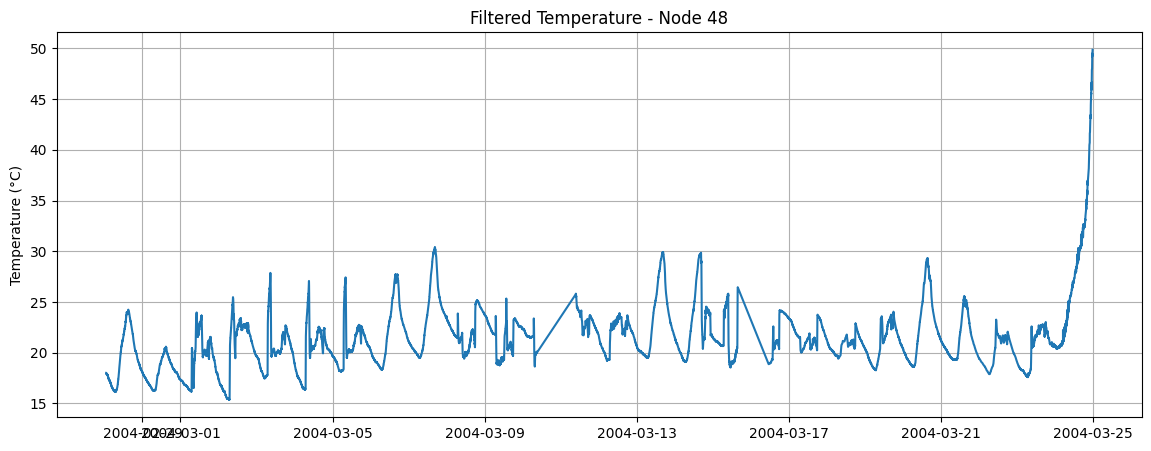

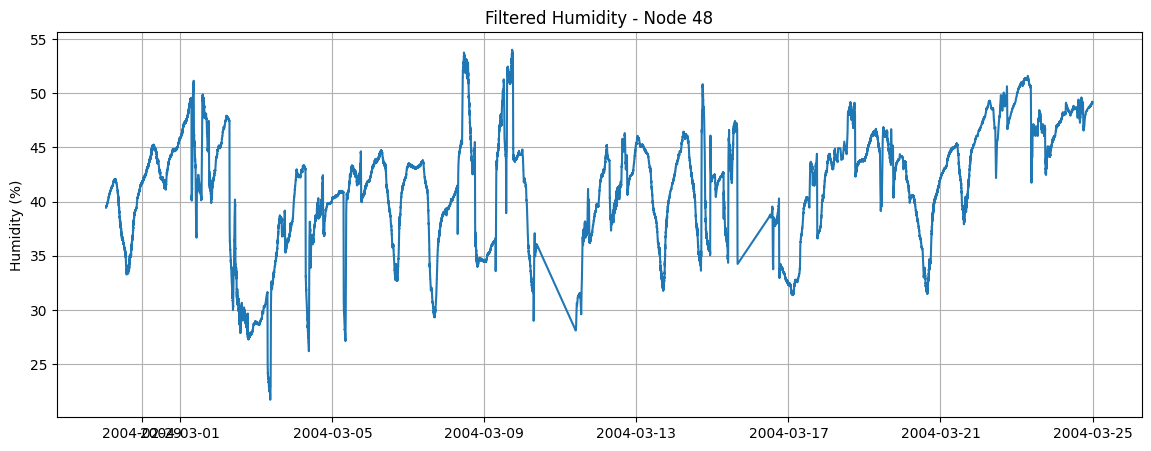

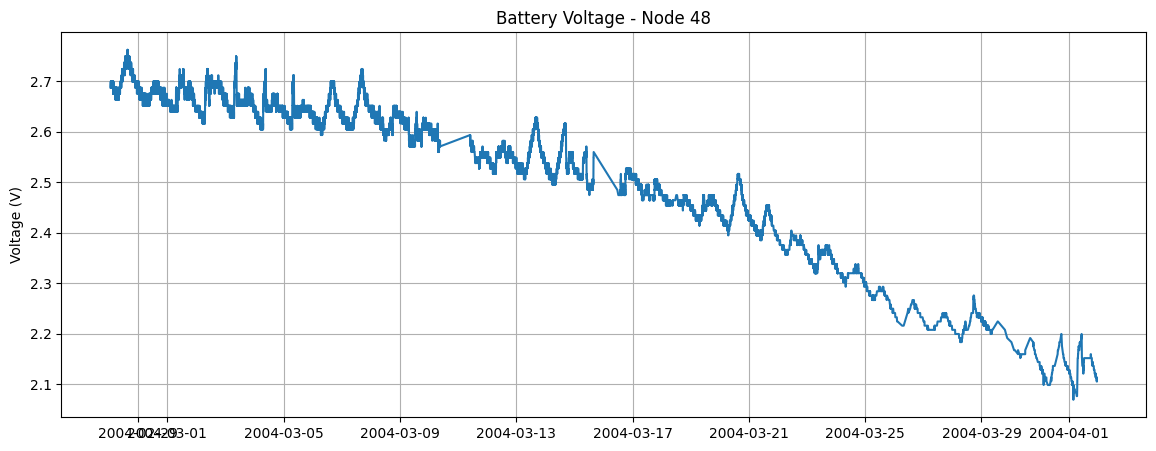

In [75]:
# STEP 16: COMPARE RAW AND PLAUSIBLE READINGS

sample_node = candidate_nodes[0]

sample_raw = valid_id_df[
    valid_id_df["moteid"] == sample_node
].sort_values("timestamp")

sample_clean = sample_raw[
    sample_raw["temperature"].between(-10, 50) &
    sample_raw["humidity"].between(0, 100)
]

import matplotlib.pyplot as plt

# Raw temperature
plt.figure(figsize=(14, 5))
plt.plot(
    sample_raw["timestamp"],
    sample_raw["temperature"]
)
plt.title(f"Raw Temperature - Node {sample_node}")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

# Filtered temperature
plt.figure(figsize=(14, 5))
plt.plot(
    sample_clean["timestamp"],
    sample_clean["temperature"]
)
plt.title(f"Filtered Temperature - Node {sample_node}")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

# Filtered humidity
plt.figure(figsize=(14, 5))
plt.plot(
    sample_clean["timestamp"],
    sample_clean["humidity"]
)
plt.title(f"Filtered Humidity - Node {sample_node}")
plt.ylabel("Humidity (%)")
plt.grid(True)
plt.show()

# Battery voltage
plt.figure(figsize=(14, 5))
plt.plot(
    sample_raw["timestamp"],
    sample_raw["voltage"]
)
plt.title(f"Battery Voltage - Node {sample_node}")
plt.ylabel("Voltage (V)")
plt.grid(True)
plt.show()

In [76]:
# STEP 17.1 - INSPECT FINAL SENSOR READINGS

sample_node = 48

node_data = valid_id_df[
    valid_id_df["moteid"] == sample_node
].sort_values("timestamp").copy()

print("NODE:", sample_node)
print("Total records:", len(node_data))

print("\nFINAL 30 READINGS:")

display(
    node_data[
        ["timestamp", "temperature", "humidity",
         "light", "voltage"]
    ].tail(30)
)

NODE: 48
Total records: 58226

FINAL 30 READINGS:


,timestamp,temperature,humidity,light,voltage
2311143,2004-04-01 21:47:49.687130,122.153,-4.0,0.92,2.12114
2311215,2004-04-01 21:51:20.145750,122.153,-4.0,0.92,2.12114
2311229,2004-04-01 21:51:49.994307,122.153,-4.0,0.92,2.12114
2311364,2004-04-01 21:58:20.340481,122.153,-4.0,0.92,2.12114
2311465,2004-04-01 22:02:50.429867,122.153,-4.0,0.92,2.12114
2311476,2004-04-01 22:03:20.167100,122.153,-4.0,0.92,2.12114
2311486,2004-04-01 22:03:49.832187,122.153,-4.0,0.92,2.12114
2311516,2004-04-01 22:04:57.254589,122.153,-4.0,0.92,2.12114
2311582,2004-04-01 22:08:03.241745,122.153,-4.0,0.92,2.12114
2311886,2004-04-01 22:21:20.434340,122.153,-4.0,0.92,2.11359


In [77]:
# STEP 17.2 - DETECT SUDDEN TEMPERATURE CHANGES

node_data["temp_change"] = (
    node_data["temperature"].diff()
)

node_data["time_gap_seconds"] = (
    node_data["timestamp"].diff().dt.total_seconds()
)

# Find largest absolute temperature changes
largest_changes = node_data.loc[
    node_data["temp_change"].abs().nlargest(15).index
].sort_values("timestamp")

display(
    largest_changes[
        ["timestamp", "temperature",
         "temp_change", "time_gap_seconds"]
    ]
)

,timestamp,temperature,temp_change,time_gap_seconds
1073311,2004-03-11 09:38:37.335293,25.7704,5.7624,88347.339992
1446161,2004-03-16 11:24:15.041413,18.8712,-7.5852,70266.669468
2035364,2004-03-25 01:29:44.312957,59.5510,-2.5480,39.291244
2035649,2004-03-25 01:37:12.950629,62.8536,2.2442,24.693164
2038140,2004-03-25 03:06:48.312842,74.0452,2.6362,733.440995
2040315,2004-03-25 04:30:35.218697,86.7558,3.1360,870.003441
2040337,2004-03-25 04:31:22.025622,89.2646,2.5088,46.806925
2041981,2004-03-25 05:34:08.670291,96.6734,2.2540,563.965390
2043616,2004-03-25 06:38:04.815761,107.1790,4.0570,915.834770
2043871,2004-03-25 06:47:48.360821,108.7860,2.6260,224.207041


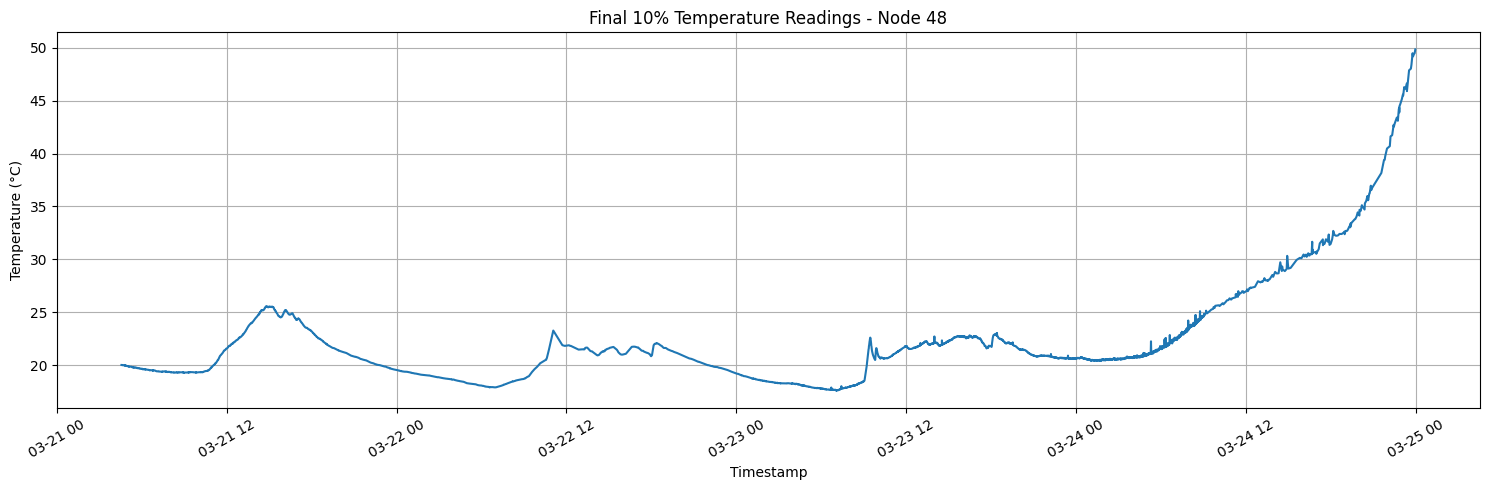

In [78]:
# STEP 17.3 - INVESTIGATE FINAL TEMPERATURE TREND

import matplotlib.pyplot as plt

valid_temp = node_data[
    node_data["temperature"].between(-10, 50)
].copy()

# Focus on the final 10% of records
last_count = max(1, int(len(valid_temp) * 0.10))

final_section = valid_temp.tail(last_count)

plt.figure(figsize=(15, 5))

plt.plot(
    final_section["timestamp"],
    final_section["temperature"]
)

plt.title("Final 10% Temperature Readings - Node 48")
plt.xlabel("Timestamp")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

In [79]:
# STEP 18 - COMPARE TEMPERATURE QUALITY ACROSS CANDIDATE NODES

for node in candidate_nodes:

    data = valid_id_df[
        valid_id_df["moteid"] == node
    ].sort_values("timestamp")

    valid = data[
        data["temperature"].between(-10, 50)
    ]

    print(
        f"Node {node}: "
        f"Records={len(data)}, "
        f"Valid temperature={len(valid)}, "
        f"Median={valid['temperature'].median():.2f} °C, "
        f"Maximum={valid['temperature'].max():.2f} °C"
    )

Node 48: Records=58226, Valid temperature=55836, Median=21.07 °C, Maximum=49.86 °C
Node 22: Records=60165, Valid temperature=55203, Median=22.55 °C, Maximum=49.99 °C
Node 47: Records=57201, Valid temperature=54907, Median=21.20 °C, Maximum=49.99 °C
Node 45: Records=53245, Valid temperature=53195, Median=21.56 °C, Maximum=45.68 °C
Node 31: Records=65693, Valid temperature=52819, Median=21.87 °C, Maximum=49.92 °C
Node 21: Records=58525, Valid temperature=49607, Median=22.75 °C, Maximum=49.91 °C
Node 23: Records=62440, Valid temperature=48482, Median=22.64 °C, Maximum=49.94 °C
Node 29: Records=64391, Valid temperature=47563, Median=21.87 °C, Maximum=49.96 °C
Node 36: Records=57743, Valid temperature=46795, Median=21.67 °C, Maximum=49.72 °C
Node 46: Records=52988, Valid temperature=46359, Median=21.50 °C, Maximum=49.91 °C


In [80]:
sample_node = 45

node_data = valid_id_df[
    valid_id_df["moteid"] == sample_node
].sort_values("timestamp").copy()

print("NODE:", sample_node)
print("Total records:", len(node_data))

# 1. Last 30 readings
display(
    node_data[
        ["timestamp", "temperature", "humidity", "light", "voltage"]
    ].tail(30)
)

# 2. Sensor value statistics
display(
    node_data[
        ["temperature", "humidity", "light", "voltage"]
    ].describe()
)

# 3. Count suspicious readings
print("Temperature outside -10 to 50:",
      (~node_data["temperature"].between(-10, 50)).sum())

print("Humidity outside 0 to 100:",
      (~node_data["humidity"].between(0, 100)).sum())

print("Negative light readings:",
      (node_data["light"] < 0).sum())

print("Missing voltage readings:",
      node_data["voltage"].isna().sum())

# 4. Sampling interval statistics
node_data["time_gap"] = (
    node_data["timestamp"].diff().dt.total_seconds()
)

display(node_data["time_gap"].describe())

NODE: 45
Total records: 53245


,timestamp,temperature,humidity,light,voltage
1993747,2004-03-24 03:37:59.392273,55.5624,47.4405,0.92,2.27556
1993751,2004-03-24 03:38:01.523806,55.5722,47.4405,0.92,2.27556
1993890,2004-03-24 03:41:45.287894,56.0328,47.4731,0.92,2.27556
1993911,2004-03-24 03:42:31.252442,56.1308,47.4731,0.92,2.27556
1994067,2004-03-24 03:46:02.527679,56.7384,47.5057,0.92,2.27556
1994168,2004-03-24 03:48:40.054296,56.9932,47.5383,0.92,2.27556
1994486,2004-03-24 03:57:02.899273,57.5126,47.6035,0.92,2.27556
1994887,2004-03-24 04:07:19.773246,58.9434,47.6035,0.92,2.27556
1995039,2004-03-24 04:11:01.945995,59.6882,47.6687,0.92,2.27556
1995131,2004-03-24 04:13:02.497620,60.2076,47.6361,0.92,2.27556


,temperature,humidity,light,voltage
count,53245.000000,53245.000000,53245.000000,53245.000000
mean,21.846607,39.602704,422.616484,2.555972
std,3.293981,5.571944,520.063245,0.109066
min,15.549000,19.366300,0.460000,2.266870
25%,19.880600,35.853000,35.880000,2.474670
50%,21.556400,40.568000,121.440000,2.593540
75%,23.065600,43.485700,713.920000,2.639640
max,79.288200,53.063400,1847.360000,2.762420


Temperature outside -10 to 50: 50
Humidity outside 0 to 100: 0
Negative light readings: 0
Missing voltage readings: 0


,time_gap
count,53244.000000
mean,40.895886
std,488.407185
min,0.016515
25%,26.945740
50%,31.170789
75%,37.830284
max,88314.785895


In [81]:
import pandas as pd
import numpy as np

quality_results = []

for node in candidate_nodes:

    data = (
        valid_id_df[valid_id_df["moteid"] == node]
        .sort_values("timestamp")
        .copy()
    )

    gaps = data["timestamp"].diff().dt.total_seconds()

    valid_temp = data["temperature"].between(-10, 50)
    valid_humidity = data["humidity"].between(0, 100)

    quality_results.append({
        "Node": node,
        "Total Records": len(data),
        "Valid Temp (%)": round(valid_temp.mean() * 100, 2),
        "Valid Humidity (%)": round(valid_humidity.mean() * 100, 2),
        "Valid Light (%)": round(data["light"].ge(0).mean() * 100, 2),
        "Voltage Available (%)": round(data["voltage"].notna().mean() * 100, 2),
        "Median Gap (sec)": round(gaps.median(), 2),
        "Gaps > 5 min": int((gaps > 300).sum()),
        "Gaps > 1 hour": int((gaps > 3600).sum()),
        "First Reading": data["timestamp"].min(),
        "Last Reading": data["timestamp"].max()
    })

quality_comparison = pd.DataFrame(quality_results)

display(
    quality_comparison.sort_values(
        by=["Valid Temp (%)", "Valid Humidity (%)"],
        ascending=False
    )
)

,Node,Total Records,Valid Temp (%),Valid Humidity (%),Valid Light (%),Voltage Available (%),Median Gap (sec),Gaps > 5 min,Gaps > 1 hour,First Reading,Last Reading
3,45,53245,99.91,100.00,100.00,100.00,31.17,153,3,2004-02-28 01:06:46.696192,2004-03-24 05:57:47.242191
2,47,57201,95.99,96.77,100.00,99.40,31.10,688,24,2004-02-28 01:06:46.625200,2004-04-01 23:18:51.756517
0,48,58226,95.90,96.53,100.00,99.98,30.98,705,27,2004-02-28 01:06:46.323955,2004-04-01 23:20:51.919631
1,22,60165,91.75,96.38,100.00,100.00,30.70,379,4,2004-02-28 00:59:16.853347,2004-03-30 09:13:44.335816
9,46,52988,87.49,95.62,100.00,100.00,31.64,567,21,2004-02-28 01:06:46.232475,2004-03-30 22:11:24.839738
5,21,58525,84.76,93.39,99.99,99.99,30.89,517,6,2004-02-28 01:01:16.934932,2004-03-30 06:43:44.702613
8,36,57743,81.04,85.17,99.98,97.60,32.46,360,3,2004-02-28 01:03:16.179903,2004-04-01 23:52:19.758425
4,31,65693,80.40,85.36,99.99,99.99,30.17,42,4,2004-02-28 00:58:46.910403,2004-03-30 23:58:45.825942
6,23,62440,77.65,83.61,99.96,99.95,30.97,253,5,2004-02-28 00:59:16.521007,2004-04-02 15:32:49.628609
7,29,64391,73.87,82.32,99.99,99.99,30.23,115,2,2004-02-28 00:59:46.081919,2004-04-01 23:22:04.262660


In [82]:
# Calculate the common recording period

selected_nodes = [45, 22, 31, 47, 48]

selected_data = valid_id_df[
    valid_id_df["moteid"].isin(selected_nodes)
].copy()

node_coverage = selected_data.groupby("moteid").agg(
    first_reading=("timestamp", "min"),
    last_reading=("timestamp", "max"),
    total_records=("timestamp", "count")
)

display(node_coverage)

common_start = node_coverage["first_reading"].max()
common_end = node_coverage["last_reading"].min()

print("COMMON START:", common_start)
print("COMMON END:", common_end)
print("COMMON DURATION:", common_end - common_start)

,first_reading,last_reading,total_records
moteid,,,
22,2004-02-28 00:59:16.853347,2004-03-30 09:13:44.335816,60165
31,2004-02-28 00:58:46.910403,2004-03-30 23:58:45.825942,65693
45,2004-02-28 01:06:46.696192,2004-03-24 05:57:47.242191,53245
47,2004-02-28 01:06:46.625200,2004-04-01 23:18:51.756517,57201
48,2004-02-28 01:06:46.323955,2004-04-01 23:20:51.919631,58226


COMMON START: 2004-02-28 01:06:46.696192
COMMON END: 2004-03-24 05:57:47.242191
COMMON DURATION: 25 days 04:51:00.545999


In [83]:
# PHASE 7 — STEP 1: Create selected-node dataset

selected_nodes = [22, 31, 45, 47, 48]

common_start = node_coverage["first_reading"].max()
common_end = node_coverage["last_reading"].min()

intel_selected = valid_id_df[
    (valid_id_df["moteid"].isin(selected_nodes)) &
    (valid_id_df["timestamp"] >= common_start) &
    (valid_id_df["timestamp"] <= common_end)
].copy()

# Sort chronologically
intel_selected = intel_selected.sort_values(
    ["timestamp", "moteid"]
).reset_index(drop=True)

print("DATASET CREATED")
print("-------------------------")
print("Total records:", len(intel_selected))
print("Selected nodes:", sorted(intel_selected["moteid"].unique()))
print("Start:", intel_selected["timestamp"].min())
print("End:", intel_selected["timestamp"].max())

print("\nRecords per node:")
display(intel_selected.groupby("moteid").size())

print("\nFirst 10 records:")
display(intel_selected.head(10))

DATASET CREATED
-------------------------
Total records: 272278
Selected nodes: [np.int64(22), np.int64(31), np.int64(45), np.int64(47), np.int64(48)]
Start: 2004-02-28 01:06:46.696192
End: 2004-03-24 05:57:47.242191

Records per node:


,0
moteid,
22,55773
31,53502
45,53245
47,54455
48,55303



First 10 records:


,date,time,epoch,moteid,temperature,humidity,light,voltage,timestamp
0,2004-02-28,01:06:46.696192,18,45,18.3518,38.1213,172.96,2.68742,2004-02-28 01:06:46.696192
1,2004-02-28,01:07:16.105166,19,47,18.1264,40.0268,655.04,2.67532,2004-02-28 01:07:16.105166
2,2004-02-28,01:07:16.170384,19,31,18.5674,41.5789,136.16,2.68742,2004-02-28 01:07:16.170384
3,2004-02-28,01:07:16.672035,19,48,18.0186,39.4842,114.08,2.69964,2004-02-28 01:07:16.672035
4,2004-02-28,01:07:16.906579,19,22,18.7536,38.8039,79.12,2.66332,2004-02-28 01:07:16.906579
5,2004-02-28,01:07:46.500631,20,48,18.0186,39.4842,114.08,2.69964,2004-02-28 01:07:46.500631
6,2004-02-28,01:07:46.539046,20,47,18.1068,40.0607,655.04,2.67532,2004-02-28 01:07:46.539046
7,2004-02-28,01:07:46.607597,20,45,18.2832,38.3263,172.96,2.68742,2004-02-28 01:07:46.607597
8,2004-02-28,01:07:49.683883,20,31,18.5478,41.5789,136.16,2.68742,2004-02-28 01:07:49.683883
9,2004-02-28,01:07:49.735092,20,22,18.7536,38.8039,79.12,2.66332,2004-02-28 01:07:49.735092


In [84]:
# STEP 2.1: DATA QUALITY ASSESSMENT

print("MISSING VALUES")
display(intel_selected.isnull().sum())

print("\nPHYSICALLY IMPLAUSIBLE READINGS")

quality_report = []

for node in selected_nodes:

    data = intel_selected[
        intel_selected["moteid"] == node
    ]

    quality_report.append({
        "Node": node,
        "Total": len(data),
        "Invalid Temperature": (
            ~data["temperature"].between(-10, 50)
        ).sum(),
        "Invalid Humidity": (
            ~data["humidity"].between(0, 100)
        ).sum(),
        "Negative Light": (data["light"] < 0).sum(),
        "Invalid Voltage": (
            ~data["voltage"].between(1.8, 3.3)
        ).sum()
    })

quality_report_df = pd.DataFrame(quality_report)

display(quality_report_df)

MISSING VALUES


,0
date,0
time,0
epoch,0
moteid,0
temperature,0
humidity,1
light,1
voltage,243
timestamp,0



PHYSICALLY IMPLAUSIBLE READINGS


,Node,Total,Invalid Temperature,Invalid Humidity,Negative Light,Invalid Voltage
0,22,55773,572,1,0,1
1,31,53502,700,0,0,0
2,45,53245,50,0,0,0
3,47,54455,0,0,0,231
4,48,55303,0,0,0,11


In [85]:
# STEP 2.2: CHECK REPEATED SENSOR VALUES

for node in selected_nodes:

    data = (
        intel_selected[intel_selected["moteid"] == node]
        .sort_values("timestamp")
    )

    print(f"\nNODE {node}")

    for col in ["temperature", "humidity", "light", "voltage"]:

        repeated = (
            data[col]
            .eq(data[col].shift())
            .sum()
        )

        percentage = repeated / max(len(data) - 1, 1) * 100

        print(
            f"{col}: {percentage:.2f}% consecutive readings unchanged"
        )


NODE 22
temperature: 26.27% consecutive readings unchanged
humidity: 33.04% consecutive readings unchanged
light: 82.63% consecutive readings unchanged
voltage: 75.66% consecutive readings unchanged

NODE 31
temperature: 24.22% consecutive readings unchanged
humidity: 25.61% consecutive readings unchanged
light: 85.73% consecutive readings unchanged
voltage: 70.90% consecutive readings unchanged

NODE 45
temperature: 27.82% consecutive readings unchanged
humidity: 33.14% consecutive readings unchanged
light: 84.91% consecutive readings unchanged
voltage: 72.03% consecutive readings unchanged

NODE 47
temperature: 26.10% consecutive readings unchanged
humidity: 32.04% consecutive readings unchanged
light: 89.87% consecutive readings unchanged
voltage: 75.25% consecutive readings unchanged

NODE 48
temperature: 31.51% consecutive readings unchanged
humidity: 38.81% consecutive readings unchanged
light: 86.47% consecutive readings unchanged
voltage: 70.35% consecutive readings unchanged


In [86]:
# Preserve original selected measurements
intel_selected_raw = intel_selected.copy()

# Create a separate working dataset
intel_clean = intel_selected.copy()

print("Raw dataset:", intel_selected_raw.shape)
print("Working dataset:", intel_clean.shape)

Raw dataset: (272278, 9)
Working dataset: (272278, 9)


In [87]:
# Temperature quality flag
intel_clean["temperature_valid"] = (
    intel_clean["temperature"].between(-10, 50)
)

# Humidity quality flag
intel_clean["humidity_valid"] = (
    intel_clean["humidity"].between(0, 100)
)

# Light quality flag
intel_clean["light_valid"] = (
    intel_clean["light"].ge(0)
)

# Voltage quality flag
intel_clean["voltage_valid"] = (
    intel_clean["voltage"].between(1.8, 3.3)
)

# Combined environmental measurement quality
intel_clean["environment_valid"] = (
    intel_clean["temperature_valid"] &
    intel_clean["humidity_valid"] &
    intel_clean["light_valid"]
)

display(
    intel_clean[
        [
            "moteid",
            "temperature_valid",
            "humidity_valid",
            "light_valid",
            "voltage_valid",
            "environment_valid"
        ]
    ].groupby("moteid").mean().round(4) * 100
)

,temperature_valid,humidity_valid,light_valid,voltage_valid,environment_valid
moteid,,,,,
22,98.97,100.0,100.0,100.00,98.97
31,98.69,100.0,100.0,100.00,98.69
45,99.91,100.0,100.0,100.00,99.91
47,100.00,100.0,100.0,99.58,100.00
48,100.00,100.0,100.0,99.98,100.00


In [88]:
# Create quality-controlled sensor measurements

intel_clean["temperature_clean"] = (
    intel_clean["temperature"].where(
        intel_clean["temperature_valid"]
    )
)

intel_clean["humidity_clean"] = (
    intel_clean["humidity"].where(
        intel_clean["humidity_valid"]
    )
)

intel_clean["light_clean"] = (
    intel_clean["light"].where(
        intel_clean["light_valid"]
    )
)

intel_clean["voltage_clean"] = (
    intel_clean["voltage"].where(
        intel_clean["voltage_valid"]
    )
)

print("QUALITY CONTROL COMPLETED")

display(
    intel_clean[
        [
            "timestamp",
            "moteid",
            "temperature",
            "temperature_clean",
            "humidity",
            "humidity_clean",
            "voltage",
            "voltage_clean"
        ]
    ].head(15)
)

QUALITY CONTROL COMPLETED


,timestamp,moteid,temperature,temperature_clean,humidity,humidity_clean,voltage,voltage_clean
0,2004-02-28 01:06:46.696192,45,18.3518,18.3518,38.1213,38.1213,2.68742,2.68742
1,2004-02-28 01:07:16.105166,47,18.1264,18.1264,40.0268,40.0268,2.67532,2.67532
2,2004-02-28 01:07:16.170384,31,18.5674,18.5674,41.5789,41.5789,2.68742,2.68742
3,2004-02-28 01:07:16.672035,48,18.0186,18.0186,39.4842,39.4842,2.69964,2.69964
4,2004-02-28 01:07:16.906579,22,18.7536,18.7536,38.8039,38.8039,2.66332,2.66332
5,2004-02-28 01:07:46.500631,48,18.0186,18.0186,39.4842,39.4842,2.69964,2.69964
6,2004-02-28 01:07:46.539046,47,18.1068,18.1068,40.0607,40.0607,2.67532,2.67532
7,2004-02-28 01:07:46.607597,45,18.2832,18.2832,38.3263,38.3263,2.68742,2.68742
8,2004-02-28 01:07:49.683883,31,18.5478,18.5478,41.5789,41.5789,2.68742,2.68742
9,2004-02-28 01:07:49.735092,22,18.7536,18.7536,38.8039,38.8039,2.66332,2.66332


In [89]:
import os

os.makedirs("/content/datasets", exist_ok=True)

intel_selected_raw.to_csv(
    "/content/datasets/intel_selected_raw.csv",
    index=False
)

intel_clean.to_csv(
    "/content/datasets/intel_selected_clean.csv",
    index=False
)

print("FILES EXPORTED")
print("---------------------------")
print("Raw dataset: intel_selected_raw.csv")
print("Quality-controlled dataset: intel_selected_clean.csv")

print("\nRaw records:", len(intel_selected_raw))
print("Clean dataset records:", len(intel_clean))
print("Selected nodes:", sorted(intel_clean["moteid"].unique()))

FILES EXPORTED
---------------------------
Raw dataset: intel_selected_raw.csv
Quality-controlled dataset: intel_selected_clean.csv

Raw records: 272278
Clean dataset records: 272278
Selected nodes: [np.int64(22), np.int64(31), np.int64(45), np.int64(47), np.int64(48)]


In [90]:
import pandas as pd
import numpy as np
import time

# Load quality-controlled dataset
playback_df = pd.read_csv(
    "/content/datasets/intel_selected_clean.csv"
)

# Convert timestamp
playback_df["timestamp"] = pd.to_datetime(
    playback_df["timestamp"]
)

# Sort chronologically
playback_df = playback_df.sort_values(
    ["timestamp", "moteid"]
).reset_index(drop=True)

# Verify dataset
print("PLAYBACK ENGINE DATA LOADED")
print("--------------------------------")
print("Total records:", len(playback_df))
print("Sensor nodes:", sorted(playback_df["moteid"].unique()))
print("Start:", playback_df["timestamp"].min())
print("End:", playback_df["timestamp"].max())

print("\nColumns:")
print(playback_df.columns.tolist())

print("\nFirst 5 records:")
display(playback_df.head())

PLAYBACK ENGINE DATA LOADED
--------------------------------
Total records: 272278
Sensor nodes: [np.int64(22), np.int64(31), np.int64(45), np.int64(47), np.int64(48)]
Start: 2004-02-28 01:06:46.696192
End: 2004-03-24 05:57:47.242191

Columns:
['date', 'time', 'epoch', 'moteid', 'temperature', 'humidity', 'light', 'voltage', 'timestamp', 'temperature_valid', 'humidity_valid', 'light_valid', 'voltage_valid', 'environment_valid', 'temperature_clean', 'humidity_clean', 'light_clean', 'voltage_clean']

First 5 records:


,date,time,epoch,moteid,temperature,humidity,light,voltage,timestamp,temperature_valid,humidity_valid,light_valid,voltage_valid,environment_valid,temperature_clean,humidity_clean,light_clean,voltage_clean
0,2004-02-28,01:06:46.696192,18,45,18.3518,38.1213,172.96,2.68742,2004-02-28 01:06:46.696192,True,True,True,True,True,18.3518,38.1213,172.96,2.68742
1,2004-02-28,01:07:16.105166,19,47,18.1264,40.0268,655.04,2.67532,2004-02-28 01:07:16.105166,True,True,True,True,True,18.1264,40.0268,655.04,2.67532
2,2004-02-28,01:07:16.170384,19,31,18.5674,41.5789,136.16,2.68742,2004-02-28 01:07:16.170384,True,True,True,True,True,18.5674,41.5789,136.16,2.68742
3,2004-02-28,01:07:16.672035,19,48,18.0186,39.4842,114.08,2.69964,2004-02-28 01:07:16.672035,True,True,True,True,True,18.0186,39.4842,114.08,2.69964
4,2004-02-28,01:07:16.906579,19,22,18.7536,38.8039,79.12,2.66332,2004-02-28 01:07:16.906579,True,True,True,True,True,18.7536,38.8039,79.12,2.66332


In [91]:
# Calculate actual time differences
playback_df["time_difference"] = (
    playback_df["timestamp"].diff().dt.total_seconds()
)

print("PLAYBACK TIMING ANALYSIS")
print("--------------------------------")

display(
    playback_df["time_difference"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print(
    "\nTotal playback duration:",
    playback_df["timestamp"].max() -
    playback_df["timestamp"].min()
)

PLAYBACK TIMING ANALYSIS
--------------------------------


,time_difference
count,272277.000000
mean,7.997225
std,213.813384
min,0.000085
25%,1.043693
50%,3.236776
75%,11.321895
90%,22.568265
95%,25.658432
99%,29.832839



Total playback duration: 25 days 04:51:00.545999


In [95]:
class SensorPlaybackEngine:

    def __init__(self, dataframe, speed=60):

        self.df = dataframe.sort_values(
            ["timestamp", "moteid"]
        ).reset_index(drop=True)

        self.speed = speed
        self.cursor = 0

        self.total_records = len(self.df)

        self.current_time = None

        self.node_state = {
            node: {
                "temperature": None,
                "humidity": None,
                "light": None,
                "voltage": None,
                "last_update": None,
                "records_received": 0
            }
            for node in sorted(self.df["moteid"].unique())
        }

        self.previous_timestamp = None

    def reset(self):

        self.cursor = 0
        self.current_time = None
        self.previous_timestamp = None

        for node in self.node_state:
            self.node_state[node] = {
                "temperature": None,
                "humidity": None,
                "light": None,
                "voltage": None,
                "last_update": None,
                "records_received": 0
            }

    def step(self):

        if self.cursor >= self.total_records:
            return None

        row = self.df.iloc[self.cursor]

        timestamp = row["timestamp"]
        node = int(row["moteid"])

        if self.previous_timestamp is None:
            delay = 0
        else:
            historical_gap = (
                timestamp - self.previous_timestamp
            ).total_seconds()

            delay = historical_gap / self.speed

        self.current_time = timestamp

        self.node_state[node] = {
            "temperature": row["temperature_clean"],
            "humidity": row["humidity_clean"],
            "light": row["light_clean"],
            "voltage": row["voltage_clean"],
            "last_update": timestamp,
            "records_received":
                self.node_state[node]["records_received"] + 1
        }

        event = {
            "timestamp": timestamp,
            "node_id": node,
            "temperature": row["temperature_clean"],
            "humidity": row["humidity_clean"],
            "light": row["light_clean"],
            "voltage": row["voltage_clean"],
            "playback_delay": delay
        }

        self.previous_timestamp = timestamp
        self.cursor += 1

        return event

    def progress(self):

        return (self.cursor / self.total_records) * 100

In [96]:
# Create playback engine
engine = SensorPlaybackEngine(
    playback_df,
    speed=60
)

print("PLAYBACK ENGINE INITIALIZED")
print("--------------------------------")
print("Total records:", engine.total_records)
print("Playback speed:", engine.speed, "x")
print("Available nodes:", list(engine.node_state.keys()))
print("Initial cursor:", engine.cursor)
print("Initial progress:", engine.progress(), "%")

PLAYBACK ENGINE INITIALIZED
--------------------------------
Total records: 272278
Playback speed: 60 x
Available nodes: [np.int64(22), np.int64(31), np.int64(45), np.int64(47), np.int64(48)]
Initial cursor: 0
Initial progress: 0.0 %


In [97]:
# Process the first 10 sensor records
for i in range(10):
    event = engine.step()

    print(
        f"Record {i+1} | "
        f"Time: {event['timestamp']} | "
        f"Node: {event['node_id']} | "
        f"Temperature: {event['temperature']} | "
        f"Humidity: {event['humidity']} | "
        f"Light: {event['light']} | "
        f"Voltage: {event['voltage']} | "
        f"Playback delay: {event['playback_delay']:.4f}s"
    )

print("\nPLAYBACK STATUS")
print("-------------------------")
print("Processed records:", engine.cursor)
print("Progress:", round(engine.progress(), 4), "%")

print("\nCURRENT NODE STATES")
display(pd.DataFrame(engine.node_state).T)

Record 1 | Time: 2004-02-28 01:06:46.696192 | Node: 45 | Temperature: 18.3518 | Humidity: 38.1213 | Light: 172.96 | Voltage: 2.68742 | Playback delay: 0.0000s
Record 2 | Time: 2004-02-28 01:07:16.105166 | Node: 47 | Temperature: 18.1264 | Humidity: 40.0268 | Light: 655.04 | Voltage: 2.67532 | Playback delay: 0.4901s
Record 3 | Time: 2004-02-28 01:07:16.170384 | Node: 31 | Temperature: 18.5674 | Humidity: 41.5789 | Light: 136.16 | Voltage: 2.68742 | Playback delay: 0.0011s
Record 4 | Time: 2004-02-28 01:07:16.672035 | Node: 48 | Temperature: 18.0186 | Humidity: 39.4842 | Light: 114.08 | Voltage: 2.69964 | Playback delay: 0.0084s
Record 5 | Time: 2004-02-28 01:07:16.906579 | Node: 22 | Temperature: 18.7536 | Humidity: 38.8039 | Light: 79.12 | Voltage: 2.66332 | Playback delay: 0.0039s
Record 6 | Time: 2004-02-28 01:07:46.500631 | Node: 48 | Temperature: 18.0186 | Humidity: 39.4842 | Light: 114.08 | Voltage: 2.69964 | Playback delay: 0.4932s
Record 7 | Time: 2004-02-28 01:07:46.539046 | N

,temperature,humidity,light,voltage,last_update,records_received
22,18.7536,38.8039,79.12,2.66332,2004-02-28 01:07:49.735092,2
31,18.5478,41.5789,136.16,2.68742,2004-02-28 01:07:49.683883,2
45,18.2832,38.3263,172.96,2.68742,2004-02-28 01:07:46.607597,2
47,18.1068,40.0607,655.04,2.67532,2004-02-28 01:07:46.539046,2
48,18.0186,39.4842,114.08,2.69964,2004-02-28 01:07:46.500631,2


In [98]:
class PlaybackController:

    def __init__(self, engine):
        self.engine = engine
        self.status = "STOPPED"

    def start(self):
        if self.engine.cursor >= self.engine.total_records:
            print("Playback completed. Reset to start again.")
            return

        self.status = "PLAYING"
        print("Playback started.")

    def pause(self):
        if self.status == "PLAYING":
            self.status = "PAUSED"
            print("Playback paused.")
        else:
            print("Playback is not currently running.")

    def resume(self):
        if self.status == "PAUSED":
            self.status = "PLAYING"
            print("Playback resumed.")
        else:
            print("Playback is not paused.")

    def reset(self):
        self.engine.reset()
        self.status = "STOPPED"
        print("Playback reset to beginning.")

    def set_speed(self, speed):
        if speed not in [1, 10, 30, 60, 120]:
            print("Invalid speed. Choose 1, 10, 30, 60, or 120.")
            return

        self.engine.speed = speed
        print(f"Playback speed set to {speed}x.")

    def next_record(self):
        if self.status != "PLAYING":
            print("Start or resume playback first.")
            return None

        event = self.engine.step()

        if event is None:
            self.status = "COMPLETED"
            print("Playback completed.")
            return None

        return event

    def get_status(self):
        return {
            "status": self.status,
            "speed": self.engine.speed,
            "processed_records": self.engine.cursor,
            "total_records": self.engine.total_records,
            "progress_percent": round(self.engine.progress(), 4)
        }


controller = PlaybackController(engine)

print("PLAYBACK CONTROLLER INITIALIZED")
print(controller.get_status())

PLAYBACK CONTROLLER INITIALIZED
{'status': 'STOPPED', 'speed': 60, 'processed_records': 10, 'total_records': 272278, 'progress_percent': 0.0037}


In [99]:
# TEST 1: START
controller.start()
print(controller.get_status())

# TEST 2: PROCESS 3 RECORDS
print("\nProcessing records:")
for i in range(3):
    event = controller.next_record()
    print(
        f"Node: {event['node_id']} | "
        f"Time: {event['timestamp']} | "
        f"Temperature: {event['temperature']}"
    )

# TEST 3: PAUSE
print("\nPausing:")
controller.pause()
print(controller.get_status())

# TEST 4: ATTEMPT PROCESSING WHILE PAUSED
print("\nTesting paused state:")
result = controller.next_record()
print("Result:", result)

# TEST 5: RESUME
print("\nResuming:")
controller.resume()
event = controller.next_record()
print("Next record:", event)

# TEST 6: CHANGE SPEED
print("\nChanging speed:")
controller.set_speed(120)
print(controller.get_status())

# TEST 7: RESET
print("\nResetting:")
controller.reset()
print(controller.get_status())

Playback started.
{'status': 'PLAYING', 'speed': 60, 'processed_records': 10, 'total_records': 272278, 'progress_percent': 0.0037}

Processing records:
Node: 45 | Time: 2004-02-28 01:08:16.010914 | Temperature: 18.2636
Node: 31 | Time: 2004-02-28 01:08:16.031888 | Temperature: 18.538
Node: 47 | Time: 2004-02-28 01:08:16.570817 | Temperature: 18.0872

Pausing:
Playback paused.
{'status': 'PAUSED', 'speed': 60, 'processed_records': 13, 'total_records': 272278, 'progress_percent': 0.0048}

Testing paused state:
Start or resume playback first.
Result: None

Resuming:
Playback resumed.
Next record: {'timestamp': Timestamp('2004-02-28 01:08:16.650603'), 'node_id': 48, 'temperature': np.float64(18.0186), 'humidity': np.float64(39.4502), 'light': np.float64(114.08), 'voltage': np.float64(2.69964), 'playback_delay': 0.0013297666666666666}

Changing speed:
Playback speed set to 120x.
{'status': 'PLAYING', 'speed': 120, 'processed_records': 14, 'total_records': 272278, 'progress_percent': 0.0051}

In [100]:
import numpy as np
import pandas as pd

analysis_df = playback_df.copy()

analysis_df = analysis_df.sort_values(
    ["moteid", "timestamp"]
).reset_index(drop=True)

# Calculate time gaps and sensor changes separately for each node
analysis_df["time_gap_sec"] = (
    analysis_df.groupby("moteid")["timestamp"]
    .diff()
    .dt.total_seconds()
)

analysis_df["temp_change"] = (
    analysis_df.groupby("moteid")["temperature_clean"]
    .diff().abs()
)

analysis_df["humidity_change"] = (
    analysis_df.groupby("moteid")["humidity_clean"]
    .diff().abs()
)

analysis_df["light_change"] = (
    analysis_df.groupby("moteid")["light_clean"]
    .diff().abs()
)

# Calculate rates of change per minute
analysis_df["temp_rate"] = (
    analysis_df["temp_change"] /
    (analysis_df["time_gap_sec"] / 60)
)

analysis_df["humidity_rate"] = (
    analysis_df["humidity_change"] /
    (analysis_df["time_gap_sec"] / 60)
)

# Remove invalid or non-positive time gaps for statistical analysis
valid_analysis = analysis_df[
    (analysis_df["time_gap_sec"] > 0) &
    (analysis_df["time_gap_sec"] <= 300)
].copy()

print("REAL DATA SENSOR BEHAVIOUR")
print("=" * 60)

print("\nSampling interval statistics:")
display(
    valid_analysis.groupby("moteid")["time_gap_sec"]
    .describe()
    .round(2)
)

print("\nTemperature change statistics:")
display(
    valid_analysis.groupby("moteid")["temp_change"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
    .round(4)
)

print("\nHumidity change statistics:")
display(
    valid_analysis.groupby("moteid")["humidity_change"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
    .round(4)
)

print("\nTemperature rate statistics (°C/min):")
display(
    valid_analysis.groupby("moteid")["temp_rate"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
    .round(4)
)

REAL DATA SENSOR BEHAVIOUR

Sampling interval statistics:


,count,mean,std,min,25%,50%,75%,max
moteid,,,,,,,,
22,55698.0,35.69,19.91,0.10,27.36,30.50,36.56,299.99
31,53492.0,37.73,18.75,0.02,29.73,30.15,32.56,297.51
45,53091.0,36.06,19.09,0.02,26.93,31.14,37.73,299.91
47,54272.0,34.84,16.98,0.08,26.71,30.91,36.83,299.20
48,55129.0,34.32,16.45,0.06,26.66,30.78,36.36,299.78



Temperature change statistics:


,0.50,0.75,0.90,0.95,0.99
moteid,,,,,
22,0.0098,0.0196,0.0686,0.1176,0.3332
31,0.0098,0.0294,0.0588,0.0882,0.2646
45,0.0098,0.0196,0.0392,0.0686,0.1568
47,0.0098,0.0294,0.0588,0.0980,0.2352
48,0.0098,0.0196,0.0294,0.0490,0.1274



Humidity change statistics:


,0.50,0.75,0.90,0.95,0.99
moteid,,,,,
22,0.0343,0.0704,0.1387,0.2003,0.3975
31,0.0358,0.0982,0.1665,0.2340,0.4557
45,0.0339,0.0692,0.1391,0.2083,0.4085
47,0.0337,0.0705,0.1698,0.2654,0.5537
48,0.0333,0.0669,0.1067,0.1677,0.3472



Temperature rate statistics (°C/min):


,0.50,0.75,0.90,0.95,0.99
moteid,,,,,
22,0.0201,0.0467,0.1298,0.2366,0.9321
31,0.0197,0.0403,0.0970,0.1473,0.4803
45,0.0197,0.0403,0.0803,0.1237,0.3083
47,0.0209,0.0489,0.1206,0.1992,0.4934
48,0.0188,0.0343,0.0608,0.0946,0.2623


In [101]:
import pandas as pd
import numpy as np

# Start with the original cleaned historical dataset
calibration_df = playback_df.copy()

calibration_df = calibration_df.sort_values(
    ["moteid", "timestamp"]
).reset_index(drop=True)

# Divide by chronological time, not random rows
start_time = calibration_df["timestamp"].min()
end_time = calibration_df["timestamp"].max()

total_duration = end_time - start_time
calibration_end = start_time + (total_duration * 0.20)

# Create separate periods
calibration_data = calibration_df[
    calibration_df["timestamp"] < calibration_end
].copy()

evaluation_data = calibration_df[
    calibration_df["timestamp"] >= calibration_end
].copy()

print("CHRONOLOGICAL DATA SPLIT")
print("=" * 55)

print("Start:", start_time)
print("Calibration ends:", calibration_end)
print("End:", end_time)

print("\nCalibration records:", len(calibration_data))
print("Evaluation records:", len(evaluation_data))

print(
    "Calibration percentage:",
    round(len(calibration_data) / len(calibration_df) * 100, 2)
)

print(
    "Evaluation percentage:",
    round(len(evaluation_data) / len(calibration_df) * 100, 2)
)

CHRONOLOGICAL DATA SPLIT
Start: 2004-02-28 01:06:46.696192
Calibration ends: 2004-03-04 02:04:58.805391800
End: 2004-03-24 05:57:47.242191

Calibration records: 61680
Evaluation records: 210598
Calibration percentage: 22.65
Evaluation percentage: 77.35


In [102]:
# Calculate changes using calibration data only

calibration_data = calibration_data.sort_values(
    ["moteid", "timestamp"]
).copy()

grouped = calibration_data.groupby("moteid")

calibration_data["time_gap_sec"] = (
    grouped["timestamp"].diff().dt.total_seconds()
)

for column, change_column in [
    ("temperature_clean", "temp_change"),
    ("humidity_clean", "humidity_change"),
    ("light_clean", "light_change")
]:
    calibration_data[change_column] = (
        calibration_data.groupby("moteid")[column]
        .diff()
        .abs()
    )

# Keep valid consecutive observations with reasonable time gaps
calibration_valid = calibration_data[
    (calibration_data["time_gap_sec"] > 0) &
    (calibration_data["time_gap_sec"] <= 300)
].copy()

# Calculate per-node calibration thresholds
threshold_statistics = (
    calibration_valid.groupby("moteid")[
        ["temp_change", "humidity_change", "light_change"]
    ]
    .quantile([0.90, 0.95, 0.99])
)

print("CALIBRATION CHANGE STATISTICS")
display(threshold_statistics.round(5))

CALIBRATION CHANGE STATISTICS


temp_change  humidity_change  light_change
moteid                                                 
22     0.90      0.06860          0.16828         14.72
       0.95      0.11760          0.24419         29.44
       0.99      0.32232          0.60621         88.32
31     0.90      0.04900          0.14450         14.72
       0.95      0.06860          0.21150         58.88
       0.99      0.13720          0.39070        117.76
45     0.90      0.03920          0.13920         14.72
       0.95      0.05880          0.20837         29.44
       0.99      0.16660          0.41907         95.68
47     0.90      0.05880          0.16400         14.72
       0.95      0.09800          0.24310         58.88
       0.99      0.21923          0.50417        117.76
48     0.90      0.02940          0.13420         14.72
       0.95      0.05880          0.19940         29.44
       0.99      0.16660          0.44786         58.88

In [103]:
rate_calibration = calibration_data.copy()

rate_calibration = rate_calibration.sort_values(
    ["moteid", "timestamp"]
).reset_index(drop=True)

grouped = rate_calibration.groupby("moteid")

rate_calibration["time_gap_sec"] = (
    grouped["timestamp"].diff().dt.total_seconds()
)

for column, change_column in [
    ("temperature_clean", "temp_change"),
    ("humidity_clean", "humidity_change"),
    ("light_clean", "light_change")
]:
    rate_calibration[change_column] = (
        rate_calibration.groupby("moteid")[column]
        .diff()
        .abs()
    )

# Convert changes into rates per minute
valid_rate_data = rate_calibration[
    (rate_calibration["time_gap_sec"] > 0) &
    (rate_calibration["time_gap_sec"] <= 300)
].copy()

for sensor in ["temp", "humidity", "light"]:
    valid_rate_data[f"{sensor}_rate"] = (
        valid_rate_data[f"{sensor}_change"] /
        (valid_rate_data["time_gap_sec"] / 60)
    )

# Calculate calibration-only rate distributions
rate_statistics = (
    valid_rate_data.groupby("moteid")[
        ["temp_rate", "humidity_rate", "light_rate"]
    ]
    .quantile([0.90, 0.95, 0.99])
)

print("CALIBRATION RATE STATISTICS")
print("=" * 60)

display(rate_statistics.round(5))

CALIBRATION RATE STATISTICS


temp_rate  humidity_rate  light_rate
moteid                                           
22     0.90    0.13866        0.34304    26.44133
       0.95    0.22965        0.52815    59.00992
       0.99    1.00091        1.75133   203.57879
31     0.90    0.07868        0.27616    29.31459
       0.95    0.11680        0.40353    59.83526
       0.99    0.25621        0.75009   189.68355
45     0.90    0.07362        0.27325    28.02205
       0.95    0.11562        0.41884    60.28344
       0.99    0.39366        1.12204   233.20588
47     0.90    0.11669        0.31942    18.33917
       0.95    0.19911        0.51012    79.41893
       0.99    0.59771        1.40635   227.70579
48     0.90    0.06366        0.24708    17.06435
       0.95    0.10926        0.38429    54.24820
       0.99    0.39342        1.16783   147.13386

In [104]:
# Extract calibration-only percentile thresholds

rate_thresholds = {}

for node in sorted(calibration_data["moteid"].unique()):

    rate_thresholds[int(node)] = {
        "temp_p90": rate_statistics.loc[(node, 0.90), "temp_rate"],
        "temp_p95": rate_statistics.loc[(node, 0.95), "temp_rate"],

        "humidity_p90": rate_statistics.loc[(node, 0.90), "humidity_rate"],
        "humidity_p95": rate_statistics.loc[(node, 0.95), "humidity_rate"],

        "light_p90": rate_statistics.loc[(node, 0.90), "light_rate"],
        "light_p95": rate_statistics.loc[(node, 0.95), "light_rate"]
    }

print("RATE-BASED ALGORITHM CONFIGURATION")
print("=" * 65)

for node, thresholds in rate_thresholds.items():

    print(f"\nNode {node}")

    for parameter, value in thresholds.items():
        print(f"{parameter}: {value:.5f}")

RATE-BASED ALGORITHM CONFIGURATION

Node 22
temp_p90: 0.13866
temp_p95: 0.22965
humidity_p90: 0.34304
humidity_p95: 0.52815
light_p90: 26.44133
light_p95: 59.00992

Node 31
temp_p90: 0.07868
temp_p95: 0.11680
humidity_p90: 0.27616
humidity_p95: 0.40353
light_p90: 29.31459
light_p95: 59.83526

Node 45
temp_p90: 0.07362
temp_p95: 0.11562
humidity_p90: 0.27325
humidity_p95: 0.41884
light_p90: 28.02205
light_p95: 60.28344

Node 47
temp_p90: 0.11669
temp_p95: 0.19911
humidity_p90: 0.31942
humidity_p95: 0.51012
light_p90: 18.33917
light_p95: 79.41893

Node 48
temp_p90: 0.06366
temp_p95: 0.10926
humidity_p90: 0.24708
humidity_p95: 0.38429
light_p90: 17.06435
light_p95: 54.24820


In [105]:
threshold_config = {}

for node in sorted(calibration_data["moteid"].unique()):

    threshold_config[int(node)] = {
        "temperature": threshold_statistics.loc[(node, 0.95), "temp_change"],
        "humidity": threshold_statistics.loc[(node, 0.95), "humidity_change"],
        "light": threshold_statistics.loc[(node, 0.95), "light_change"]
    }

print("THRESHOLD-BASED ALGORITHM CONFIGURATION")
print("=" * 65)

for node, thresholds in threshold_config.items():

    print(f"\nNode {node}")

    for parameter, value in thresholds.items():
        print(f"{parameter}: {value:.5f}")

THRESHOLD-BASED ALGORITHM CONFIGURATION

Node 22
temperature: 0.11760
humidity: 0.24419
light: 29.44000

Node 31
temperature: 0.06860
humidity: 0.21150
light: 58.88000

Node 45
temperature: 0.05880
humidity: 0.20837
light: 29.44000

Node 47
temperature: 0.09800
humidity: 0.24310
light: 58.88000

Node 48
temperature: 0.05880
humidity: 0.19940
light: 29.44000


In [2]:
import pandas as pd
import numpy as np

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

FIXED_INTERVAL = 60

RATE_INTERVALS = {
    "LOW": 90,
    "MEDIUM": 60,
    "HIGH": 30
}

SENSORS = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

# --------------------------------------------------
# COMMON SIMULATION ENGINE
# --------------------------------------------------

def simulate_algorithm(data, algorithm):

    df = data.sort_values(
        ["timestamp", "moteid"]
    ).reset_index(drop=True)

    results = []

    node_states = {}

    for node in sorted(df["moteid"].unique()):

        node_states[int(node)] = {
            "last_tx_time": None,
            "last_tx_values": {
                sensor: None for sensor in SENSORS
            },
            "previous_values": {
                sensor: None for sensor in SENSORS
            },
            "previous_times": {
                sensor: None for sensor in SENSORS
            }
        }

    for row in df.itertuples(index=False):

        node = int(row.moteid)
        timestamp = row.timestamp

        state = node_states[node]

        current_values = {
            sensor: getattr(row, column)
            for sensor, column in SENSORS.items()
        }

        valid_values = {
            sensor: value
            for sensor, value in current_values.items()
            if pd.notna(value)
        }

        if not valid_values:
            continue

        last_tx_time = state["last_tx_time"]

        transmit = False
        activity = None
        selected_interval = None

        # ------------------------------------------
        # FIRST READING
        # ------------------------------------------

        if last_tx_time is None:

            transmit = True

            if algorithm == "RATE":
                activity = "INITIAL"
                selected_interval = 30

        # ------------------------------------------
        # FIXED SAMPLING
        # ------------------------------------------

        elif algorithm == "FIXED":

            elapsed = (
                timestamp - last_tx_time
            ).total_seconds()

            transmit = elapsed >= FIXED_INTERVAL

        # ------------------------------------------
        # THRESHOLD-BASED SAMPLING
        # ------------------------------------------

        elif algorithm == "THRESHOLD":

            for sensor, value in valid_values.items():

                previous = state["last_tx_values"][sensor]

                if previous is None:
                    transmit = True
                    break

                difference = abs(value - previous)

                threshold = threshold_config[node][sensor]

                if difference >= threshold:
                    transmit = True
                    break

        # ------------------------------------------
        # RATE-BASED SAMPLING
        # ------------------------------------------

        elif algorithm == "RATE":

            max_activity = "LOW"

            for sensor, value in valid_values.items():

                previous = state["previous_values"][sensor]
                previous_time = state["previous_times"][sensor]

                if previous is None or previous_time is None:
                    continue

                gap = (
                    timestamp - previous_time
                ).total_seconds()

                if gap <= 0 or gap > 300:
                    continue

                rate = abs(value - previous) / (gap / 60)

                limits = rate_thresholds[node]

                if rate >= limits[f"{sensor}_p95"]:
                    max_activity = "HIGH"
                    break

                elif rate >= limits[f"{sensor}_p90"]:
                    max_activity = "MEDIUM"

            activity = max_activity

            selected_interval = RATE_INTERVALS[activity]

            elapsed = (
                timestamp - last_tx_time
            ).total_seconds()

            transmit = elapsed >= selected_interval

        # ------------------------------------------
        # RECORD TRANSMISSION
        # ------------------------------------------

        if transmit:

            results.append({
                "timestamp": timestamp,
                "moteid": node,
                "temperature": current_values["temperature"],
                "humidity": current_values["humidity"],
                "light": current_values["light"],
                "voltage": row.voltage_clean,
                "algorithm": algorithm,
                "activity": activity,
                "transmission_interval": selected_interval
            })

            state["last_tx_time"] = timestamp

            # Update threshold reference only on transmission
            for sensor, value in valid_values.items():
                state["last_tx_values"][sensor] = value

        # ------------------------------------------
        # UPDATE PREVIOUS OBSERVATIONS
        # ------------------------------------------

        # Rate calculations use consecutive available
        # valid observations, not only transmitted ones.

        for sensor, value in valid_values.items():

            state["previous_values"][sensor] = value
            state["previous_times"][sensor] = timestamp

    return pd.DataFrame(results)


# --------------------------------------------------
# RUN ALL THREE ALGORITHMS
# --------------------------------------------------

print("RUNNING ALGORITHMS ON INTEL EVALUATION DATA")
print("=" * 65)

fixed_results = simulate_algorithm(
    evaluation_data, "FIXED"
)

threshold_results = simulate_algorithm(
    evaluation_data, "THRESHOLD"
)

rate_results = simulate_algorithm(
    evaluation_data, "RATE"
)

print("\nSIMULATION COMPLETED")

print("Evaluation records:", len(evaluation_data))

print("\nTRANSMISSIONS GENERATED")

print("Fixed:", len(fixed_results))
print("Threshold:", len(threshold_results))
print("Rate:", len(rate_results))

RUNNING ALGORITHMS ON INTEL EVALUATION DATA


NameError: name 'evaluation_data' is not defined

In [3]:
# Restore the dataset split

calibration_df = playback_df.copy()

calibration_df = calibration_df.sort_values(
    ["timestamp", "moteid"]
).reset_index(drop=True)

start_time = calibration_df["timestamp"].min()
end_time = calibration_df["timestamp"].max()

calibration_end = start_time + (
    (end_time - start_time) * 0.20
)

calibration_data = calibration_df[
    calibration_df["timestamp"] < calibration_end
].copy()

evaluation_data = calibration_df[
    calibration_df["timestamp"] >= calibration_end
].copy()

print("DATA SPLIT RESTORED")
print("------------------------------")
print("Calibration records:", len(calibration_data))
print("Evaluation records:", len(evaluation_data))
print("Calibration end:", calibration_end)

NameError: name 'playback_df' is not defined

In [4]:
import os

print("CHECKING PROJECT FILES")
print("=" * 50)

paths = [
    "/content/datasets/intel_selected_raw.csv",
    "/content/datasets/intel_selected_clean.csv",
    "/content/datasets/sensor_measurements.csv",
    "/content/intel_data.txt",
    "/content/intel_data.txt.gz"
]

for path in paths:
    print(
        f"{'FOUND' if os.path.exists(path) else 'MISSING'}: {path}"
    )

CHECKING PROJECT FILES
MISSING: /content/datasets/intel_selected_raw.csv
MISSING: /content/datasets/intel_selected_clean.csv
MISSING: /content/datasets/sensor_measurements.csv
MISSING: /content/intel_data.txt
MISSING: /content/intel_data.txt.gz


In [5]:
import os
import gzip
import shutil
import urllib.request
import pandas as pd
import numpy as np

# Create project directories
os.makedirs("/content/datasets", exist_ok=True)

# Official Intel dataset
url = "https://db.csail.mit.edu/labdata/data.txt.gz"

gz_path = "/content/intel_data.txt.gz"
txt_path = "/content/intel_data.txt"

print("Downloading original Intel sensor dataset...")

urllib.request.urlretrieve(url, gz_path)

print("Download completed.")
print("Compressed size:", round(os.path.getsize(gz_path) / (1024**2), 2), "MB")

# Extract
print("\nExtracting dataset...")

with gzip.open(gz_path, "rb") as source:
    with open(txt_path, "wb") as destination:
        shutil.copyfileobj(source, destination)

print("Extraction completed.")
print("Extracted size:", round(os.path.getsize(txt_path) / (1024**2), 2), "MB")

# Load original data
columns = [
    "date", "time", "epoch", "moteid",
    "temperature", "humidity", "light", "voltage"
]

intel_df = pd.read_csv(
    txt_path,
    sep=r"\s+",
    names=columns,
    header=None
)

# Convert timestamps
intel_df["timestamp"] = pd.to_datetime(
    intel_df["date"].astype(str) + " " +
    intel_df["time"].astype(str),
    errors="coerce"
)

# Convert numerical columns
numeric_columns = [
    "epoch", "moteid", "temperature",
    "humidity", "light", "voltage"
]

for col in numeric_columns:
    intel_df[col] = pd.to_numeric(
        intel_df[col],
        errors="coerce"
    )

intel_df = intel_df.sort_values(
    ["timestamp", "moteid"]
).reset_index(drop=True)

print("\nORIGINAL DATASET RESTORED")
print("=" * 50)
print("Shape:", intel_df.shape)
print("Unique sensor IDs:", intel_df["moteid"].nunique())
print("Start:", intel_df["timestamp"].min())
print("End:", intel_df["timestamp"].max())

Download completed.
Compressed size: 32.83 MB

Extracting dataset...
Extraction completed.
Extracted size: 143.92 MB

ORIGINAL DATASET RESTORED
Shape: (2313682, 9)
Unique sensor IDs: 61
Start: 2004-02-28 00:58:15.315133
End: 2004-04-05 11:02:32.715337


In [6]:
# Retain official deployment nodes 1–54
valid_id_df = intel_df[
    intel_df["moteid"].between(1, 54) &
    intel_df["timestamp"].notna()
].copy()

valid_id_df["moteid"] = valid_id_df["moteid"].astype(int)

# Our previously selected five nodes
selected_nodes = [22, 31, 45, 47, 48]

selected_data = valid_id_df[
    valid_id_df["moteid"].isin(selected_nodes)
].copy()

# Determine common observation period
node_coverage = selected_data.groupby("moteid").agg(
    first_reading=("timestamp", "min"),
    last_reading=("timestamp", "max"),
    total_records=("timestamp", "count")
)

common_start = node_coverage["first_reading"].max()
common_end = node_coverage["last_reading"].min()

# Extract common period
intel_selected = valid_id_df[
    (valid_id_df["moteid"].isin(selected_nodes)) &
    (valid_id_df["timestamp"] >= common_start) &
    (valid_id_df["timestamp"] <= common_end)
].copy()

intel_selected = intel_selected.sort_values(
    ["timestamp", "moteid"]
).reset_index(drop=True)

# Restore quality flags
intel_clean = intel_selected.copy()

intel_clean["temperature_valid"] = (
    intel_clean["temperature"].between(-10, 50)
)

intel_clean["humidity_valid"] = (
    intel_clean["humidity"].between(0, 100)
)

intel_clean["light_valid"] = (
    intel_clean["light"].ge(0)
)

intel_clean["voltage_valid"] = (
    intel_clean["voltage"].between(1.8, 3.3)
)

intel_clean["environment_valid"] = (
    intel_clean["temperature_valid"] &
    intel_clean["humidity_valid"] &
    intel_clean["light_valid"]
)

intel_clean["temperature_clean"] = (
    intel_clean["temperature"].where(
        intel_clean["temperature_valid"]
    )
)

intel_clean["humidity_clean"] = (
    intel_clean["humidity"].where(
        intel_clean["humidity_valid"]
    )
)

intel_clean["light_clean"] = (
    intel_clean["light"].where(
        intel_clean["light_valid"]
    )
)

intel_clean["voltage_clean"] = (
    intel_clean["voltage"].where(
        intel_clean["voltage_valid"]
    )
)

# Save reconstructed datasets
intel_selected.to_csv(
    "/content/datasets/intel_selected_raw.csv",
    index=False
)

intel_clean.to_csv(
    "/content/datasets/intel_selected_clean.csv",
    index=False
)

print("FIVE-NODE DATASET RESTORED")
print("=" * 55)

print("Selected nodes:", selected_nodes)
print("Total records:", len(intel_clean))
print("Common start:", common_start)
print("Common end:", common_end)

print("\nRecords per node:")
display(intel_clean.groupby("moteid").size().to_frame("records"))

print("\nSaved files:")
print("/content/datasets/intel_selected_raw.csv")
print("/content/datasets/intel_selected_clean.csv")

FIVE-NODE DATASET RESTORED
Selected nodes: [22, 31, 45, 47, 48]
Total records: 272278
Common start: 2004-02-28 01:06:46.696192
Common end: 2004-03-24 05:57:47.242191

Records per node:


,records
moteid,
22,55773
31,53502
45,53245
47,54455
48,55303



Saved files:
/content/datasets/intel_selected_raw.csv
/content/datasets/intel_selected_clean.csv


In [7]:
import pandas as pd
import numpy as np

# Load the reconstructed clean dataset
playback_df = pd.read_csv(
    "/content/datasets/intel_selected_clean.csv"
)

playback_df["timestamp"] = pd.to_datetime(
    playback_df["timestamp"]
)

playback_df = playback_df.sort_values(
    ["timestamp", "moteid"]
).reset_index(drop=True)

# ---------------------------------------
# CHRONOLOGICAL SPLIT
# ---------------------------------------

start_time = playback_df["timestamp"].min()
end_time = playback_df["timestamp"].max()

calibration_end = start_time + (
    (end_time - start_time) * 0.20
)

calibration_data = playback_df[
    playback_df["timestamp"] < calibration_end
].copy()

evaluation_data = playback_df[
    playback_df["timestamp"] >= calibration_end
].copy()

# ---------------------------------------
# CALCULATE CALIBRATION CHANGES
# ---------------------------------------

calibration_data = calibration_data.sort_values(
    ["moteid", "timestamp"]
).copy()

grouped = calibration_data.groupby("moteid")

calibration_data["time_gap_sec"] = (
    grouped["timestamp"].diff().dt.total_seconds()
)

sensor_columns = {
    "temp": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

for sensor, column in sensor_columns.items():

    calibration_data[f"{sensor}_change"] = (
        calibration_data.groupby("moteid")[column]
        .diff()
        .abs()
    )

calibration_valid = calibration_data[
    (calibration_data["time_gap_sec"] > 0) &
    (calibration_data["time_gap_sec"] <= 300)
].copy()

# ---------------------------------------
# THRESHOLD CONFIGURATION
# ---------------------------------------

threshold_statistics = (
    calibration_valid.groupby("moteid")[
        ["temp_change", "humidity_change", "light_change"]
    ].quantile([0.90, 0.95, 0.99])
)

threshold_config = {}

for node in sorted(calibration_data["moteid"].unique()):

    node = int(node)

    threshold_config[node] = {
        "temperature": threshold_statistics.loc[
            (node, 0.95), "temp_change"
        ],
        "humidity": threshold_statistics.loc[
            (node, 0.95), "humidity_change"
        ],
        "light": threshold_statistics.loc[
            (node, 0.95), "light_change"
        ]
    }

# ---------------------------------------
# RATE CONFIGURATION
# ---------------------------------------

for sensor in ["temp", "humidity", "light"]:

    calibration_valid[f"{sensor}_rate"] = (
        calibration_valid[f"{sensor}_change"] /
        (calibration_valid["time_gap_sec"] / 60)
    )

rate_statistics = (
    calibration_valid.groupby("moteid")[
        ["temp_rate", "humidity_rate", "light_rate"]
    ].quantile([0.90, 0.95, 0.99])
)

rate_thresholds = {}

for node in sorted(calibration_data["moteid"].unique()):

    node = int(node)

    rate_thresholds[node] = {}

    for sensor in ["temp", "humidity", "light"]:

        rate_thresholds[node][f"{sensor}_p90"] = (
            rate_statistics.loc[
                (node, 0.90), f"{sensor}_rate"
            ]
        )

        rate_thresholds[node][f"{sensor}_p95"] = (
            rate_statistics.loc[
                (node, 0.95), f"{sensor}_rate"
            ]
        )

# ---------------------------------------
# VERIFY RECOVERY
# ---------------------------------------

print("EXPERIMENTAL ENVIRONMENT RESTORED")
print("=" * 60)

print("Total records:", len(playback_df))
print("Calibration records:", len(calibration_data))
print("Evaluation records:", len(evaluation_data))
print("Calibration end:", calibration_end)

print("\nThreshold configurations:", len(threshold_config))
print("Rate configurations:", len(rate_thresholds))

print("\nRESTORED THRESHOLD CONFIGURATION")
display(pd.DataFrame(threshold_config).T.round(5))

print("\nRESTORED RATE CONFIGURATION")
display(pd.DataFrame(rate_thresholds).T.round(5))

print("\nVERIFICATION")
print("Dataset:", len(playback_df) == 272278)
print("Nodes:", sorted(playback_df["moteid"].unique()))
print("Threshold config:", len(threshold_config) == 5)
print("Rate config:", len(rate_thresholds) == 5)

EXPERIMENTAL ENVIRONMENT RESTORED
Total records: 272278
Calibration records: 61680
Evaluation records: 210598
Calibration end: 2004-03-04 02:04:58.805391800

Threshold configurations: 5
Rate configurations: 5

RESTORED THRESHOLD CONFIGURATION


,temperature,humidity,light
22,0.1176,0.24419,29.44
31,0.0686,0.21150,58.88
45,0.0588,0.20837,29.44
47,0.0980,0.24310,58.88
48,0.0588,0.19940,29.44



RESTORED RATE CONFIGURATION


,temp_p90,temp_p95,humidity_p90,humidity_p95,light_p90,light_p95
22,0.13866,0.22965,0.34304,0.52815,26.44133,59.00992
31,0.07868,0.11680,0.27616,0.40353,29.31459,59.83526
45,0.07362,0.11562,0.27325,0.41884,28.02205,60.28344
47,0.11669,0.19911,0.31942,0.51012,18.33917,79.41893
48,0.06366,0.10926,0.24708,0.38429,17.06435,54.24820



VERIFICATION
Dataset: True
Nodes: [np.int64(22), np.int64(31), np.int64(45), np.int64(47), np.int64(48)]
Threshold config: True
Rate config: True


In [8]:
from google.colab import drive
import os
import json

# Connect Google Drive
drive.mount('/content/drive')

# Create permanent project folder
PROJECT_DIR = "/content/drive/MyDrive/Adaptive_IoT_Major_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Save cleaned dataset
playback_df.to_csv(
    f"{PROJECT_DIR}/intel_selected_clean.csv",
    index=False
)

# Save original selected measurements
intel_selected.to_csv(
    f"{PROJECT_DIR}/intel_selected_raw.csv",
    index=False
)

# Save calibration configurations
config = {
    "fixed_interval_seconds": 60,
    "rate_intervals": {
        "LOW": 90,
        "MEDIUM": 60,
        "HIGH": 30
    },
    "threshold_config": threshold_config,
    "rate_thresholds": rate_thresholds,
    "selected_nodes": [22, 31, 45, 47, 48],
    "calibration_end": str(calibration_end)
}

with open(
    f"{PROJECT_DIR}/algorithm_configuration.json",
    "w"
) as file:
    json.dump(config, file, indent=4)

print("PROJECT BACKUP COMPLETED")
print("=" * 50)

for filename in os.listdir(PROJECT_DIR):
    print(filename)

Mounted at /content/drive
PROJECT BACKUP COMPLETED
intel_selected_clean.csv
intel_selected_raw.csv
algorithm_configuration.json


In [9]:
import pandas as pd
import numpy as np

FIXED_INTERVAL = 60

RATE_INTERVALS = {
    "LOW": 90,
    "MEDIUM": 60,
    "HIGH": 30
}

SENSORS = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

RATE_SENSOR_NAMES = {
    "temperature": "temp",
    "humidity": "humidity",
    "light": "light"
}


def simulate_algorithm(data, algorithm):

    df = data.sort_values(
        ["timestamp", "moteid"]
    ).reset_index(drop=True)

    results = []

    node_states = {
        int(node): {
            "last_tx_time": None,
            "last_tx_values": {
                sensor: None for sensor in SENSORS
            },
            "previous_values": {
                sensor: None for sensor in SENSORS
            },
            "previous_times": {
                sensor: None for sensor in SENSORS
            }
        }
        for node in df["moteid"].unique()
    }

    for row in df.itertuples(index=False):

        node = int(row.moteid)
        timestamp = row.timestamp
        state = node_states[node]

        current_values = {
            sensor: getattr(row, column)
            for sensor, column in SENSORS.items()
        }

        valid_values = {
            sensor: value
            for sensor, value in current_values.items()
            if pd.notna(value)
        }

        # Skip records without valid environmental readings
        if not valid_values:
            continue

        last_tx_time = state["last_tx_time"]

        transmit = False
        activity = None
        selected_interval = None

        # First valid observation for each node
        if last_tx_time is None:

            transmit = True

            if algorithm == "RATE":
                activity = "INITIAL"
                selected_interval = RATE_INTERVALS["HIGH"]

        # Fixed sampling
        elif algorithm == "FIXED":

            elapsed = (
                timestamp - last_tx_time
            ).total_seconds()

            transmit = elapsed >= FIXED_INTERVAL

        # Threshold-based sampling
        elif algorithm == "THRESHOLD":

            for sensor, value in valid_values.items():

                previous = state["last_tx_values"][sensor]

                if previous is None:
                    transmit = True
                    break

                difference = abs(value - previous)

                threshold = threshold_config[node][sensor]

                if difference >= threshold:
                    transmit = True
                    break

        # Rate-based sampling
        elif algorithm == "RATE":

            max_activity = "LOW"

            for sensor, value in valid_values.items():

                previous = state["previous_values"][sensor]
                previous_time = state["previous_times"][sensor]

                if previous is None or previous_time is None:
                    continue

                gap = (
                    timestamp - previous_time
                ).total_seconds()

                if gap <= 0 or gap > 300:
                    continue

                rate = abs(value - previous) / (gap / 60)

                rate_sensor = RATE_SENSOR_NAMES[sensor]
                limits = rate_thresholds[node]

                if rate >= limits[f"{rate_sensor}_p95"]:
                    max_activity = "HIGH"
                    break

                elif (
                    rate >= limits[f"{rate_sensor}_p90"]
                    and max_activity != "HIGH"
                ):
                    max_activity = "MEDIUM"

            activity = max_activity
            selected_interval = RATE_INTERVALS[activity]

            elapsed = (
                timestamp - last_tx_time
            ).total_seconds()

            transmit = elapsed >= selected_interval

        else:
            raise ValueError("Unknown algorithm")

        # Store transmission
        if transmit:

            results.append({
                "timestamp": timestamp,
                "moteid": node,
                "temperature": current_values["temperature"],
                "humidity": current_values["humidity"],
                "light": current_values["light"],
                "voltage": row.voltage_clean,
                "algorithm": algorithm,
                "activity": activity,
                "transmission_interval": selected_interval
            })

            state["last_tx_time"] = timestamp

            for sensor, value in valid_values.items():
                state["last_tx_values"][sensor] = value

        # Update previous valid observations
        for sensor, value in valid_values.items():

            state["previous_values"][sensor] = value
            state["previous_times"][sensor] = timestamp

    return pd.DataFrame(results)


# Run all algorithms
print("RUNNING INTEL DATASET SIMULATION")
print("=" * 60)

fixed_results = simulate_algorithm(
    evaluation_data, "FIXED"
)

threshold_results = simulate_algorithm(
    evaluation_data, "THRESHOLD"
)

rate_results = simulate_algorithm(
    evaluation_data, "RATE"
)

print("\nSIMULATION COMPLETED")

print("Evaluation records:", len(evaluation_data))

print("\nTRANSMISSION COUNTS")
print("Fixed:", len(fixed_results))
print("Threshold:", len(threshold_results))
print("Rate:", len(rate_results))

RUNNING INTEL DATASET SIMULATION

SIMULATION COMPLETED
Evaluation records: 210598

TRANSMISSION COUNTS
Fixed: 90571
Threshold: 41718
Rate: 76311


In [10]:
# Eligible records: at least one valid environmental measurement
eligible_data = evaluation_data[
    evaluation_data["environment_valid"]
].copy()

eligible_count = len(eligible_data)

results = {
    "Fixed": fixed_results,
    "Threshold": threshold_results,
    "Rate": rate_results
}

print("TRANSMISSION PERFORMANCE")
print("=" * 65)
print(f"Eligible evaluation records: {eligible_count:,}\n")

for name, result in results.items():
    transmissions = len(result)
    reduction = (1 - transmissions / eligible_count) * 100

    print(f"{name} Algorithm")
    print(f"  Transmissions: {transmissions:,}")
    print(f"  Transmission reduction: {reduction:.2f}%")
    print()

print("NODE-WISE TRANSMISSION COUNTS")
print("=" * 65)

for name, result in results.items():
    print(f"\n{name}")
    print(result.groupby("moteid").size())

TRANSMISSION PERFORMANCE
Eligible evaluation records: 209,275

Fixed Algorithm
  Transmissions: 90,571
  Transmission reduction: 56.72%

Threshold Algorithm
  Transmissions: 41,718
  Transmission reduction: 80.07%

Rate Algorithm
  Transmissions: 76,311
  Transmission reduction: 63.54%

NODE-WISE TRANSMISSION COUNTS

Fixed
moteid
22    18420
31    18698
45    17726
47    17805
48    17922
dtype: int64

Threshold
moteid
22    7541
31    9545
45    9050
47    7567
48    8015
dtype: int64

Rate
moteid
22    15282
31    16191
45    15135
47    14807
48    14896
dtype: int64


In [11]:
import numpy as np
import pandas as pd

algorithms = {
    "Fixed": fixed_results,
    "Threshold": threshold_results,
    "Rate": rate_results
}

sensor_columns = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

accuracy_results = []

for algorithm_name, transmissions in algorithms.items():

    reconstructed_parts = []

    for node in sorted(evaluation_data["moteid"].unique()):

        actual = evaluation_data[
            evaluation_data["moteid"] == node
        ].sort_values("timestamp").copy()

        sent = transmissions[
            transmissions["moteid"] == node
        ].sort_values("timestamp").copy()

        if sent.empty:
            continue

        # Retain the most recently transmitted valid value
        # independently for each sensor.
        for sensor in ["temp", "humidity", "light"]:
            sent[sensor] = sent[sensor].ffill()

        # Match each original observation with the latest
        # transmission available at that timestamp.
        merged = pd.merge_asof(
            actual,
            sent[["timestamp", "temp", "humidity", "light"]],
            on="timestamp",
            direction="backward"
        )

        for sensor, actual_column in sensor_columns.items():

            predicted_column = sensor

            valid = (
                merged[actual_column].notna()
                & merged[predicted_column].notna()
            )

            actual_values = merged.loc[valid, actual_column]
            predicted_values = merged.loc[valid, predicted_column]

            if len(actual_values) == 0:
                continue

            errors = actual_values - predicted_values

            accuracy_results.append({
                "Algorithm": algorithm_name,
                "Node": node,
                "Sensor": sensor,
                "MAE": np.mean(np.abs(errors)),
                "RMSE": np.sqrt(np.mean(errors ** 2)),
                "Valid Comparisons": len(actual_values),
                "Coverage (%)": valid.sum() / merged[actual_column].notna().sum() * 100
            })

accuracy_df = pd.DataFrame(accuracy_results)

print("SENSOR RECONSTRUCTION ACCURACY")
print("=" * 80)

summary = accuracy_df.groupby(
    ["Algorithm", "Sensor"]
).agg({
    "MAE": "mean",
    "RMSE": "mean",
    "Coverage (%)": "mean"
}).round(4)

print(summary)

print("\nNODE-WISE RESULTS")
print("=" * 80)
print(accuracy_df.round(4).to_string(index=False))

KeyError: 'temp'

In [12]:
print("FIXED RESULTS:")
print(fixed_results.columns.tolist())
print(fixed_results.head(3))

print("\nTHRESHOLD RESULTS:")
print(threshold_results.columns.tolist())

print("\nRATE RESULTS:")
print(rate_results.columns.tolist())


FIXED RESULTS:
['timestamp', 'moteid', 'temperature', 'humidity', 'light', 'voltage', 'algorithm', 'activity', 'transmission_interval']
                   timestamp  moteid  temperature  humidity  light  voltage  \
0 2004-03-04 02:04:59.299717      47      17.6070   43.2191   0.46  2.60491   
1 2004-03-04 02:05:00.099723      48      17.6168   42.4509   0.46  2.61639   
2 2004-03-04 02:05:27.589118      31      18.8026   39.5860   0.92  2.63964   

  algorithm activity transmission_interval  
0     FIXED     None                  None  
1     FIXED     None                  None  
2     FIXED     None                  None  

THRESHOLD RESULTS:
['timestamp', 'moteid', 'temperature', 'humidity', 'light', 'voltage', 'algorithm', 'activity', 'transmission_interval']

RATE RESULTS:
['timestamp', 'moteid', 'temperature', 'humidity', 'light', 'voltage', 'algorithm', 'activity', 'transmission_interval']


In [13]:
import numpy as np
import pandas as pd

algorithms = {
    "Fixed": fixed_results,
    "Threshold": threshold_results,
    "Rate": rate_results
}

sensor_columns = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

accuracy_results = []

for algorithm_name, transmissions in algorithms.items():

    for node in sorted(evaluation_data["moteid"].unique()):

        actual = evaluation_data[
            evaluation_data["moteid"] == node
        ][["timestamp", *sensor_columns.values()]].copy()

        actual = actual.sort_values("timestamp")

        sent = transmissions[
            transmissions["moteid"] == node
        ][["timestamp", "temperature", "humidity", "light"]].copy()

        sent = sent.sort_values("timestamp")

        if sent.empty:
            continue

        # Carry forward the last transmitted value independently
        # for each sensor.
        sent[["temperature", "humidity", "light"]] = (
            sent[["temperature", "humidity", "light"]].ffill()
        )

        sent = sent.rename(columns={
            "temperature": "tx_temperature",
            "humidity": "tx_humidity",
            "light": "tx_light"
        })

        # Use only the latest transmission at or before
        # each original measurement timestamp.
        merged = pd.merge_asof(
            actual,
            sent,
            on="timestamp",
            direction="backward"
        )

        for sensor, actual_column in sensor_columns.items():

            predicted_column = f"tx_{sensor}"

            valid = (
                merged[actual_column].notna()
                & merged[predicted_column].notna()
            )

            actual_values = merged.loc[valid, actual_column]
            predicted_values = merged.loc[valid, predicted_column]

            if len(actual_values) == 0:
                continue

            errors = actual_values - predicted_values

            accuracy_results.append({
                "Algorithm": algorithm_name,
                "Node": node,
                "Sensor": sensor,
                "MAE": np.mean(np.abs(errors)),
                "RMSE": np.sqrt(np.mean(errors ** 2)),
                "Valid Comparisons": len(actual_values),
                "Coverage (%)": (
                    valid.sum() /
                    merged[actual_column].notna().sum()
                ) * 100
            })

accuracy_df = pd.DataFrame(accuracy_results)

print("SENSOR RECONSTRUCTION ACCURACY")
print("=" * 80)

summary = accuracy_df.groupby(
    ["Algorithm", "Sensor"]
).agg({
    "MAE": "mean",
    "RMSE": "mean",
    "Coverage (%)": "mean"
}).round(4)

print(summary)

print("\nNODE-WISE RESULTS")
print("=" * 80)
print(accuracy_df.round(4).to_string(index=False))

SENSOR RECONSTRUCTION ACCURACY
                          MAE     RMSE  Coverage (%)
Algorithm Sensor                                    
Fixed     humidity     0.0372   0.0987         100.0
          light        3.2482  24.6352         100.0
          temperature  0.0156   0.0705         100.0
Rate      humidity     0.0373   0.0810         100.0
          light        2.1205  18.0227         100.0
          temperature  0.0147   0.0575         100.0
Threshold humidity     0.0550   0.0794         100.0
          light        1.9532   6.8892         100.0
          temperature  0.0244   0.0334         100.0

NODE-WISE RESULTS
Algorithm  Node      Sensor    MAE    RMSE  Valid Comparisons  Coverage (%)
    Fixed    22 temperature 0.0214  0.1466              42388         100.0
    Fixed    22    humidity 0.0337  0.0962              42959         100.0
    Fixed    22       light 3.2315 16.1432              42959         100.0
    Fixed    31 temperature 0.0174  0.0857              41469  

In [14]:
import numpy as np
import pandas as pd

algorithms = {
    "Fixed": fixed_results,
    "Threshold": threshold_results,
    "Rate": rate_results
}

sensor_columns = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

freshness_results = []

for algorithm_name, transmissions in algorithms.items():

    for node in sorted(evaluation_data["moteid"].unique()):

        actual = evaluation_data[
            evaluation_data["moteid"] == node
        ][["timestamp", *sensor_columns.values()]].copy()

        sent = transmissions[
            transmissions["moteid"] == node
        ][["timestamp", "temperature", "humidity", "light"]].copy()

        actual = actual.sort_values("timestamp")
        sent = sent.sort_values("timestamp")

        if sent.empty:
            continue

        sent = sent.rename(columns={
            "temperature": "tx_temperature",
            "humidity": "tx_humidity",
            "light": "tx_light",
            "timestamp": "tx_timestamp"
        })

        merged = pd.merge_asof(
            actual,
            sent,
            left_on="timestamp",
            right_on="tx_timestamp",
            direction="backward"
        )

        merged["reading_age_seconds"] = (
            merged["timestamp"] - merged["tx_timestamp"]
        ).dt.total_seconds()

        for sensor, actual_column in sensor_columns.items():

            predicted_column = f"tx_{sensor}"

            valid = (
                merged[actual_column].notna()
                & merged[predicted_column].notna()
            )

            actual_values = merged.loc[valid, actual_column]
            predicted_values = merged.loc[valid, predicted_column]

            errors = actual_values - predicted_values

            freshness_results.append({
                "Algorithm": algorithm_name,
                "Node": node,
                "Sensor": sensor,
                "MAE": np.abs(errors).mean(),
                "RMSE": np.sqrt(np.mean(errors ** 2)),
                "Mean_Age_sec": merged.loc[
                    valid, "reading_age_seconds"
                ].mean(),
                "P95_Age_sec": merged.loc[
                    valid, "reading_age_seconds"
                ].quantile(0.95),
                "Max_Age_sec": merged.loc[
                    valid, "reading_age_seconds"
                ].max(),
                "Valid_Readings": valid.sum()
            })

freshness_df = pd.DataFrame(freshness_results)

print("POOLED RECONSTRUCTION AND FRESHNESS")
print("=" * 90)

pooled = freshness_df.groupby("Algorithm").apply(
    lambda g: pd.Series({
        "Temperature_MAE": np.average(
            g[g.Sensor == "temperature"].MAE,
            weights=g[g.Sensor == "temperature"].Valid_Readings
        ),
        "Humidity_MAE": np.average(
            g[g.Sensor == "humidity"].MAE,
            weights=g[g.Sensor == "humidity"].Valid_Readings
        ),
        "Light_MAE": np.average(
            g[g.Sensor == "light"].MAE,
            weights=g[g.Sensor == "light"].Valid_Readings
        ),
        "Mean_Age_sec": np.average(
            g.drop_duplicates("Node").Mean_Age_sec,
            weights=g.drop_duplicates("Node").Valid_Readings
        )
    })
).round(4)

print(pooled)

print("\nFRESHNESS DETAILS BY ALGORITHM AND SENSOR")
print("=" * 90)

print(
    freshness_df.groupby(["Algorithm", "Sensor"])[
        ["Mean_Age_sec", "P95_Age_sec", "Max_Age_sec"]
    ].mean().round(2)
)

POOLED RECONSTRUCTION AND FRESHNESS
           Temperature_MAE  Humidity_MAE  Light_MAE  Mean_Age_sec
Algorithm                                                        
Fixed               0.0156        0.0372     3.2460       21.9528
Rate                0.0147        0.0373     2.1207       31.9697
Threshold           0.0244        0.0551     1.9575      294.3283

FRESHNESS DETAILS BY ALGORITHM AND SENSOR
                       Mean_Age_sec  P95_Age_sec  Max_Age_sec
Algorithm Sensor                                             
Fixed     humidity            21.94        58.42        60.00
          light               21.94        58.42        60.00
          temperature         21.95        58.43        60.00
Rate      humidity            31.97        86.79        90.00
          light               31.97        86.79        90.00
          temperature         31.96        86.79        90.00
Threshold humidity           297.12      1126.25      5249.35
          light              297.

/tmp/ipykernel_478/2950268304.py:92: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pooled = freshness_df.groupby("Algorithm").apply(


In [15]:
import pandas as pd

algorithms = {
    "Fixed": fixed_results,
    "Threshold": threshold_results,
    "Rate": rate_results
}

gap_results = []

for name, result in algorithms.items():

    for node, group in result.groupby("moteid"):

        group = group.sort_values("timestamp").copy()

        gaps = (
            group["timestamp"]
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        gap_results.append({
            "Algorithm": name,
            "Node": node,
            "Mean_Gap_sec": gaps.mean(),
            "Median_Gap_sec": gaps.median(),
            "P95_Gap_sec": gaps.quantile(0.95),
            "Max_Gap_sec": gaps.max(),
            "Transmissions": len(group)
        })

gap_df = pd.DataFrame(gap_results)

print("TRANSMISSION INTERVAL ANALYSIS")
print("=" * 85)

print(
    gap_df.groupby("Algorithm")[
        ["Mean_Gap_sec", "Median_Gap_sec",
         "P95_Gap_sec", "Max_Gap_sec"]
    ].mean().round(2)
)

print("\nNODE-WISE INTERVALS")
print(gap_df.round(2).to_string(index=False))

TRANSMISSION INTERVAL ANALYSIS
           Mean_Gap_sec  Median_Gap_sec  P95_Gap_sec  Max_Gap_sec
Algorithm                                                        
Fixed             96.21           84.33       120.68     88391.74
Rate             114.26           97.33       148.66     88377.39
Threshold        210.62           89.30       753.21     88440.43

NODE-WISE INTERVALS
Algorithm  Node  Mean_Gap_sec  Median_Gap_sec  P95_Gap_sec  Max_Gap_sec  Transmissions
    Fixed    22         94.57           83.76       122.49     88315.43          18420
    Fixed    31         93.16           89.37       120.33     88100.36          18698
    Fixed    45         98.28           83.43       122.46     88355.82          17726
    Fixed    47         97.84           82.70       119.98     88803.28          17805
    Fixed    48         97.20           82.39       118.15     88383.81          17922
Threshold    22        230.86           86.88       879.96     88404.47           7541
Threshold

In [16]:
import pandas as pd

source_gap_results = []

for node, group in evaluation_data.groupby("moteid"):

    group = group.sort_values("timestamp")

    gaps = (
        group["timestamp"]
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    source_gap_results.append({
        "Node": node,
        "Mean_Source_Gap": gaps.mean(),
        "Median_Source_Gap": gaps.median(),
        "P95_Source_Gap": gaps.quantile(0.95),
        "Max_Source_Gap": gaps.max(),
        "Gaps_Above_5min": (gaps > 300).sum(),
        "Total_Records": len(group)
    })

source_gap_df = pd.DataFrame(source_gap_results)

print("SOURCE DATA GAP ANALYSIS")
print("=" * 85)
print(source_gap_df.round(2).to_string(index=False))

SOURCE DATA GAP ANALYSIS
 Node  Mean_Source_Gap  Median_Source_Gap  P95_Source_Gap  Max_Source_Gap  Gaps_Above_5min  Total_Records
   22            40.55              30.61           67.78        88258.15               74          42960
   31            41.31              30.15           66.04        88074.43                9          42169
   45            42.55              31.44           67.89        88314.79              153          40938
   47            41.49              31.12           64.56        88748.70              182          41990
   48            40.95              31.00           63.17        88347.34              173          42541


In [17]:
import pandas as pd

OUTAGE_THRESHOLD = 300

outage_aware_data = evaluation_data.copy()

outage_aware_data = outage_aware_data.sort_values(
    ["moteid", "timestamp"]
).reset_index(drop=True)

outage_aware_data["source_gap_seconds"] = (
    outage_aware_data.groupby("moteid")["timestamp"]
    .diff()
    .dt.total_seconds()
)

# First record and records following outages start new segments.
outage_aware_data["new_segment"] = (
    outage_aware_data["source_gap_seconds"].isna()
    | (outage_aware_data["source_gap_seconds"] > OUTAGE_THRESHOLD)
)

outage_aware_data["segment_id"] = (
    outage_aware_data.groupby("moteid")["new_segment"]
    .cumsum()
)

print("OUTAGE-AWARE DATASET")
print("=" * 65)

print("Total records:", len(outage_aware_data))
print("Nodes:", sorted(outage_aware_data["moteid"].unique()))
print("Outage threshold:", OUTAGE_THRESHOLD, "seconds")

print("\nSEGMENTS PER NODE")
print(
    outage_aware_data.groupby("moteid")["segment_id"]
    .nunique()
)

print("\nSEGMENT STATISTICS")
segment_stats = outage_aware_data.groupby(
    ["moteid", "segment_id"]
).agg(
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    records=("timestamp", "count")
).reset_index()

print(segment_stats.groupby("moteid").agg(
    segments=("segment_id", "count"),
    total_records=("records", "sum"),
    smallest_segment=("records", "min"),
    largest_segment=("records", "max")
))

OUTAGE-AWARE DATASET
Total records: 210598
Nodes: [np.int64(22), np.int64(31), np.int64(45), np.int64(47), np.int64(48)]
Outage threshold: 300 seconds

SEGMENTS PER NODE
moteid
22     75
31     10
45    154
47    183
48    174
Name: segment_id, dtype: int64

SEGMENT STATISTICS
        segments  total_records  smallest_segment  largest_segment
moteid                                                            
22            75          42960                 1            16283
31            10          42169                 7            13874
45           154          40938                 1            15489
47           183          41990                 1            15918
48           174          42541                 1            16088


In [18]:
print("THRESHOLD CONFIGURATION")
print("=" * 60)

for node, config in threshold_config.items():
    print(f"Node {node}: {config}")
    break

print("\nRATE CONFIGURATION")
print("=" * 60)

for node, config in rate_thresholds.items():
    print(f"Node {node}: {config}")
    break

print("\nDATA COLUMNS")
print(outage_aware_data.columns.tolist())

print("\nVALID ENVIRONMENTAL RECORDS")
print(
    outage_aware_data["environment_valid"].value_counts()
)

THRESHOLD CONFIGURATION
Node 22: {'temperature': np.float64(0.11759999999999948), 'humidity': np.float64(0.24418999999999946), 'light': np.float64(29.440000000000055)}

RATE CONFIGURATION
Node 22: {'temp_p90': np.float64(0.13866266190580753), 'temp_p95': np.float64(0.22965253201068414), 'humidity_p90': np.float64(0.34304030509083056), 'humidity_p95': np.float64(0.5281534415725487), 'light_p90': np.float64(26.44133149800156), 'light_p95': np.float64(59.00991756064725)}

DATA COLUMNS
['date', 'time', 'epoch', 'moteid', 'temperature', 'humidity', 'light', 'voltage', 'timestamp', 'temperature_valid', 'humidity_valid', 'light_valid', 'voltage_valid', 'environment_valid', 'temperature_clean', 'humidity_clean', 'light_clean', 'voltage_clean', 'source_gap_seconds', 'new_segment', 'segment_id']

VALID ENVIRONMENTAL RECORDS
environment_valid
True     209275
False      1323
Name: count, dtype: int64


In [19]:
import pandas as pd
import numpy as np

FIXED_INTERVAL = 60

RATE_INTERVALS = {
    "LOW": 90,
    "MEDIUM": 60,
    "HIGH": 30
}

SENSORS = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

def simulate_outage_aware(data, algorithm, heartbeat=None):

    data = data.sort_values(
        ["timestamp", "moteid"]
    ).copy()

    states = {}
    transmissions = []

    for row in data.itertuples(index=False):

        node = row.moteid
        timestamp = row.timestamp
        segment = row.segment_id

        # Ignore records without all valid environmental readings.
        if not row.environment_valid:
            continue

        current_values = {
            sensor: getattr(row, column)
            for sensor, column in SENSORS.items()
        }

        state = states.get(node)

        # First valid reading or recovery after a source outage.
        if state is None or state["segment"] != segment:

            transmit = True
            activity = "RECOVERY"
            interval = 0

            states[node] = {
                "segment": segment,
                "last_tx_time": None,
                "last_tx_values": None,
                "previous_values": None,
                "previous_time": None
            }

            state = states[node]

        else:

            elapsed = (
                timestamp - state["last_tx_time"]
            ).total_seconds()

            transmit = False
            activity = "LOW"
            interval = None

            # Calculate sensor rates from previous valid observation.
            rates = {}

            if state["previous_time"] is not None:

                gap = (
                    timestamp - state["previous_time"]
                ).total_seconds()

                if 0 < gap <= 300:

                    for sensor in SENSORS:

                        rate = abs(
                            current_values[sensor]
                            - state["previous_values"][sensor]
                        ) / gap * 60

                        rates[sensor] = rate

            if algorithm == "FIXED":

                interval = FIXED_INTERVAL
                transmit = elapsed >= FIXED_INTERVAL

            elif algorithm in ["THRESHOLD", "THRESHOLD_H120",
                               "THRESHOLD_H180"]:

                thresholds = threshold_config[node]

                changes = [
                    abs(
                        current_values[sensor]
                        - state["last_tx_values"][sensor]
                    ) >= thresholds[sensor]
                    for sensor in SENSORS
                ]

                threshold_crossed = any(changes)

                if algorithm == "THRESHOLD":
                    transmit = threshold_crossed

                else:
                    transmit = (
                        threshold_crossed
                        or elapsed >= heartbeat
                    )

                interval = heartbeat if heartbeat else None

            elif algorithm == "RATE":

                config = rate_thresholds[node]

                temp_rate = rates.get("temperature", 0)
                humidity_rate = rates.get("humidity", 0)
                light_rate = rates.get("light", 0)

                if (
                    temp_rate >= config["temp_p95"]
                    or humidity_rate >= config["humidity_p95"]
                    or light_rate >= config["light_p95"]
                ):
                    activity = "HIGH"

                elif (
                    temp_rate >= config["temp_p90"]
                    or humidity_rate >= config["humidity_p90"]
                    or light_rate >= config["light_p90"]
                ):
                    activity = "MEDIUM"

                interval = RATE_INTERVALS[activity]
                transmit = elapsed >= interval

            else:
                raise ValueError("Unknown algorithm")

        # Save transmitted reading.
        if transmit:

            transmissions.append({
                "timestamp": timestamp,
                "moteid": node,
                "temperature": current_values["temperature"],
                "humidity": current_values["humidity"],
                "light": current_values["light"],
                "voltage": row.voltage_clean,
                "algorithm": algorithm,
                "activity": activity,
                "transmission_interval": interval
            })

            state["last_tx_time"] = timestamp
            state["last_tx_values"] = current_values.copy()

        # Update previous observation, even when not transmitting.
        state["previous_values"] = current_values.copy()
        state["previous_time"] = timestamp

    return pd.DataFrame(transmissions)


# Run all five configurations on the same evaluation dataset.

fixed_v2 = simulate_outage_aware(
    outage_aware_data, "FIXED"
)

rate_v2 = simulate_outage_aware(
    outage_aware_data, "RATE"
)

threshold_v2 = simulate_outage_aware(
    outage_aware_data, "THRESHOLD"
)

threshold_h120 = simulate_outage_aware(
    outage_aware_data, "THRESHOLD-H120", heartbeat=120
)

threshold_h180 = simulate_outage_aware(
    outage_aware_data, "THRESHOLD-H180", heartbeat=180
)


# Display results.

results_v2 = {
    "Fixed": fixed_v2,
    "Rate": rate_v2,
    "Threshold": threshold_v2,
    "Threshold-H120": threshold_h120,
    "Threshold-H180": threshold_h180
}

eligible_count = outage_aware_data[
    outage_aware_data["environment_valid"]
].shape[0]

print("OUTAGE-AWARE SIMULATION RESULTS")
print("=" * 75)
print("Eligible records:", eligible_count)

for name, result in results_v2.items():

    count = len(result)

    reduction = (
        1 - count / eligible_count
    ) * 100

    print(f"\n{name}")
    print("Transmissions:", count)
    print(f"Transmission reduction: {reduction:.2f}%")

ValueError: Unknown algorithm

In [20]:
import pandas as pd
import numpy as np

# ============================================================
# 1. CONFIGURATION
# ============================================================

FIXED_INTERVAL = 60

RATE_INTERVALS = {
    "LOW": 90,
    "MEDIUM": 60,
    "HIGH": 30
}

SENSORS = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

ALGORITHMS = [
    ("FIXED", None),
    ("RATE", None),
    ("THRESHOLD", None),
    ("THRESHOLD-H120", 120),
    ("THRESHOLD-H180", 180)
]


# ============================================================
# 2. OUTAGE-AWARE SIMULATION FUNCTION
# ============================================================

def simulate_outage_aware(data, algorithm, heartbeat=None):

    algorithm = algorithm.strip().upper()

    valid_algorithms = [
        "FIXED",
        "RATE",
        "THRESHOLD",
        "THRESHOLD-H120",
        "THRESHOLD-H180"
    ]

    if algorithm not in valid_algorithms:
        raise ValueError(f"Unknown algorithm: {algorithm!r}")

    if algorithm == "THRESHOLD-H120":
        heartbeat = 120

    elif algorithm == "THRESHOLD-H180":
        heartbeat = 180

    data = data.sort_values(
        ["timestamp", "moteid"]
    ).copy()

    states = {}
    transmissions = []

    for row in data.itertuples(index=False):

        node = row.moteid
        timestamp = row.timestamp
        segment = row.segment_id

        # Skip records with invalid environmental readings.
        if not row.environment_valid:
            continue

        # Current sensor values.
        current_values = {
            sensor: getattr(row, column)
            for sensor, column in SENSORS.items()
        }

        # Get previous state for this node.
        state = states.get(node)

        # ----------------------------------------------------
        # FIRST VALID READING OR OUTAGE RECOVERY
        # ----------------------------------------------------

        if state is None or state["segment"] != segment:

            transmit = True
            activity = "RECOVERY"
            interval = 0

            state = {
                "segment": segment,
                "last_tx_time": None,
                "last_tx_values": None,
                "previous_values": None,
                "previous_time": None
            }

            states[node] = state

        else:

            elapsed = (
                timestamp - state["last_tx_time"]
            ).total_seconds()

            transmit = False
            activity = "LOW"
            interval = None

            # ------------------------------------------------
            # CALCULATE CAUSAL SENSOR RATES
            # ------------------------------------------------

            rates = {}

            if state["previous_time"] is not None:

                observation_gap = (
                    timestamp - state["previous_time"]
                ).total_seconds()

                if 0 < observation_gap <= 300:

                    for sensor in SENSORS:

                        rate = abs(
                            current_values[sensor]
                            - state["previous_values"][sensor]
                        ) / observation_gap * 60

                        rates[sensor] = rate

            # ------------------------------------------------
            # ALGORITHM 1: FIXED SAMPLING
            # ------------------------------------------------

            if algorithm == "FIXED":

                interval = FIXED_INTERVAL

                transmit = (
                    elapsed >= FIXED_INTERVAL
                )

            # ------------------------------------------------
            # ALGORITHMS 2, 3, 4:
            # THRESHOLD AND HEARTBEAT VARIANTS
            # ------------------------------------------------

            elif algorithm in (
                "THRESHOLD",
                "THRESHOLD-H120",
                "THRESHOLD-H180"
            ):

                thresholds = threshold_config[node]

                threshold_crossed = any(
                    abs(
                        current_values[sensor]
                        - state["last_tx_values"][sensor]
                    ) >= thresholds[sensor]
                    for sensor in SENSORS
                )

                if algorithm == "THRESHOLD":

                    transmit = threshold_crossed
                    interval = None

                else:

                    transmit = (
                        threshold_crossed
                        or elapsed >= heartbeat
                    )

                    interval = heartbeat

            # ------------------------------------------------
            # ALGORITHM 5: RATE-BASED ADAPTIVE SAMPLING
            # ------------------------------------------------

            elif algorithm == "RATE":

                config = rate_thresholds[node]

                temp_rate = rates.get(
                    "temperature", 0
                )

                humidity_rate = rates.get(
                    "humidity", 0
                )

                light_rate = rates.get(
                    "light", 0
                )

                if (
                    temp_rate >= config["temp_p95"]
                    or humidity_rate >= config["humidity_p95"]
                    or light_rate >= config["light_p95"]
                ):

                    activity = "HIGH"

                elif (
                    temp_rate >= config["temp_p90"]
                    or humidity_rate >= config["humidity_p90"]
                    or light_rate >= config["light_p90"]
                ):

                    activity = "MEDIUM"

                else:

                    activity = "LOW"

                interval = RATE_INTERVALS[activity]

                transmit = (
                    elapsed >= interval
                )

        # ----------------------------------------------------
        # RECORD TRANSMISSION
        # ----------------------------------------------------

        if transmit:

            transmissions.append({

                "timestamp": timestamp,

                "moteid": node,

                "segment_id": segment,

                "temperature": current_values["temperature"],

                "humidity": current_values["humidity"],

                "light": current_values["light"],

                "voltage": row.voltage_clean,

                "algorithm": algorithm,

                "activity": activity,

                "transmission_interval": interval

            })

            state["last_tx_time"] = timestamp

            state["last_tx_values"] = current_values.copy()

        # ----------------------------------------------------
        # UPDATE PREVIOUS OBSERVATION
        # ----------------------------------------------------

        state["previous_values"] = current_values.copy()

        state["previous_time"] = timestamp

    return pd.DataFrame(transmissions)


# ============================================================
# 3. RUN ALL FIVE ALGORITHMS
# ============================================================

print("RUNNING OUTAGE-AWARE SIMULATIONS")
print("=" * 65)

fixed_v2 = simulate_outage_aware(
    outage_aware_data,
    "FIXED"
)

rate_v2 = simulate_outage_aware(
    outage_aware_data,
    "RATE"
)

threshold_v2 = simulate_outage_aware(
    outage_aware_data,
    "THRESHOLD"
)

threshold_h120 = simulate_outage_aware(
    outage_aware_data,
    "THRESHOLD-H120"
)

threshold_h180 = simulate_outage_aware(
    outage_aware_data,
    "THRESHOLD-H180"
)


# ============================================================
# 4. STORE RESULTS
# ============================================================

results_v2 = {

    "Fixed": fixed_v2,

    "Rate": rate_v2,

    "Threshold": threshold_v2,

    "Threshold-H120": threshold_h120,

    "Threshold-H180": threshold_h180

}


# ============================================================
# 5. TRANSMISSION REDUCTION COMPARISON
# ============================================================

eligible_count = int(
    outage_aware_data["environment_valid"].sum()
)

comparison_rows = []

for name, result in results_v2.items():

    transmission_count = len(result)

    reduction = (
        1 - transmission_count / eligible_count
    ) * 100

    comparison_rows.append({

        "Algorithm": name,

        "Eligible_Records": eligible_count,

        "Transmissions": transmission_count,

        "Skipped_Records": (
            eligible_count - transmission_count
        ),

        "Transmission_Reduction_Percent": round(
            reduction, 2
        )

    })

comparison_v2 = pd.DataFrame(comparison_rows)


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\nOUTAGE-AWARE SIMULATION COMPLETED")
print("=" * 65)

print(comparison_v2.to_string(index=False))


# ============================================================
# 7. NODE-WISE TRANSMISSION COUNTS
# ============================================================

print("\nNODE-WISE TRANSMISSION COUNTS")
print("=" * 65)

for name, result in results_v2.items():

    print(f"\n{name}")

    print(
        result.groupby("moteid").size().to_string()
    )


# ============================================================
# 8. VALIDATION CHECKS
# ============================================================

print("\nSIMULATION VALIDATION")
print("=" * 65)

for name, result in results_v2.items():

    print(f"\n{name}")

    print("Total transmissions:", len(result))

    print(
        "Unique nodes:",
        sorted(result["moteid"].unique())
    )

    print(
        "Unique segments:",
        result.groupby("moteid")["segment_id"].nunique().to_dict()
    )

    print(
        "Duplicate node/timestamp records:",
        result.duplicated(
            subset=["moteid", "timestamp"]
        ).sum()
    )

    assert len(result) <= eligible_count

    assert result["environment_valid"].empty if (
        "environment_valid" in result.columns
    ) else True

print("\nALL SIMULATIONS FINISHED.")

RUNNING OUTAGE-AWARE SIMULATIONS

OUTAGE-AWARE SIMULATION COMPLETED
     Algorithm  Eligible_Records  Transmissions  Skipped_Records  Transmission_Reduction_Percent
         Fixed            209275          89935           119340                           57.03
          Rate            209275          75807           133468                           63.78
     Threshold            209275          41750           167525                           80.05
Threshold-H120            209275          70016           139259                           66.54
Threshold-H180            209275          58327           150948                           72.13

NODE-WISE TRANSMISSION COUNTS

Fixed
moteid
22    18145
31    18382
45    17681
47    17805
48    17922

Rate
moteid
22    15066
31    15946
45    15092
47    14807
48    14896

Threshold
moteid
22    7532
31    9497
45    9074
47    7609
48    8038

Threshold-H120
moteid
22    13930
31    14923
45    14242
47    13445
48    13476

Threshold-H180


In [21]:
import pandas as pd
import numpy as np

# ============================================================
# 1. PREPARE ORIGINAL VALID OBSERVATIONS
# ============================================================

original_valid = outage_aware_data[
    outage_aware_data["environment_valid"]
].copy()

original_valid = original_valid.sort_values(
    ["moteid", "segment_id", "timestamp"]
).reset_index(drop=True)


# ============================================================
# 2. RECONSTRUCTION FUNCTION
# ============================================================

def reconstruct_segment_aware(original_data, transmitted_data):

    reconstructed_parts = []

    for node in sorted(original_data["moteid"].unique()):

        node_original = original_data[
            original_data["moteid"] == node
        ]

        node_transmitted = transmitted_data[
            transmitted_data["moteid"] == node
        ]

        for segment in node_original["segment_id"].unique():

            original_segment = node_original[
                node_original["segment_id"] == segment
            ].copy()

            transmitted_segment = node_transmitted[
                node_transmitted["segment_id"] == segment
            ].copy()

            if transmitted_segment.empty:
                raise ValueError(
                    f"No transmission for node {node}, "
                    f"segment {segment}"
                )

            original_segment = original_segment.sort_values(
                "timestamp"
            )

            transmitted_segment = transmitted_segment.sort_values(
                "timestamp"
            )

            reconstructed = pd.merge_asof(
                original_segment,
                transmitted_segment[
                    [
                        "timestamp",
                        "temperature",
                        "humidity",
                        "light"
                    ]
                ].rename(
                    columns={
                        "timestamp": "last_tx_timestamp",
                        "temperature": "reconstructed_temperature",
                        "humidity": "reconstructed_humidity",
                        "light": "reconstructed_light"
                    }
                ).sort_values("last_tx_timestamp"),

                left_on="timestamp",
                right_on="last_tx_timestamp",

                direction="backward"
            )

            reconstructed["freshness_age_sec"] = (
                reconstructed["timestamp"]
                - reconstructed["last_tx_timestamp"]
            ).dt.total_seconds()

            reconstructed["moteid"] = node
            reconstructed["segment_id"] = segment

            reconstructed_parts.append(reconstructed)

    return pd.concat(
        reconstructed_parts,
        ignore_index=True
    )


# ============================================================
# 3. EVALUATE ALL FIVE ALGORITHMS
# ============================================================

reconstructed_results = {}

for name, transmitted in results_v2.items():

    print("Reconstructing:", name)

    reconstructed_results[name] = (
        reconstruct_segment_aware(
            original_valid,
            transmitted
        )
    )


# ============================================================
# 4. CALCULATE ACCURACY METRICS
# ============================================================

sensor_columns = {
    "temperature": "temperature_clean",
    "humidity": "humidity_clean",
    "light": "light_clean"
}

accuracy_rows = []

for algorithm, reconstructed in reconstructed_results.items():

    for sensor, original_column in sensor_columns.items():

        actual = reconstructed[original_column].to_numpy()

        predicted = reconstructed[
            f"reconstructed_{sensor}"
        ].to_numpy()

        errors = actual - predicted

        mae = np.mean(np.abs(errors))

        rmse = np.sqrt(np.mean(errors ** 2))

        accuracy_rows.append({

            "Algorithm": algorithm,

            "Sensor": sensor,

            "MAE": mae,

            "RMSE": rmse,

            "Valid_Readings": len(actual)

        })


accuracy_results_v2 = pd.DataFrame(accuracy_rows)

print("\nRECONSTRUCTION ACCURACY")
print("=" * 75)

print(
    accuracy_results_v2.round(5).to_string(index=False)
)


# ============================================================
# 5. CALCULATE FRESHNESS METRICS
# ============================================================

freshness_rows = []

for algorithm, reconstructed in reconstructed_results.items():

    age = reconstructed["freshness_age_sec"]

    freshness_rows.append({

        "Algorithm": algorithm,

        "Mean_Age_sec": age.mean(),

        "Median_Age_sec": age.median(),

        "P95_Age_sec": age.quantile(0.95),

        "Maximum_Age_sec": age.max(),

        "Readings": len(age)

    })


freshness_results_v2 = pd.DataFrame(freshness_rows)

print("\nDATA FRESHNESS COMPARISON")
print("=" * 75)

print(
    freshness_results_v2.round(2).to_string(index=False)
)


# ============================================================
# 6. VALIDATION
# ============================================================

print("\nRECONSTRUCTION VALIDATION")
print("=" * 75)

for algorithm, reconstructed in reconstructed_results.items():

    print(f"\n{algorithm}")

    print(
        "Missing reconstructed temperature:",
        reconstructed["reconstructed_temperature"].isna().sum()
    )

    print(
        "Missing reconstructed humidity:",
        reconstructed["reconstructed_humidity"].isna().sum()
    )

    print(
        "Missing reconstructed light:",
        reconstructed["reconstructed_light"].isna().sum()
    )

    print(
        "Maximum freshness age:",
        reconstructed["freshness_age_sec"].max()
    )

print("\nRECONSTRUCTION EVALUATION COMPLETED.")

Reconstructing: Fixed
Reconstructing: Rate
Reconstructing: Threshold
Reconstructing: Threshold-H120
Reconstructing: Threshold-H180

RECONSTRUCTION ACCURACY
     Algorithm      Sensor     MAE     RMSE  Valid_Readings
         Fixed temperature 0.01549  0.06763          209275
         Fixed    humidity 0.03724  0.10015          209275
         Fixed       light 3.26429 25.81434          209275
          Rate temperature 0.01460  0.05272          209275
          Rate    humidity 0.03729  0.08193          209275
          Rate       light 2.13223 19.03836          209275
     Threshold temperature 0.02441  0.03476          209275
     Threshold    humidity 0.05488  0.07972          209275
     Threshold       light 1.95698  6.97469          209275
Threshold-H120 temperature 0.01180  0.02071          209275
Threshold-H120    humidity 0.03293  0.05749          209275
Threshold-H120       light 0.94211  4.72534          209275
Threshold-H180 temperature 0.01424  0.02328          209275
Thre

In [22]:
# ============================================================
# PHASE 12: ENERGY CONSUMPTION MODEL
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. ENERGY MODEL ASSUMPTIONS
# ------------------------------------------------------------

SENSING_ENERGY_MJ = 0.5
PROCESSING_ENERGY_MJ = 0.2
TRANSMISSION_ENERGY_MJ = 50.0

BATTERY_CAPACITY_MAH = 2000
BATTERY_VOLTAGE = 3.7

BATTERY_ENERGY_J = (
    BATTERY_CAPACITY_MAH
    * BATTERY_VOLTAGE
    * 3.6
)

# ------------------------------------------------------------
# 2. CALCULATE ENERGY FOR EACH ALGORITHM
# ------------------------------------------------------------

energy_rows = []

for name, transmitted in results_v2.items():

    total_observations = eligible_count
    total_transmissions = len(transmitted)

    sensing_energy = (
        total_observations * SENSING_ENERGY_MJ
    )

    processing_energy = (
        total_observations * PROCESSING_ENERGY_MJ
    )

    transmission_energy = (
        total_transmissions * TRANSMISSION_ENERGY_MJ
    )

    total_energy_mj = (
        sensing_energy
        + processing_energy
        + transmission_energy
    )

    total_energy_j = total_energy_mj / 1000

    energy_rows.append({

        "Algorithm": name,

        "Sensing_Energy_J": sensing_energy / 1000,

        "Processing_Energy_J": processing_energy / 1000,

        "Transmission_Energy_J": transmission_energy / 1000,

        "Total_Energy_J": total_energy_j

    })


energy_results_v2 = pd.DataFrame(energy_rows)

# ------------------------------------------------------------
# 3. ENERGY SAVINGS AGAINST FIXED BASELINE
# ------------------------------------------------------------

fixed_energy = energy_results_v2.loc[
    energy_results_v2["Algorithm"] == "Fixed",
    "Total_Energy_J"
].iloc[0]

energy_results_v2["Energy_Savings_Percent"] = (
    (fixed_energy - energy_results_v2["Total_Energy_J"])
    / fixed_energy
) * 100

# ------------------------------------------------------------
# 4. DISPLAY RESULTS
# ------------------------------------------------------------

print("ENERGY CONSUMPTION COMPARISON")
print("=" * 85)

print(
    energy_results_v2.round(3).to_string(index=False)
)

print("\nENERGY MODEL ASSUMPTIONS")
print("=" * 85)

print("Sensing energy:", SENSING_ENERGY_MJ, "mJ/reading")
print("Processing energy:", PROCESSING_ENERGY_MJ, "mJ/reading")
print("Transmission energy:", TRANSMISSION_ENERGY_MJ, "mJ/packet")

print(
    "Assumed battery energy:",
    round(BATTERY_ENERGY_J, 2),
    "J"
)

# ------------------------------------------------------------
# 5. NODE-WISE ENERGY ANALYSIS
# ------------------------------------------------------------

node_energy_rows = []

for name, transmitted in results_v2.items():

    for node in sorted(original_valid["moteid"].unique()):

        node_observations = len(
            original_valid[
                original_valid["moteid"] == node
            ]
        )

        node_transmissions = len(
            transmitted[
                transmitted["moteid"] == node
            ]
        )

        sensing = (
            node_observations * SENSING_ENERGY_MJ
        )

        processing = (
            node_observations * PROCESSING_ENERGY_MJ
        )

        transmission = (
            node_transmissions * TRANSMISSION_ENERGY_MJ
        )

        total = (
            sensing + processing + transmission
        ) / 1000

        node_energy_rows.append({

            "Algorithm": name,

            "Node": node,

            "Observations": node_observations,

            "Transmissions": node_transmissions,

            "Estimated_Energy_J": total

        })


node_energy_results = pd.DataFrame(node_energy_rows)

print("\nNODE-WISE ENERGY CONSUMPTION")
print("=" * 85)

print(
    node_energy_results.round(3).to_string(index=False)
)

print("\nPHASE 12 ENERGY MODELLING COMPLETED.")

ENERGY CONSUMPTION COMPARISON
     Algorithm  Sensing_Energy_J  Processing_Energy_J  Transmission_Energy_J  Total_Energy_J  Energy_Savings_Percent
         Fixed           104.638               41.855                4496.75        4643.242                   0.000
          Rate           104.638               41.855                3790.35        3936.842                  15.214
     Threshold           104.638               41.855                2087.50        2233.992                  51.887
Threshold-H120           104.638               41.855                3500.80        3647.292                  21.449
Threshold-H180           104.638               41.855                2916.35        3062.842                  34.037

ENERGY MODEL ASSUMPTIONS
Sensing energy: 0.5 mJ/reading
Processing energy: 0.2 mJ/reading
Transmission energy: 50.0 mJ/packet
Assumed battery energy: 26640.0 J

NODE-WISE ENERGY CONSUMPTION
     Algorithm  Node  Observations  Transmissions  Estimated_Energy_J
       

In [23]:
# ============================================================
# ADAPTIVE IoT - COMPLETE PROJECT BACKUP
# PHASES 1-12
# ============================================================

import os
import json
import pandas as pd
import numpy as np
from google.colab import drive

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Adaptive_IoT_Major_Project"

FOLDERS = [
    "datasets",
    "results/transmissions",
    "results/csv",
    "results/metrics",
    "results/configuration",
    "docs"
]

for folder in FOLDERS:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

# ------------------------------------------------------------
# 2. SAVE DATASETS
# ------------------------------------------------------------

DATASET_DIR = os.path.join(PROJECT_DIR, "datasets")

intel_selected_clean.to_csv(
    os.path.join(DATASET_DIR, "intel_selected_clean.csv"),
    index=False
)

intel_selected_raw.to_csv(
    os.path.join(DATASET_DIR, "intel_selected_raw.csv"),
    index=False
)

outage_aware_data.to_csv(
    os.path.join(DATASET_DIR, "intel_evaluation_dataset.csv"),
    index=False
)

print("Datasets saved.")

# ------------------------------------------------------------
# 3. SAVE ALL FIVE TRANSMISSION OUTPUTS
# ------------------------------------------------------------

TRANSMISSION_DIR = os.path.join(
    PROJECT_DIR, "results/transmissions"
)

for name, result in results_v2.items():

    filename = (
        name.lower().replace("-", "_")
        + "_transmissions.csv"
    )

    result.to_csv(
        os.path.join(TRANSMISSION_DIR, filename),
        index=False
    )

print("Five algorithm transmission outputs saved.")

# ------------------------------------------------------------
# 4. SAVE EVALUATION TABLES
# ------------------------------------------------------------

CSV_DIR = os.path.join(PROJECT_DIR, "results/csv")

tables = {
    "transmission_comparison.csv": comparison_v2,
    "reconstruction_accuracy.csv": accuracy_results_v2,
    "freshness_comparison.csv": freshness_results_v2,
    "energy_comparison.csv": energy_results_v2,
    "node_energy_comparison.csv": node_energy_results
}

for filename, dataframe in tables.items():

    dataframe.to_csv(
        os.path.join(CSV_DIR, filename),
        index=False
    )

print("Evaluation tables saved.")

# ------------------------------------------------------------
# 5. SAVE RECONSTRUCTED DATA
# ------------------------------------------------------------

METRICS_DIR = os.path.join(
    PROJECT_DIR, "results/metrics"
)

for name, result in reconstructed_results.items():

    filename = (
        name.lower().replace("-", "_")
        + "_reconstruction.csv"
    )

    result.to_csv(
        os.path.join(METRICS_DIR, filename),
        index=False
    )

print("Reconstruction results saved.")

# ------------------------------------------------------------
# 6. SAVE CONFIGURATION
# ------------------------------------------------------------

CONFIG_DIR = os.path.join(
    PROJECT_DIR, "results/configuration"
)

def convert_numpy(obj):

    if isinstance(obj, dict):
        return {
            str(k): convert_numpy(v)
            for k, v in obj.items()
        }

    if isinstance(obj, (list, tuple)):
        return [
            convert_numpy(v)
            for v in obj
        ]

    if isinstance(obj, np.generic):
        return obj.item()

    return obj


configuration = {

    "project": "Adaptive IoT - Energy-Aware Adaptive Sensor Network",

    "dataset": "Intel Berkeley Research Lab Sensor Dataset",

    "selected_nodes": [22, 31, 45, 47, 48],

    "fixed_interval_seconds": FIXED_INTERVAL,

    "rate_intervals_seconds": RATE_INTERVALS,

    "threshold_configuration": threshold_config,

    "rate_threshold_configuration": rate_thresholds,

    "algorithms": [
        "FIXED",
        "RATE",
        "THRESHOLD",
        "THRESHOLD-H120",
        "THRESHOLD-H180"
    ],

    "outage_threshold_seconds": OUTAGE_THRESHOLD,

    "energy_model": {

        "sensing_energy_mJ": SENSING_ENERGY_MJ,

        "processing_energy_mJ": PROCESSING_ENERGY_MJ,

        "transmission_energy_mJ": TRANSMISSION_ENERGY_MJ,

        "battery_capacity_mAh_assumed": BATTERY_CAPACITY_MAH,

        "battery_voltage_assumed": BATTERY_VOLTAGE

    }

}

with open(
    os.path.join(CONFIG_DIR, "experiment_configuration.json"),
    "w"
) as f:

    json.dump(
        convert_numpy(configuration),
        f,
        indent=4
    )

print("Configuration saved.")

# ------------------------------------------------------------
# 7. SAVE EXPERIMENT SUMMARY
# ------------------------------------------------------------

summary = {

    "project": "Adaptive IoT",

    "dataset_records": len(intel_selected_clean),

    "evaluation_records": len(outage_aware_data),

    "eligible_evaluation_records": eligible_count,

    "selected_nodes": [22, 31, 45, 47, 48],

    "algorithms_evaluated": 5,

    "best_accuracy_candidate": "Threshold-H120",

    "recommended_algorithm": "Threshold-H120",

    "energy_model_type": "Illustrative model-based estimate",

    "dashboard_status": "Pending"

}

with open(
    os.path.join(PROJECT_DIR, "experiment_summary.json"),
    "w"
) as f:

    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# 8. SAVE A BACKUP MANIFEST
# ------------------------------------------------------------

manifest = []

for root, dirs, files in os.walk(PROJECT_DIR):

    for filename in files:

        path = os.path.join(root, filename)

        manifest.append({

            "file": os.path.relpath(path, PROJECT_DIR),

            "size_MB": round(
                os.path.getsize(path) / (1024 ** 2), 3
            )

        })

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    os.path.join(PROJECT_DIR, "backup_manifest.csv"),
    index=False
)

# ------------------------------------------------------------
# 9. FINAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PROJECT BACKUP COMPLETED")
print("=" * 65)

print("Backup location:", PROJECT_DIR)

print("\nFiles backed up:")

print(manifest_df.to_string(index=False))

print(
    "\nTotal backup size:",
    round(manifest_df["size_MB"].sum(), 2),
    "MB"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


NameError: name 'intel_selected_clean' is not defined

In [24]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Adaptive_IoT_Major_Project"

print("EXISTING DRIVE BACKUP")
print("=" * 60)

for root, dirs, files in os.walk(PROJECT_DIR):

    level = root.replace(PROJECT_DIR, "").count(os.sep)

    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        path = os.path.join(root, file)

        print(
            f"{indent}  {file} "
            f"({os.path.getsize(path) / (1024**2):.2f} MB)"
        )

EXISTING DRIVE BACKUP
Adaptive_IoT_Major_Project/
  intel_selected_clean.csv (38.31 MB)
  intel_selected_raw.csv (24.05 MB)
  algorithm_configuration.json (0.00 MB)
  datasets/
  results/
    transmissions/
    csv/
    metrics/
    configuration/
  docs/


In [25]:
import pandas as pd
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/Adaptive_IoT_Major_Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "datasets")

intel_selected_clean = pd.read_csv(
    os.path.join(DATASET_DIR, "intel_selected_clean.csv"),
    parse_dates=["timestamp"]
)

intel_selected_raw = pd.read_csv(
    os.path.join(DATASET_DIR, "intel_selected_raw.csv"),
    parse_dates=["timestamp"]
)

print("DATASETS RECOVERED")

print("Clean dataset:", intel_selected_clean.shape)
print("Raw dataset:", intel_selected_raw.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Adaptive_IoT_Major_Project/datasets/intel_selected_clean.csv'

In [26]:
import pandas as pd
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/Adaptive_IoT_Major_Project"

intel_selected_clean = pd.read_csv(
    os.path.join(PROJECT_DIR, "intel_selected_clean.csv"),
    parse_dates=["timestamp"]
)

intel_selected_raw = pd.read_csv(
    os.path.join(PROJECT_DIR, "intel_selected_raw.csv"),
    parse_dates=["timestamp"]
)

print("DATASETS RECOVERED SUCCESSFULLY")
print("=" * 50)
print("Clean dataset:", intel_selected_clean.shape)
print("Raw dataset:", intel_selected_raw.shape)
print("Date range:",
      intel_selected_clean["timestamp"].min(),
      "to",
      intel_selected_clean["timestamp"].max())

DATASETS RECOVERED SUCCESSFULLY
Clean dataset: (272278, 18)
Raw dataset: (272278, 9)
Date range: 2004-02-28 01:06:46.696192 to 2004-03-24 05:57:47.242191


In [27]:
important_variables = [
    "outage_aware_data",
    "results_v2",
    "comparison_v2",
    "reconstructed_results",
    "accuracy_results_v2",
    "freshness_results_v2",
    "energy_results_v2",
    "node_energy_results",
    "threshold_config",
    "rate_thresholds"
]

print("CURRENT RUNTIME STATUS")
print("=" * 50)

for name in important_variables:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

CURRENT RUNTIME STATUS
outage_aware_data: AVAILABLE
results_v2: AVAILABLE
comparison_v2: AVAILABLE
reconstructed_results: AVAILABLE
accuracy_results_v2: AVAILABLE
freshness_results_v2: AVAILABLE
energy_results_v2: AVAILABLE
node_energy_results: AVAILABLE
threshold_config: AVAILABLE
rate_thresholds: AVAILABLE


In [28]:
import os
import json
import pandas as pd
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/Adaptive_IoT_Major_Project"

# --------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# --------------------------------------------------

required = [
    "intel_selected_clean",
    "intel_selected_raw",
    "outage_aware_data",
    "results_v2",
    "comparison_v2",
    "reconstructed_results",
    "accuracy_results_v2",
    "freshness_results_v2",
    "energy_results_v2",
    "node_energy_results",
    "threshold_config",
    "rate_thresholds"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(f"Missing required variables: {missing}")

# --------------------------------------------------
# 2. CREATE FOLDER STRUCTURE
# --------------------------------------------------

folders = [
    "datasets",
    "results/transmissions",
    "results/csv",
    "results/metrics",
    "results/configuration",
    "docs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

# --------------------------------------------------
# 3. SAVE DATASETS
# --------------------------------------------------

DATASET_DIR = os.path.join(PROJECT_DIR, "datasets")

intel_selected_clean.to_csv(
    os.path.join(DATASET_DIR, "intel_selected_clean.csv"),
    index=False
)

intel_selected_raw.to_csv(
    os.path.join(DATASET_DIR, "intel_selected_raw.csv"),
    index=False
)

outage_aware_data.to_csv(
    os.path.join(DATASET_DIR, "intel_evaluation_dataset.csv"),
    index=False
)

# --------------------------------------------------
# 4. SAVE TRANSMISSION RESULTS
# --------------------------------------------------

TRANSMISSION_DIR = os.path.join(PROJECT_DIR, "results/transmissions")

for name, dataframe in results_v2.items():

    filename = name.lower().replace("-", "_") + "_transmissions.csv"

    dataframe.to_csv(
        os.path.join(TRANSMISSION_DIR, filename),
        index=False
    )

# --------------------------------------------------
# 5. SAVE COMPARISON TABLES
# --------------------------------------------------

CSV_DIR = os.path.join(PROJECT_DIR, "results/csv")

tables = {
    "transmission_comparison.csv": comparison_v2,
    "reconstruction_accuracy.csv": accuracy_results_v2,
    "freshness_comparison.csv": freshness_results_v2,
    "energy_comparison.csv": energy_results_v2,
    "node_energy_comparison.csv": node_energy_results
}

for filename, dataframe in tables.items():

    dataframe.to_csv(
        os.path.join(CSV_DIR, filename),
        index=False
    )

# --------------------------------------------------
# 6. SAVE RECONSTRUCTED DATA
# --------------------------------------------------

METRICS_DIR = os.path.join(PROJECT_DIR, "results/metrics")

for name, dataframe in reconstructed_results.items():

    filename = name.lower().replace("-", "_") + "_reconstruction.csv"

    dataframe.to_csv(
        os.path.join(METRICS_DIR, filename),
        index=False
    )

# --------------------------------------------------
# 7. SAVE EXPERIMENT CONFIGURATION
# --------------------------------------------------

def convert_numpy(obj):

    if isinstance(obj, dict):
        return {str(k): convert_numpy(v) for k, v in obj.items()}

    if isinstance(obj, (list, tuple)):
        return [convert_numpy(v) for v in obj]

    if isinstance(obj, np.generic):
        return obj.item()

    return obj


configuration = {
    "project": "Adaptive IoT - Energy-Aware Adaptive Sensor Network",

    "dataset": "Intel Berkeley Research Lab Sensor Dataset",

    "selected_nodes": [22, 31, 45, 47, 48],

    "calibration_end": "2004-03-04 02:04:58.805391800",

    "fixed_interval_seconds": 60,

    "rate_intervals_seconds": {
        "LOW": 90,
        "MEDIUM": 60,
        "HIGH": 30
    },

    "threshold_configuration": threshold_config,

    "rate_threshold_configuration": rate_thresholds,

    "algorithms": [
        "FIXED",
        "RATE",
        "THRESHOLD",
        "THRESHOLD-H120",
        "THRESHOLD-H180"
    ],

    "outage_threshold_seconds": 300,

    "energy_model": {
        "sensing_energy_mJ": 0.5,
        "processing_energy_mJ": 0.2,
        "transmission_energy_mJ": 50,
        "battery_capacity_mAh_assumed": 2000,
        "battery_voltage_assumed": 3.7
    },

    "recommended_algorithm": "THRESHOLD-H120",

    "energy_model_limitation": (
        "Illustrative model-based estimate, not measured hardware energy."
    )
}

CONFIG_DIR = os.path.join(PROJECT_DIR, "results/configuration")

with open(
    os.path.join(CONFIG_DIR, "experiment_configuration.json"),
    "w"
) as f:

    json.dump(convert_numpy(configuration), f, indent=4)

# --------------------------------------------------
# 8. SAVE PROJECT SUMMARY
# --------------------------------------------------

summary = {
    "project": "Adaptive IoT",

    "dataset_records": len(intel_selected_clean),

    "evaluation_records": len(outage_aware_data),

    "eligible_evaluation_records": int(
        outage_aware_data["environment_valid"].sum()
    ),

    "selected_nodes": [22, 31, 45, 47, 48],

    "algorithms_evaluated": 5,

    "recommended_algorithm": "THRESHOLD-H120",

    "dashboard_status": "Pending",

    "energy_model_type": "Illustrative model-based estimate",

    "dataset_mode": "Historical public dataset replay",

    "physical_live_sensing": False
}

with open(
    os.path.join(PROJECT_DIR, "experiment_summary.json"),
    "w"
) as f:

    json.dump(summary, f, indent=4)

# --------------------------------------------------
# 9. GENERATE BACKUP MANIFEST
# --------------------------------------------------

manifest = []

for root, dirs, files in os.walk(PROJECT_DIR):

    for filename in files:

        path = os.path.join(root, filename)

        if filename == "backup_manifest.csv":
            continue

        manifest.append({
            "file": os.path.relpath(path, PROJECT_DIR),
            "size_MB": round(os.path.getsize(path) / (1024 ** 2), 3)
        })

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    os.path.join(PROJECT_DIR, "backup_manifest.csv"),
    index=False
)

# --------------------------------------------------
# 10. FINAL BACKUP REPORT
# --------------------------------------------------

print("\n" + "=" * 65)
print("ADAPTIVE IOT — COMPLETE BACKUP")
print("=" * 65)

print("\nFiles saved:")

print(manifest_df.to_string(index=False))

print("\nTotal files:", len(manifest_df))

print(
    "Total backup size:",
    round(manifest_df["size_MB"].sum(), 2),
    "MB"
)

print("\nAll five algorithm outputs:", len(results_v2))
print("All five reconstruction outputs:", len(reconstructed_results))

print("\nBACKUP COMPLETED")


ADAPTIVE IOT — COMPLETE BACKUP

Files saved:
                                                  file  size_MB
                              intel_selected_clean.csv   38.309
                                intel_selected_raw.csv   24.054
                          algorithm_configuration.json    0.003
                               experiment_summary.json    0.000
                     datasets/intel_selected_clean.csv   38.309
                       datasets/intel_selected_raw.csv   24.054
                 datasets/intel_evaluation_dataset.csv   33.362
         results/transmissions/fixed_transmissions.csv    6.472
          results/transmissions/rate_transmissions.csv    5.433
     results/transmissions/threshold_transmissions.csv    3.107
results/transmissions/threshold_h120_transmissions.csv    5.717
results/transmissions/threshold_h180_transmissions.csv    4.767
               results/csv/transmission_comparison.csv    0.000
               results/csv/reconstruction_accuracy.csv    